# Setup

## Import de bibliotecas

In [27]:
import os
import io
import sys
import time
import re

import pandas as pd
import numpy as np
import collections
import seaborn as sns
import joblib
from pathlib import Path
import contextlib
from joblib import Parallel, delayed

import warnings
warnings.filterwarnings("ignore")
from pprint import pprint

# from google.colab import drive

from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.transforms import Bbox
from matplotlib.ticker import MaxNLocator

from sklearn import svm, tree
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from sklearn.model_selection import cross_val_score, cross_val_predict, train_test_split, StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score,accuracy_score,roc_curve,\
classification_report,confusion_matrix,auc, matthews_corrcoef
from sklearn.preprocessing import label_binarize, StandardScaler

pd.set_option('max_colwidth', 800)

In [28]:
# Project root: the first folder, from the working directory upwards, that holds
#   prototipo/, feature_store/ and datasets/. Lets the notebook run from any subfolder.
def find_project_root(markers=('prototipo', 'feature_store', 'datasets')):
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if all((folder / marker).is_dir() for marker in markers):
            return folder
    raise RuntimeError(f'project root not found from {Path.cwd()}; '
                       f'expected a folder holding {markers}')


PROJECT_ROOT = find_project_root()

# Local modules, imported by file name, so their folders go on sys.path:
#   feature_store/pipeline.py                 -> fs (feature store)
#   scripts/evaluation/protocolo_temporal.py  -> pt (temporal evaluation protocol)
for folder in [PROJECT_ROOT / 'feature_store', PROJECT_ROOT / 'scripts' / 'evaluation']:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import pipeline as fs
import protocolo_temporal as pt

print(f'project root       : {PROJECT_ROOT}')
print(f'fs (feature store) : {fs.__file__}')
print(f'pt (protocol)      : {pt.__file__}')

project root       : /home/beatrizam/Documents/beatriz/path-aware-datasets
fs (feature store) : /home/beatrizam/Documents/beatriz/path-aware-datasets/feature_store/pipeline.py
pt (protocol)      : /home/beatrizam/Documents/beatriz/path-aware-datasets/scripts/evaluation/protocolo_temporal.py


## Setup de plotagem de gráficos

In [29]:
rotas = {
    1: { 'cor': '#00bf63', 'nome': 'Verde' },
    2: { 'cor': '#ff3131', 'nome': 'Vermelho' },
    3: { 'cor': '#2440f7', 'nome': 'Azul' },
    4: { 'cor': '#ffd735', 'nome': 'Amarelo' }
}

# plots saving/showing configurations
save_file_flag=True
show_IV_plot=True

In [30]:
# function to return key for any value

def get_key(val,mydict):
	for key, value in mydict.items():
		if val == value:
			return key

def count_label(labels,labels_dic):
    label_buf=collections.Counter(labels)
    counted_labels_dic={get_key(key1,labels_dic):value1 for key1,value1 in label_buf.items()}
    return counted_labels_dic

In [31]:
def lines_plot(df_i,save_path,title_str='',y_label='',x_label='',save_file=''):

    fig=plt.figure()
    for key in df_i.keys():
        plt.plot(np.arange(len(df_i[key])),df_i[key],marker='x',label=key)
    plt.xticks(np.arange(len(df_i[key])),list(map(str,np.arange(1,len(df_i[key])+1,1))))
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title_str)
    #plt.legend(loc="best",bbox_to_anchor=(0.6, 0.4), ncol=2)
    plt.legend(loc="best")
    plt.grid()
    if save_file:
         plt.savefig(f"{os.path.join(save_path, save_file)}", dpi=300, format='pdf', bbox_inches='tight')
    plt.show()


def create_boxplot(valu_vec,save_path,date_set,title_str='',y_label='',x_label='',save_file=''):

    meanpointprops = dict(marker='+', markeredgecolor='darkgoldenrod',markerfacecolor='red')
    medianprops = dict(linestyle='-', linewidth=1, color='red')

    pltbx=plt.boxplot(valu_vec, showfliers=False,labels=date_set,meanprops=meanpointprops,medianprops=medianprops,
            showmeans=True,patch_artist=True)
    means_vals = [item.get_ydata()[0] for item in pltbx['means']]
    plt.setp(pltbx['boxes'], color='blue',facecolor='white')
    plt.title("%s"%title_str)
    #plt.ylim(0,10)
    plt.ylabel(y_label)
    plt.xlabel(x_label)
    #plt.xticks(rotation = 45)
    legend_elements = [Line2D([0], [0], color='red', lw=1, label='Median'),
                    Line2D([0], [0], color='darkgoldenrod',marker='+',label='Mean'),
                  Line2D([0], [0], color='blue', lw=1, label='25%-75%'),
                   Line2D([0], [0], color='black', lw=1, label='9%-91%')]
    plt.legend(handles=legend_elements,loc='best',  fancybox=True, framealpha=1)
    plt.grid()
    if save_file:
         plt.savefig(f"{os.path.join(save_path, save_file)}", dpi=300, format='pdf', bbox_inches='tight')
    plt.show()
    return means_vals

#####################################################################################################################

def call_compute_color_position(ax,confusion_mat):
    for i in range(confusion_mat.shape[0]):
        for j in range(confusion_mat.shape[1]):
            ax.text(x=j, y=i,s=confusion_mat[i, j], va='center', ha='center', size='large')
    ax.tick_params(top=False, bottom=True,labeltop=False, labelbottom=True)
    #ax.tick_params(top=True, bottom=False,labeltop=True, labelbottom=False)
    return ax

def plot_matrix(conf_mat,class_labels,classifier,title_str='',save_path='', file_prefix='mc'):

    fig = plt.figure()
    axes = fig.add_subplot(111)
    cax=axes.matshow(conf_mat, cmap=plt.cm.YlGnBu, alpha=0.8)
    fig.colorbar(cax)
    axes=call_compute_color_position(axes,conf_mat)
    axes.set_xlabel('Predictions')
    axes.set_ylabel('Actuals')
    axes.set_title(f'{title_str}',fontsize=10)
    axes.set_xticklabels([''] + class_labels)
    axes.set_yticklabels([''] + class_labels)
    if save_path and file_prefix:
        os.makedirs(save_path, exist_ok=True)
        file_to_save=f"{file_prefix}_{classifier}.png"
        plt.savefig(f"{os.path.join(save_path, file_to_save)}", dpi=300, bbox_inches='tight')
    plt.show()

In [32]:
def plot_roc_curve(y_test_binarized, class_labels, classifier, y_pred_proba, title_str='', save_path='', save_file='', binary_classification=True):
    n_class = len(class_labels)

    if binary_classification:
        unique_classes = np.unique(y_test)
        y_test_binary = np.where(y_test == unique_classes[0], 0, 1)

        y_score = y_pred_proba[:, 1]

        fpr, tpr, _ = roc_curve(y_test_binary, y_score)
        roc_auc = auc(fpr, tpr)

        plt.plot(fpr, tpr, linewidth=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
    else:
        unique_classes = np.unique(y_test)
        y_test_binarized = label_binarize(y_test, classes=unique_classes)

        if y_test_binarized.shape[1] == 1:
            y_test_binarized = np.hstack([1 - y_test_binarized, y_test_binarized])

        fpr = {}
        tpr = {}
        roc_auc = {}

        for i in range(n_class):
            fpr[i], tpr[i], _ = roc_curve(y_test_binarized[:, i], y_pred_proba[:, i])
            roc_auc[i] = auc(fpr[i], tpr[i])
            plt.plot(fpr[i], tpr[i], linestyle='--', linewidth=2,
                    label=f'{class_labels[i]} vs Rest (AUC = {roc_auc[i]:.3f})')

        fpr["micro"], tpr["micro"], _ = roc_curve(y_test_binarized.ravel(), y_pred_proba.ravel())
        roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

        all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_class)]))
        mean_tpr = np.zeros_like(all_fpr)
        for i in range(n_class):
            mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
        mean_tpr /= n_class

        fpr["macro"] = all_fpr
        tpr["macro"] = mean_tpr
        roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

        # Plotar médias
        plt.plot(fpr["micro"], tpr["micro"],
                label=f'micro-average (AUC = {roc_auc["micro"]:.3f})',
                color="deeppink", linestyle="-.", linewidth=3)

        plt.plot(fpr["macro"], tpr["macro"],
                label=f'macro-average (AUC = {roc_auc["macro"]:.3f})',
                color="navy", linestyle="-.", linewidth=3)

    plt.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1.5,
            label='Random Classifier')

    # Configurações do gráfico
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title(title_str if title_str else f'{classifier} - ROC Curve', fontsize=14)
    plt.legend(loc='lower right', fontsize=10)
    plt.grid(alpha=0.3)

    # Salvar se necessário
    if save_file and save_path:
        file_to_save = f"{save_file}_{classifier}.pdf"
        full_path = os.path.join(save_path, file_to_save)
        plt.savefig(full_path, dpi=300, bbox_inches='tight')
        print(f"Gráfico salvo em: {full_path}")

    plt.show()
    plt.close()

In [33]:
def full_extent(ax, pad=0.0):
    """Get the full extent of an axes, including axes labels, tick labels, and
    titles."""
    # For text objects, we need to draw the figure first, otherwise the extents
    # are undefined.
    ax.figure.canvas.draw()
    items = ax.get_xticklabels() + ax.get_yticklabels()
#    items += [ax, ax.title, ax.xaxis.label, ax.yaxis.label]
    items += [ax, ax.title]
    bbox = Bbox.union([item.get_window_extent() for item in items])

    return bbox.expanded(0.98 + pad, 1.12 + pad)



def plot_Prob_Dist_OvR(class_labels,classifier,y_pred_proba,y_target,title_str='',save_path='',save_file=''):
    fig=plt.figure(figsize = (15, 4))
    bins = [i/20 for i in range(20)] + [1]
    roc_auc_ovr = {}
    prob_class_dic={}
    i=0
    for key,value in class_labels.items():
        class_binary = [1 if y == value else 0 for y in y_target]

        # Prepares an auxiliar dataframe to help with the plots
        prob_class_dic['class'] = class_binary
        prob_class_dic['prob'] = y_pred_proba[:, i]
        df_aux=pd.DataFrame(prob_class_dic)
        df_aux = df_aux.reset_index(drop = True)


        # Plots the probability distribution for the class and the rest
        ax = plt.subplot(1, 4, i+1)
        #fig=sns.histplot(x='prob',data = df_aux, color = 'b', hue = 'class',ax = ax, bins = bins).get_figure()
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        sns.histplot(x='prob',data = df_aux, color = 'b', hue = 'class',ax = ax, bins = bins)
        #ax.set_title(value)
        ax.legend([f"Class: {key}", "Rest"])
        ax.set_xlabel(f"P(x = {key})")
        i=i+1
        if save_file:
            extent = full_extent(ax).transformed(fig.dpi_scale_trans.inverted())
            file_to_save=f"{save_file}_{classifier}_{key}.pdf"
            fig.savefig(f"{os.path.join(save_path, file_to_save)}", dpi=350,bbox_inches=extent)

    plt.tight_layout()
    plt.show()

In [34]:
# Colour of each feature set, in the order of feature_sets
FEATURE_SET_PALETTE = ['tab:blue', 'tab:red', 'tab:green', 'tab:purple']


def plot_block_shares_fs(shares, title, path=None):
    """Share of each route in the training and test blocks, one bar pair per dataset.

    shares: {dataset: {block: share of each route (Series indexed by route)}}.
    Routes take their colour from `rotas`.
    """
    fig, ax = plt.subplots(figsize=(11, 0.9 * len(shares) + 1.5))
    labels, position = [], 0
    for dataset, blocks in shares.items():
        for block, block_shares in blocks.items():
            left = 0.0
            for route in sorted(block_shares.index):
                ax.barh(position, block_shares[route], left=left, color=rotas[route]['cor'],
                        edgecolor='white', label=f'route {route}')
                if block_shares[route] >= 0.06:
                    ax.text(left + block_shares[route] / 2, position, f'{block_shares[route]:.0%}',
                            ha='center', va='center', fontsize=7)
                left += block_shares[route]
            labels.append(f'{dataset} {block}')
            position += 1
        position += 0.5

    ticks = [i + 0.5 * (i // 2) for i in range(len(labels))]
    ax.set_yticks(ticks, labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel('share of the instants')
    ax.set_title(title)
    handles, names = ax.get_legend_handles_labels()
    unique = dict(zip(names, handles))
    ax.legend([unique[n] for n in sorted(unique)], sorted(unique), fontsize=8,
              loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=len(unique))
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def _dataset_panels_fs(datasets, n_cols=2):
    """One panel per dataset, n_cols per row; the unused panels are hidden."""
    n_rows = int(np.ceil(len(datasets) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4.2 * n_rows), squeeze=False)
    for axis in axes.ravel()[len(datasets):]:
        axis.axis('off')
    return fig, axes


def plot_sweep_accuracy_fs(best, baselines, datasets, feature_sets, colors, title, path=None):
    """Scenario 1: accuracy of the best model against H, next to the two baselines.

    best: accuracy indexed by (dataset, feature set, horizon_s).
    baselines: one row per (dataset, feature_set, horizon_s) with persistence and
    majority; those of the first feature set are drawn.
    """
    fig, axes = _dataset_panels_fs(datasets)
    for axis, dataset in zip(axes.ravel(), datasets):
        for feature_set in feature_sets:
            curve = best.loc[(dataset, feature_set), 'accuracy']
            axis.plot(curve.index, curve.values, marker='o', color=colors[feature_set],
                      label=f'best model, {feature_set}')
        base = baselines[(baselines.dataset == dataset)
                         & (baselines.feature_set == feature_sets[0])]
        axis.plot(base.horizon_s, base.persistence, 's--', color='black', label='persistence')
        axis.plot(base.horizon_s, base.majority, '^:', color='gray', label='majority class')
        axis.set_title(dataset)
        axis.set_xlabel('prediction horizon H (s)')
        axis.set_ylabel('test accuracy')
        axis.set_ylim(0, 1.02)
        axis.grid(alpha=0.3)

    axes[0][0].legend(fontsize=8, loc='lower left')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def plot_window_accuracy_fs(window_best, best, horizon_s, datasets, feature_sets, colors,
                            title, path=None):
    """Scenario 2: accuracy of the best window model against W, at one horizon.

    window_best: indexed by (dataset, feature set, horizon_s, window_s), with accuracy,
    persistence and window_majority. best: the scenario 1 table, drawn as the
    full-block reference of each feature set.
    """
    fig, axes = _dataset_panels_fs(datasets)
    for axis, dataset in zip(axes.ravel(), datasets):
        for feature_set in feature_sets:
            cases = window_best.loc[(dataset, feature_set, horizon_s)]
            color = colors[feature_set]
            axis.plot(cases.index, cases.accuracy, marker='o', color=color,
                      label=f'best window model, {feature_set}')
            full = best.loc[(dataset, feature_set, horizon_s), 'accuracy']
            axis.axhline(full, color=color, linestyle='-.', alpha=0.6,
                         label=f'full block, {feature_set}')
        reference = window_best.loc[(dataset, feature_sets[0], horizon_s)]
        axis.plot(reference.index, reference.persistence, 's--', color='black', label='persistence')
        axis.plot(reference.index, reference.window_majority, '^:', color='gray',
                  label='window majority')
        axis.set_title(dataset)
        axis.set_xlabel('training window W (s)')
        axis.set_ylabel('test accuracy')
        axis.set_ylim(0, 1.02)
        axis.grid(alpha=0.3)

    axes[0][0].legend(fontsize=7, loc='lower left')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def plot_metric_panels_fs(best_metrics, class_metrics, x, metrics, baselines, datasets,
                          feature_sets, colors, title, x_label, curve_label='best model',
                          path=None):
    """One panel per (dataset, metric): best model of each feature set against x.

    best_metrics: indexed by (dataset, feature set, x), one column per metric.
    class_metrics: one row per (case, predictor); the baselines of the first feature
    set are drawn from it, persistence in black and the other one in gray.
    """
    fig, axes = plt.subplots(len(datasets), len(metrics),
                             figsize=(4.0 * len(metrics), 2.8 * len(datasets)),
                             squeeze=False, layout='constrained')
    for row, dataset in enumerate(datasets):
        for col, metric in enumerate(metrics):
            axis = axes[row][col]
            for feature_set in feature_sets:
                curve = best_metrics.loc[(dataset, feature_set), metric]
                axis.plot(curve.index, curve.values, marker='o', color=colors[feature_set],
                          label=f'{curve_label}, {feature_set}')
            reference = class_metrics[(class_metrics.dataset == dataset)
                                      & (class_metrics.feature_set == feature_sets[0])]
            for predictor, style in zip(baselines, ('s--', '^:')):
                line = reference[reference.predictor == predictor].sort_values(x)
                axis.plot(line[x], line[metric], style,
                          color='black' if predictor == 'persistence' else 'gray',
                          label=f'baseline: {predictor}')
            axis.set_ylim(-1.02 if metric == 'mcc' else 0, 1.02)
            if metric == 'mcc':
                axis.axhline(0, color='gray', linewidth=0.8)
            axis.grid(alpha=0.3)
            if row == 0:
                axis.set_title(metric, fontsize=10)
            if col == 0:
                axis.set_ylabel(dataset, fontsize=10)
            if row == len(datasets) - 1:
                axis.set_xlabel(x_label, fontsize=9)

    axes[0][0].legend(fontsize=7, loc='lower left')
    fig.suptitle(title, fontsize=12)
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


# Every model side by side (scenarios 1 and 2)

def every_model_long_fs(models, baselines, keys):
    """One row per (case, predictor) with its accuracy.

    models: one row per (case, model) with an 'accuracy' column.
    baselines: one row per case (duplicates are dropped), one column per baseline.
    """
    rows = models[keys + ['model', 'accuracy']].rename(columns={'model': 'predictor'})
    base = (baselines.drop_duplicates(keys)
            .melt(id_vars=keys, var_name='predictor', value_name='accuracy'))
    return pd.concat([rows, base], ignore_index=True)


def every_model_table_fs(part, x, models, baselines, feature_sets, value='accuracy'):
    """Rows: (feature set, predictor), models first and baselines last. Columns: x.

    part: one row per (feature_set, x, predictor) with the `value` column.
    """
    table = part.pivot_table(index=['feature_set', 'predictor'], columns=x,
                             values=value, aggfunc='first')
    table = table.reindex(pd.MultiIndex.from_product([feature_sets, models + baselines]))
    table.index.names = ['feature set', 'predictor']
    table.columns.name = x
    return table


def style_every_model_fs(table, models, baselines, caption, uncoloured=()):
    """Readable version of every_model_table_fs.

    Within each feature set and column: green = the model beats every baseline,
    red = it does worse than persistence, bold = the best model. Baseline rows are
    in grey italics. Columns in `uncoloured` are only formatted.
    """
    def colours(column):
        out = pd.Series('', index=column.index)
        for feature_set in column.index.get_level_values(0).unique():
            block = column.xs(feature_set, level=0)
            base = block.reindex(baselines).dropna()
            scores = block.reindex(models)
            for model, value in scores.items():
                if pd.isna(value):
                    continue
                style = []
                if not base.empty and value > base.max():
                    style.append('background-color: #c7e9c0')
                elif 'persistence' in base.index and value < base['persistence']:
                    style.append('background-color: #fcbba1')
                if value == scores.max():
                    style.append('font-weight: bold')
                out[(feature_set, model)] = '; '.join(style)
            for baseline in baselines:
                out[(feature_set, baseline)] = 'color: #666666; font-style: italic'
        return out

    coloured = [c for c in table.columns if c not in uncoloured]
    return (table.style.format('{:.3f}', na_rep='')
            .apply(colours, axis=0, subset=coloured)
            .set_caption(caption)
            .set_table_styles([{'selector': 'caption',
                                'props': 'caption-side: top; font-weight: bold; '
                                         'font-size: 1.1em; text-align: left'}]))


def plot_every_model_fs(long, x, models, baselines, datasets, feature_sets, title, x_label,
                        path=None, value='accuracy'):
    """`value` of every model against x: rows are datasets, columns feature sets.

    long: one row per (dataset, feature_set, x, predictor) with the `value` column
    (accuracy by default, or any metric of METRICS_FS).
    Models are solid lines (one colour each), baselines dashed in black / gray.
    """
    colours = dict(zip(models, plt.cm.tab10.colors))
    baseline_styles = dict(zip(baselines, [('black', 's--'), ('gray', '^:')]))

    fig, axes = plt.subplots(len(datasets), len(feature_sets),
                             figsize=(4.6 * len(feature_sets), 2.6 * len(datasets)),
                             squeeze=False, sharex=True, sharey=True, layout='constrained')
    for row, dataset in enumerate(datasets):
        for col, feature_set in enumerate(feature_sets):
            axis = axes[row][col]
            part = long[(long.dataset == dataset) & (long.feature_set == feature_set)]
            for model in models:
                line = part[part.predictor == model].sort_values(x)
                axis.plot(line[x], line[value], marker='o', markersize=3, linewidth=1.2,
                          color=colours[model], label=model)
            for baseline, (colour, style) in baseline_styles.items():
                line = part[part.predictor == baseline].sort_values(x)
                axis.plot(line[x], line[value], style, color=colour, linewidth=1.6,
                          markersize=4, label=f'baseline: {baseline}')
            axis.set_ylim(-1.02 if value == 'mcc' else 0, 1.02)
            if value == 'mcc':
                axis.axhline(0, color='gray', linewidth=0.8)
            axis.grid(alpha=0.3)
            if row == 0:
                axis.set_title(feature_set, fontsize=10)
            if col == 0:
                axis.set_ylabel(f'{dataset}\ntest {value}', fontsize=9)
            if row == len(datasets) - 1:
                axis.set_xlabel(x_label, fontsize=9)

    handles, labels = axes[0][0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='outside lower center', ncol=5, fontsize=8)
    fig.suptitle(title, fontsize=12)
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


In [35]:
# Confusion matrices and heatmaps of the feature store section

def plot_confusion_rows_fs(predictions, dataset, title, predictors, feature_sets,
                           normalize=True, path=None):
    """Confusion matrices of one dataset: rows are feature sets, columns predictors.

    predictions: one row per test instant with dataset, feature_set, y_true and one
    column per predictor (NaN where a model was not trained). Actual routes are on
    the rows and predicted ones on the columns (the orientation of plot_matrix).
    normalize=True divides each row by its support, so the diagonal becomes the
    recall of that route; the raw count is shown below it.
    """
    part = predictions[predictions.dataset == dataset]
    labels = sorted(set(part.y_true.astype(int))
                    | {int(v) for p in predictors for v in part[p].dropna()})
    feature_sets = [s for s in feature_sets if s in set(part.feature_set)]

    fig, axes = plt.subplots(len(feature_sets), len(predictors),
                             figsize=(2.2 * len(predictors), 2.6 * len(feature_sets)),
                             squeeze=False, layout='constrained')
    for row, feature_set in enumerate(feature_sets):
        rows = part[part.feature_set == feature_set]
        for col, predictor in enumerate(predictors):
            axis = axes[row][col]
            valid = rows[predictor].notna()
            if not valid.any():
                axis.axis('off')
                axis.set_title(f'{predictor}\nnot trained', fontsize=8)
                continue
            y_true = rows.y_true[valid].astype(int)
            y_pred = rows[predictor][valid].astype(int)
            matrix = confusion_matrix(y_true, y_pred, labels=labels)
            support = matrix.sum(axis=1, keepdims=True)
            shown = (np.divide(matrix, support, out=np.zeros(matrix.shape), where=support > 0)
                     if normalize else matrix)
            axis.imshow(shown, cmap=plt.cm.YlGnBu, vmin=0,
                        vmax=1 if normalize else max(matrix.max(), 1))
            for i in range(len(labels)):
                for j in range(len(labels)):
                    text = (f'{shown[i, j]:.2f}\n({matrix[i, j]})' if normalize
                            else f'{matrix[i, j]}')
                    axis.text(j, i, text, ha='center', va='center', fontsize=6)
            ticks = [str(label) for label in labels]
            axis.set_xticks(range(len(labels)), ticks, fontsize=7)
            axis.set_yticks(range(len(labels)), ticks, fontsize=7)
            accuracy = accuracy_score(y_true, y_pred)
            f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
            mcc = matthews_corrcoef(y_true, y_pred)
            axis.set_title(f'{predictor}\nacc {accuracy:.2f} | F1 {f1:.2f} | MCC {mcc:.2f}',
                           fontsize=7)
            if col == 0:
                axis.set_ylabel(f'{feature_set}\nactual', fontsize=7)
            if row == len(feature_sets) - 1:
                axis.set_xlabel('predicted', fontsize=7)

    fig.suptitle(title, fontsize=10)
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def window_grid_fs(grid_source, dataset, feature_set, metric, windows, horizons):
    """Matrix W x H of one metric, rows and columns in the given order."""
    part = grid_source[(grid_source.dataset == dataset)
                       & (grid_source.feature_set == feature_set)]
    return (part.pivot(index='window_s', columns='horizon_s', values=metric)
                .reindex(index=windows, columns=horizons))


def plot_window_grid_fs(grid_source, metric, title, datasets, feature_sets, windows, horizons,
                        single_class_mark, path=None):
    """Scenario 2: one heatmap of `metric` over W x H per dataset and feature set.

    grid_source: one row per (dataset, feature_set, horizon_s, window_s) with the
    metric and single_class_pct. A metric whose name starts with 'gain' uses a
    diverging scale centred on 0. A '*' marks the cells where at least
    single_class_mark % of the windows hold a single label.
    """
    diverging = metric.startswith('gain')
    values = grid_source[metric].dropna()
    limit = max(float(values.abs().max()), 1e-6) if diverging else 1.0

    fig, axes = plt.subplots(len(datasets), len(feature_sets),
                             figsize=(5.2 * len(feature_sets), 3.3 * len(datasets)),
                             squeeze=False, layout='constrained')
    for row, dataset in enumerate(datasets):
        for col, feature_set in enumerate(feature_sets):
            axis = axes[row][col]
            matrix = window_grid_fs(grid_source, dataset, feature_set, metric, windows, horizons)
            single = window_grid_fs(grid_source, dataset, feature_set, 'single_class_pct',
                                    windows, horizons)
            image = axis.imshow(matrix.to_numpy(dtype=float), aspect='auto',
                                cmap='RdBu' if diverging else 'YlGnBu',
                                vmin=-limit if diverging else 0.0, vmax=limit)

            for i, W in enumerate(matrix.index):
                for j, H in enumerate(matrix.columns):
                    value = matrix.loc[W, H]
                    if pd.isna(value):
                        continue
                    mark = '*' if single.loc[W, H] >= single_class_mark else ''
                    axis.text(j, i, f'{value:+.2f}{mark}' if diverging else f'{value:.2f}{mark}',
                              ha='center', va='center', fontsize=7)

            axis.set_xticks(range(len(matrix.columns)), matrix.columns, fontsize=8)
            axis.set_yticks(range(len(matrix.index)), matrix.index, fontsize=8)
            axis.set_xlabel('horizon H (s)', fontsize=8)
            axis.set_ylabel(f'{dataset}\nwindow W (s)', fontsize=9)
            if row == 0:
                axis.set_title(feature_set, fontsize=10)

    fig.colorbar(image, ax=axes, shrink=0.6, label=metric)
    fig.suptitle(f'{title}\n'
                 f"'*': at least {single_class_mark}% of the windows hold a single label",
                 fontsize=11)
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def plot_window_grid_every_model_fs(grid_source, metric, dataset, models, feature_sets,
                                    windows, horizons, single_class_mark, title, path=None):
    """Scenario 2, every model: heatmaps of `metric` over W x H for one dataset.

    Rows are models, columns feature sets; in each heatmap W is on the rows and H on
    the columns. grid_source: one row per (dataset, feature_set, model, horizon_s,
    window_s) with the metric and single_class_pct. Every panel shares one colour
    scale; a metric whose name starts with 'gain' uses a diverging scale centred on 0.
    A '*' marks the cells where at least single_class_mark % of the windows hold a
    single label.
    """
    part = grid_source[grid_source.dataset == dataset]
    diverging = metric.startswith('gain')
    values = part[metric].dropna()
    limit = max(float(values.abs().max()), 1e-6) if diverging and not values.empty else 1.0

    fig, axes = plt.subplots(len(models), len(feature_sets),
                             figsize=(4.4 * len(feature_sets), 2.5 * len(models)),
                             squeeze=False, layout='constrained')
    for row, model in enumerate(models):
        for col, feature_set in enumerate(feature_sets):
            axis = axes[row][col]
            cell = part[part.model == model]
            matrix = window_grid_fs(cell, dataset, feature_set, metric, windows, horizons)
            single = window_grid_fs(cell, dataset, feature_set, 'single_class_pct',
                                    windows, horizons)
            image = axis.imshow(matrix.to_numpy(dtype=float), aspect='auto',
                                cmap='RdBu' if diverging else 'YlGnBu',
                                vmin=-limit if diverging else 0.0, vmax=limit)

            for i, W in enumerate(matrix.index):
                for j, H in enumerate(matrix.columns):
                    value = matrix.loc[W, H]
                    if pd.isna(value):
                        continue
                    mark = '*' if single.loc[W, H] >= single_class_mark else ''
                    axis.text(j, i, f'{value:+.2f}{mark}' if diverging else f'{value:.2f}{mark}',
                              ha='center', va='center', fontsize=6)

            axis.set_xticks(range(len(matrix.columns)), matrix.columns, fontsize=7)
            axis.set_yticks(range(len(matrix.index)), matrix.index, fontsize=7)
            if row == len(models) - 1:
                axis.set_xlabel('horizon H (s)', fontsize=8)
            if col == 0:
                axis.set_ylabel(f'{model}\nwindow W (s)', fontsize=8)
            if row == 0:
                axis.set_title(feature_set, fontsize=10)

    fig.colorbar(image, ax=axes, shrink=0.4, label=metric)
    fig.suptitle(f'{title}\n'
                 f"'*': at least {single_class_mark}% of the windows hold a single label",
                 fontsize=11)
    if path is not None:
        plt.savefig(path, dpi=200, bbox_inches='tight')
    plt.show()


## Ambiente de avaliação dos modelos

In [36]:
Path('models').mkdir(exist_ok=True)

In [37]:
# Definir modelos
models = [
    ('LogisticRegression', LogisticRegression(max_iter=1000)),
    ('KNeighbors', KNeighborsClassifier()),
    ('SVC', svm.SVC(probability=True)),
    ('DecisionTree', tree.DecisionTreeClassifier()),
    ('ExtraTrees', ExtraTreesClassifier()),
    ('RandomForest', RandomForestClassifier()),
    ('GaussianNB', GaussianNB())
]

pipelines = {}

for model_name, model in models:
        pipelines[model_name] = Pipeline(steps=[('classifier', model)])

In [38]:
def model_cross_validation(X_train, y_train, pipelines, folds=5, binary_classification=True):
    """
    Realiza validação cruzada nos dados de TREINO usando Stratified K-Fold
    Garante que cada dobra (fold) mantenha a proporção de classes
    """

    skf = StratifiedKFold(n_splits=folds, shuffle=True, random_state=42)

    cv_results = []

    print("="*80)
    print("VALIDAÇÃO CRUZADA NO CONJUNTO DE TREINO (Stratified K-Fold)")
    print("="*80)

    for model_name, pipeline in pipelines.items():
        try:
            scores = cross_val_score(pipeline, X_train, y_train, cv=skf, scoring='accuracy')
            y_pred = cross_val_predict(pipeline, X_train, y_train, cv=skf, method='predict')
            y_predproba = cross_val_predict(pipeline, X_train, y_train, cv=skf, method='predict_proba')

            precision = precision_score(y_train, y_pred, average='macro', zero_division=0)
            recall = recall_score(y_train, y_pred, average='macro', zero_division=0)
            f1 = f1_score(y_train, y_pred, average='macro', zero_division=0)

            cv_results.append({
                'Model': model_name,
                'Acc_mean': f"{scores.mean():.4f}",
                'Acc_std': f"{scores.std():.4f}",
                'Precision': f"{precision:.4f}",
                'Recall': f"{recall:.4f}",
                'F1-Score': f"{f1:.4f}"
            })

            print(f"{model_name:20s} | Acc: {scores.mean():.4f} ± {scores.std():.4f}")

        except Exception as e:
            print(f"{model_name:20s} | ERRO: {str(e)}")
            cv_results.append({
                'Model': model_name,
                'Acc_mean': 'ERRO',
                'Acc_std': 'ERRO',
                'Precision': 'ERRO',
                'Recall': 'ERRO',
                'F1-Score': 'ERRO'
            })

    cv_df = pd.DataFrame(cv_results)
    return cv_df

In [39]:
def model_train(X_train, y_train, pipelines):
    # Treinar pipeline completo para uso posterior com dados de teste (não vistos)
    trained_pipelines = {}

    for model_name, pipeline in pipelines.items():
        pipeline.fit(X_train, y_train)
        trained_pipelines[model_name] = pipeline

        joblib.dump(pipeline, f'models/{model_name}.pkl')

    return trained_pipelines

In [40]:
def evaluate_on_test(X_test, y_test, trained_pipelines, class_labels, binary_classification=True, result_path=''):
    # Avalia todos os modelos treinados no conjunto de TESTE

    lines = []

    def log(text=''):
        print(text)
        lines.append(str(text))

    log("="*80)
    log("AVALIAÇÃO NO CONJUNTO DE TESTE (DADOS NÃO VISTOS)")
    log("="*80 + "\n")

    class_labels_str = [str(label) for label in class_labels]
    test_results = []

    for model_name, pipeline in trained_pipelines.items():
        log(f"\n{'─'*80}")
        log(f"Modelo: {model_name}")
        log(f"{'─'*80}")

        try:
            y_pred = pipeline.predict(X_test)
            y_pred_proba = pipeline.predict_proba(X_test)

            accuracy  = accuracy_score(y_test, y_pred)
            precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
            recall    = recall_score(y_test, y_pred, average='macro', zero_division=0)
            f1        = f1_score(y_test, y_pred, average='macro', zero_division=0)

            test_results.append({
                'Model': model_name,
                'Accuracy': f"{accuracy:.4f}",
                'Precision': f"{precision:.4f}",
                'Recall': f"{recall:.4f}",
                'F1-Score': f"{f1:.4f}"
            })

            log("\nRelatório de Classificação:")
            log(classification_report(y_test, y_pred,
                                      target_names=class_labels_str,
                                      labels=class_labels,
                                      zero_division=0))

            cm = confusion_matrix(y_test, y_pred, labels=class_labels)
            log("\nMatriz de Confusão:")
            log(cm)

            plot_matrix(cm, class_labels_str, model_name,
                        title_str=f'{model_name} - Conjunto de Teste',
                        save_path=result_path,
                        file_prefix='mc')

        except Exception as e:
            log(f"\nERRO ao avaliar {model_name}: {str(e)}")
            test_results.append({
                'Model': model_name,
                'Accuracy': 'ERRO', 'Precision': 'ERRO',
                'Recall': 'ERRO',   'F1-Score': 'ERRO'
            })

    log("\n" + "="*80)
    log("RELATÓRIO RESUMIDO - CONJUNTO DE TESTE")
    log("="*80)

    for result in test_results:
        log(f"{result['Model']:20s} | Acc: {result['Accuracy']}")

    log("="*80 + "\n")

    # Salvar summary.txt na mesma pasta das imagens
    summary_path = os.path.join(result_path, 'summary.txt')
    with open(summary_path, 'w', encoding='utf-8') as f:
        f.write('\n'.join(lines))

    test_df = pd.DataFrame(test_results)
    return test_df

In [41]:
def compare_train_test_performance(cv_df, test_df, result_path='./results'):
    """
    Compara performance entre validação cruzada (treino) e teste
    Lida com modelos que falharam (valores 'ERRO' ou 'N/A')
    """
    print("\n" + "="*80)
    print("COMPARAÇÃO: VALIDAÇÃO CRUZADA vs TESTE")
    print("="*80 + "\n")

    comparison = pd.DataFrame({
        'Model': cv_df['Model'],
        'CV_Accuracy': cv_df['Acc_mean'],
        'Test_Accuracy': test_df['Accuracy']
    })

    print(comparison.to_string(index=False))

    # Filtrar apenas modelos que funcionaram (sem 'ERRO' ou 'N/A')
    def is_valid_value(val):
        """Verifica se o valor é numérico válido"""
        if pd.isna(val):
            return False
        if isinstance(val, str) and val.upper() in ['ERRO', 'N/A', 'NAN']:
            return False
        try:
            float(val)
            return True
        except (ValueError, TypeError):
            return False

    # Criar máscara para linhas válidas
    valid_mask = (
        comparison['CV_Accuracy'].apply(is_valid_value) &
        comparison['Test_Accuracy'].apply(is_valid_value)
    )

    comparison_valid = comparison[valid_mask].copy()
    comparison_invalid = comparison[~valid_mask].copy()

    # Informar sobre modelos excluídos
    if len(comparison_invalid) > 0:
        print(f"\n⚠️  {len(comparison_invalid)} modelo(s) excluído(s) do gráfico por conter erros:")
        for model in comparison_invalid['Model']:
            print(f"   - {model}")

    # Verificar se há modelos válidos para plotar
    if len(comparison_valid) == 0:
        print("\nERRO: Nenhum modelo válido para comparação!")
        return comparison

    # Converter para float
    comparison_valid['CV_Accuracy'] = comparison_valid['CV_Accuracy'].astype(float)
    comparison_valid['Test_Accuracy'] = comparison_valid['Test_Accuracy'].astype(float)

    # Plotar comparação
    fig, ax = plt.subplots(figsize=(14, 5))

    models = comparison_valid['Model']
    x = np.arange(len(models))
    width = 0.35

    # Acurácia
    cv_acc = comparison_valid['CV_Accuracy'].values
    test_acc = comparison_valid['Test_Accuracy'].values

    bars1 = ax.bar(x - width/2, cv_acc, width, label='Validação Cruzada', alpha=0.8, color='skyblue')
    bars2 = ax.bar(x + width/2, test_acc, width, label='Teste', alpha=0.8, color='coral')

    # Adicionar valores nas barras
    for bar in bars1:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.3f}', ha='center', va='bottom', fontsize=8)
    for bar in bars2:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.3f}', ha='center', va='bottom', fontsize=8)

    ax.set_xlabel('Modelo', fontsize=11)
    ax.set_ylabel('Acurácia', fontsize=11)
    ax.set_title('Comparação de Acurácia', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=45, ha='right', fontsize=9)
    ax.legend(loc='best')
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim([0, 1.1])

    plt.tight_layout()

    save_path = f"{result_path}/comparacao_treino_vs_teste.png"
    plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()

    # Análise de overfitting
    print("\n" + "="*80)
    print("ANÁLISE DE OVERFITTING")
    print("="*80)

    for idx, row in comparison_valid.iterrows():
        model = row['Model']
        cv_acc = row['CV_Accuracy']
        test_acc = row['Test_Accuracy']
        diff = cv_acc - test_acc

        print(f"{model:20s} | CV: {cv_acc:.4f} | Test: {test_acc:.4f} | Diff: {diff:+.4f}")

    return comparison

# Predictive pipeline with the feature store, dataset by dataset

This section builds **X** from a feature store CSV and runs the whole evaluation over a list of datasets:
- Build a report, class distribution, and feature variation for each dataset.
- Run **scenario 1**: horizon sweep H; models trained once on the whole training block.
- Run **scenario 2**: training window W; models retrained on the last W seconds before t.

| Item | Description |
|---|---|
| Feature sets | Three sets, all read from the store. Every route has every feature in a column. <br> *store: bandwidth features* (14 features, including **bdp** (gargalo_Mbps * latencia_ms)) <br> *store: latency features* (11 features) <br> *store: all features* (25 features) |
| Windows | **H**: prediction horizon. **H = 0** with a set that holds the target metric is not a forecast.** The lowest-latency target is the *argmin* of latency columns. **H > 0** contains real prediction. <br> **W**: past training sliding window. Every model is trained again only within that window.  With a *W* of a few seconds, most windows hold a single label and every model returns the window majority. |
| Target | **lowest-latency**: pathId with the lowest latency at instant t + H. <br> **highest_bandwidth**: pathId with the highest bandwidth at instant t + H. |
| Format of **X** | Feature store in a wide layout, with *store: bandwidth features*, *store: latency features*, or *store: all features*. |
| Target **y** | The same label files, joined by timestamp after moving the store onto the datasets' clock |
| Datasets | Every dataset selected in *datasets*, in a loop (D1, D2, D3, D4, D3a, D4a, ...) |
| Models | 7 classifiers + *StandardScaler*: LogisticRegression, KNeighbors, SVC, DecisionTree, ExtraTrees, RandomForest, GaussianNB |
| Baselines | Persistence and majority class |

<br>
<details>
<summary><b>File Organization</b></summary>

Outputs in **resultados_am/CenarioPreditivoFS/**, or **CenarioPreditivoFS_&lt;target&gt;/** for a target other than *lowest_latency* (one folder per target of *targets*):

| File | Content |
|---|---|
| build_report.csv | clock offset, matched instants, store vs label agreement, size of **X** per dataset |
| class_distribution_H{H}.csv, .png | best-route shares per dataset and block |
| feature_variation.csv | features constant up to numerical noise |
| sweep_accuracy.csv, sweep_baselines.csv, sweep_best_model.csv, .png | scenario 1 |
| window_predictions.csv, window_metrics.csv, window_best_model.csv, window_accuracy_H{H}.png | scenario 2 |

</details>

In [42]:

datasets = ['D1', 'D2', 'D3', 'D3a', 'D4', 'D4a'] # Datasets evaluated one by one, in this order
targets = ['lowest_latency'] # lowest_latency, highest_bandwidth
feature_sets = ['store: bandwidth features', 'store: latency features', 'store: all features']
evaluated_models = ['LogisticRegression', 'KNeighbors', 'SVC', 'DecisionTree',
                  'ExtraTrees', 'RandomForest', 'GaussianNB']

horizons = [0, 1, 5, 15, 20, 25, 30, 40, 60]
H_REF = 30

windows = [5, 10, 15, 30, 45, 60, 120, 180, 300, 450, 600]
WINDOW_STEP = 5

TRAIN_FRACTION = 0.8
RANDOM_STATE = 1234
N_JOBS = 6 # CPU cores for those retrainings (-1: all of them); the results do not depend on it.
#   6 of the 8 cores leaves the machine usable during the long scenario 2 loops

VAR_SMOOTHING = 5e-2
VARIATION_THRESHOLD = 1e-4

feature_sets_colors = dict(zip(feature_sets, FEATURE_SET_PALETTE))

if isinstance(targets, str):  # a single name works too
    targets = [targets]


FEATURES_DIR = PROJECT_ROOT / 'feature_store' / 'data'
DATASETS_DIR = PROJECT_ROOT / 'datasets'

RESULTS_DIR = {
    target: PROJECT_ROOT / 'resultados_am' / (
        'CenarioPreditivoFS' + ('' if target == 'lowest_latency' else f'_{target}'))
    for target in targets }

for _folder in RESULTS_DIR.values():
    _folder.mkdir(parents=True, exist_ok=True)

_missing_fs = [d for d in datasets
               if not (FEATURES_DIR / d / 'csv' / 'consolidado.csv').is_file()]
assert not _missing_fs, (f'no feature store for {_missing_fs}: build it with '
                         f'Feature_Store_Datasets.ipynb (D3a/D4a: fs.construir_dataset(name))')


print(f'datasets     : {datasets}')
print(f'targets      : {targets}')
print(f'feature sets : {feature_sets}')
print(f'scenario 1   : H = {horizons} (reference H={H_REF}s)')
print(f'scenario 2   : W = {windows} x H = {horizons}, '
      f'one instant every {WINDOW_STEP} s')
for _target, _folder in RESULTS_DIR.items():
    print(f'results      : {_folder} ({_target})')

datasets     : ['D1', 'D2', 'D3', 'D3a', 'D4', 'D4a']
targets      : ['lowest_latency']
feature sets : ['store: bandwidth features', 'store: latency features', 'store: all features']
scenario 1   : H = [0, 1, 5, 15, 20, 25, 30, 40, 60] (reference H=30s)
scenario 2   : W = [5, 10, 15, 30, 45, 60, 120, 180, 300, 450, 600] x H = [0, 1, 5, 15, 20, 25, 30, 40, 60], one instant every 5 s
results      : /home/beatrizam/Documents/beatriz/path-aware-datasets/resultados_am/CenarioPreditivoFS (lowest_latency)


In [43]:
BANDWIDTH_FEATURES_FS = [
    'gargalo_Mbps', 'banda_media_Mbps', 'util_max_pct',
    'gargalo_min_micro_5s', 'gargalo_min_curta_15s', 'gargalo_min_longa_30s',
    'banda_media_micro_5s', 'banda_media_curta_15s', 'banda_media_longa_30s',
    'utilizacao_media_micro_5s', 'utilizacao_media_curta_15s', 'utilizacao_media_longa_30s',
    'banda_delta_micro_longa', 'bdp',
]
LATENCY_FEATURES_FS = [
    'latencia_ms',
    'latencia_media_micro_5s', 'latencia_media_curta_15s', 'latencia_media_longa_30s',
    'latencia_p95_micro_5s', 'latencia_p95_curta_15s', 'latencia_p95_longa_30s',
    'latencia_jitter_micro_5s', 'latencia_jitter_curta_15s', 'latencia_jitter_longa_30s',
    'latencia_delta_micro_longa',
]
FEATURES_OF_SET_FS = {
    'store: bandwidth features': BANDWIDTH_FEATURES_FS,
    'store: latency features': LATENCY_FEATURES_FS,
    'store: all features': BANDWIDTH_FEATURES_FS + LATENCY_FEATURES_FS,
}

## Building X and y

**X** and **y** come from two different places and are joined by timestamp:

| | Source | Read by |
|---|---|---|
| **X** (features) | the feature store, `feature_store/data/<dataset>/csv/consolidado.csv` | `store_features_fs` |
| **y** (labels) | the label file in `datasets/<dataset>/`, the same one the other sections use | `target_frame_fs` |

The cells below go step by step:

1. **Files of each target**: which label file gives **y**, and how each label gets a timestamp.
2. **Features from the store**: the long store table and the columns of each feature set.
3. **Aligning the two clocks**: the store is in UTC, the dataset files in local time.
4. **X and y of one dataset**: pivot the store, align it, join **y**, check the join.
5. **All datasets**: run step 4 for every target and dataset and save `build_report.csv`.

### 1. Files of each target

A label file holds one route ID per line and **no timestamps**. It was written from a
consolidated CSV, line *i* of the labels belonging to row *i* of the CSV, so that CSV
is read only for its timestamp column. Its latency or bandwidth values never become
features.

In [45]:
# Per target: (stem of the CSV that gives the timestamps, stem of the label file).
TARGET_SOURCES_FS = {
    'lowest_latency':    ('latency_in_routes_pair-h1-h6',   'labels_lowest_latency'),
    'highest_bandwidth': ('bandwidth_in_routes_pair-h1-h6', 'labels_highest_bandwidth'),
}

_unknown_fs = sorted(set(targets) - set(TARGET_SOURCES_FS))
assert not _unknown_fs, f'unknown target(s) {_unknown_fs}; known: {sorted(TARGET_SOURCES_FS)}'


def label_files_fs(dataset, target):
    """Paths of the timestamp CSV and of the label file of a target in one dataset."""
    csv_stem, label_stem = TARGET_SOURCES_FS[target]
    folder = DATASETS_DIR / dataset

    csvs = sorted(folder.glob(f'{csv_stem}*.csv'))
    if len(csvs) != 1:
        raise FileNotFoundError(f'{folder}: expected one {csv_stem}*.csv, '
                                f'found {[c.name for c in csvs]}')
    csv_path = csvs[0]

    # '' in the four-route datasets, '_12' in D3a and D4a
    suffix = csv_path.stem[len(csv_stem):]
    labels_path = folder / f'{label_stem}{suffix}.txt'
    if not labels_path.is_file():
        raise FileNotFoundError(f'{folder}: no {labels_path.name}')
    return csv_path, labels_path


def target_frame_fs(dataset, target):
    """y of a target: one row per instant with dataset_id, ts_epoch and melhor_rota.

    ts_epoch is on the datasets' clock (see step 3). Returns (frame, label file name).
    """
    csv_path, labels_path = label_files_fs(dataset, target)
    # Pairs CSV row i with label line i; tolerancia_borda=0 accepts no difference in
    #   length between the two files
    frame = pt.largo_de_csv(csv_path, labels_path, grupo=dataset,
                            tolerancia_borda=0, verboso=False)
    return frame[['dataset_id', 'ts_epoch', 'melhor_rota']], labels_path.name

### 2. Features from the store

The store table is *long*: one row per route and second. Besides the 25 metrics it
holds keys, time columns and its own label `melhor_rota`. Those never become features:
the label would hand the model the answer, and the time columns would let it learn the
clock instead of the network state. Every other column must belong to a feature set,
so a column added to the store later stops the build instead of being dropped or used
without notice.

In [46]:
# Store columns that identify a row, give its time or hold a target: never features
STORE_KEYS_FS = {'dataset_id', 'run_id', 'rota_id', 'ts_epoch', 'datetime_utc',
                 'tempo_relativo_s', 'melhor_rota', 'melhor_rota_banda'}


def store_features_fs(dataset, feature_sets=feature_sets):
  """Long store table of a dataset, split into what each later step needs.

  Returns (long, store_target, columns_of):
    long         - one row per route and second, without the store's own label
    store_target - the store's melhor_rota per ts_epoch, used only to check the join
    columns_of   - feature set name -> store columns of that set, in store order
  """
  long = fs.get_features(pasta_origem=str(FEATURES_DIR / dataset))
  long.insert(0, 'dataset_id', dataset)

  store_target = long.groupby('ts_epoch')['melhor_rota'].first().dropna()
  # Removed here so that construir_wide cannot carry it into X
  long = long.drop(columns=['melhor_rota'])

  columns = [c for c in long.columns if c not in STORE_KEYS_FS and long[c].notna().any()]
  unassigned = sorted(set(columns) - set(FEATURES_OF_SET_FS['store: all features']))
  if unassigned:
      raise ValueError(f'{dataset}: store features in no feature set: {unassigned}')

  columns_of = {name: [c for c in columns if c in FEATURES_OF_SET_FS[name]]
                for name in feature_sets}
  return long, store_target, columns_of

### 3. Aligning the two clocks

The store keeps true UTC: bandwidth carries the bwm-ng epoch and the pipeline moves
latency onto it. The CSVs in `datasets/` hold Brasília local time with no timezone,
which `largo_de_csv` reads as if it were UTC. The two clocks therefore differ by a whole
number of hours (3 h in these datasets). The offset is measured, not assumed: the
number of hours that makes the most store instants match a label instant.

In [47]:
def clock_offset_fs(store_ts, label_ts, max_hours=14):
    """Whole-hour offset between the store clock and the datasets' clock.

    Returns (offset in seconds, share of the store instants matched with it).
    Subtracting the offset from a store ts_epoch gives the datasets' ts_epoch.
    """
    store_ts, label_ts = np.unique(store_ts), np.unique(label_ts)

    def matches(hours):
        return np.isin(store_ts - hours * 3600, label_ts)

    best = max(range(-max_hours, max_hours + 1), key=lambda hours: matches(hours).sum())
    return best * 3600, float(matches(best).mean())

### 4. X and y of one dataset

For each feature set, `fs.construir_wide` pivots the long table into one row per
instant and one column `<feature>__<route>` per feature and route. Instants where a
route lacks a feature are dropped, so the feature sets do not hold exactly the same
instants (the latency windows start one second later). The wide frame is then moved
onto the datasets' clock and joined with **y** on `(dataset_id, ts_epoch)`.

The store's own `melhor_rota` only checks the join. For `lowest_latency` it is the
same `argmin` as the label file, so any disagreement means a misaligned clock.

In [48]:
def build_dataset_fs(dataset, target, feature_sets=feature_sets):
    """X and y of one dataset, one wide frame per feature set.

    Returns (frames keyed by feature set, one row of the build report).
    """
    long, store_target, columns_of = store_features_fs(dataset, feature_sets)
    target_df, labels_name = target_frame_fs(dataset, target)

    # Offset between the clocks; stop if the store does not line up with the labels
    offset, matched = clock_offset_fs(long['ts_epoch'].to_numpy(),
                                      target_df['ts_epoch'].to_numpy())
    if matched < 0.99:
        raise ValueError(f'{dataset}: only {matched:.1%} of the store instants match '
                         f'{labels_name} (best offset {offset / 3600:+.0f} h)')

    # One wide frame per feature set: pivot, move onto the datasets' clock, join y
    frames = {}
    for name in feature_sets:
        # construir_wide prints how many incomplete instants it drops
        with contextlib.redirect_stdout(io.StringIO()):
            wide = fs.construir_wide(long, columns_of[name])
        wide['ts_epoch'] = wide['ts_epoch'] - offset
        frames[name] = (wide.merge(target_df, on=['dataset_id', 'ts_epoch'], how='inner')
                            .sort_values('ts_epoch').reset_index(drop=True))

    # Check of the join: label file vs the store's own label, on the same clock
    store_target.index = store_target.index - offset
    both = (target_df.set_index('ts_epoch')['melhor_rota'].rename('label').to_frame()
            .join(store_target.rename('store'), how='inner'))

    report = {
        'dataset': dataset,
        'routes': long.rota_id.nunique(),
        'label file': labels_name,
        'clock offset (h)': offset / 3600,
        'store instants': long.ts_epoch.nunique(),
        'label instants': len(target_df),
        'store instants matched': round(matched, 4),
        'store vs label agreement': round(float((both.label == both.store).mean()), 4),
    }
    
    for name, wide in frames.items():
        report[f'instants | {name}'] = len(wide)
        report[f'columns of X | {name}'] = len(pt.colunas_de_feature(wide))
    
    return frames, report

### 5. All datasets

`WIDE_FS[target][(dataset, feature set)]` holds the wide frame every later cell uses.
The table below has one column per target and dataset and is saved as
`build_report.csv` in the results folder of each target.

In [49]:
WIDE_FS, build_report_fs = {}, {}

for target in targets:
    WIDE_FS[target] = {}
    _build_rows_fs = []

    for dataset in datasets:
        frames, report = build_dataset_fs(dataset, target)
        WIDE_FS[target].update({(dataset, name): wide for name, wide in frames.items()})
        _build_rows_fs.append(report)
    build_report_fs[target] = pd.DataFrame(_build_rows_fs).set_index('dataset')
    build_report_fs[target].to_csv(RESULTS_DIR[target] / 'build_report.csv')

# The store only recomputes the lowest-latency label, so for other targets the
#   agreement column does not check the join
_other_target = [t for t in targets if t != 'lowest_latency']
if _other_target:
    print('store vs label agreement compares with the lowest-latency label of the store; '
          f'with {_other_target} it is informative only')

pd.concat({target: report.T for target, report in build_report_fs.items()}, axis=1)

lowest_latency  \
dataset                                                          D1   
routes                                                            4   
label file                                labels_lowest_latency.txt   
clock offset (h)                                                3.0   
store instants                                                 3599   
label instants                                                 3599   
store instants matched                                       0.9997   
store vs label agreement                                        1.0   
instants | store: bandwidth features                           3595   
columns of X | store: bandwidth features                         56   
instants | store: latency features                             3594   
columns of X | store: latency features                           44   
instants | store: all features                                 3594   
columns of X | store: all features                              100   

                                                                     \
dataset                                                          D2   
routes                                                            4   
label file                                labels_lowest_latency.txt   
clock offset (h)                                                3.0   
store instants                                                 3659   
label instants                                                 3660   
store instants matched                                       0.9997   
store vs label agreement                                        1.0   
instants | store: bandwidth features                           3657   
columns of X | store: bandwidth features                         56   
instants | store: latency features                             3656   
columns of X | store: latency features                           44   
instants | store: all features                                 3656   
columns of X | store: all features                              100   

                                                                     \
dataset                                                          D3   
routes                                                            4   
label file                                labels_lowest_latency.txt   
clock offset (h)                                                3.0   
store instants                                                 3661   
label instants                                                 3663   
store instants matched                                       0.9997   
store vs label agreement                                        1.0   
instants | store: bandwidth features                           3660   
columns of X | store: bandwidth features                         56   
instants | store: latency features                             3659   
columns of X | store: latency features                           44   
instants | store: all features                                 3659   
columns of X | store: all features                              100   

                                                                        \
dataset                                                            D3a   
routes                                                               2   
label file                                labels_lowest_latency_12.txt   
clock offset (h)                                                   3.0   
store instants                                                    3661   
label instants                                                    3663   
store instants matched                                          0.9997   
store vs label agreement                                           1.0   
instants | store: bandwidth features                              3660   
columns of X | store: bandwidth features                            28   
instants | store: latency features       

## Overview of the datasets

This section presents an overview of the selected datasets:

- latency and bandwidth of each path over time, taken from the columns of **X**;
- the first rows of **X** and **y**;
- the pathIds of each dataset and how often each one is the best path.

In [55]:
# Feature set and frames shown in this section
OVERVIEW_SET_FS = max(feature_sets, key=lambda name: len(FEATURES_OF_SET_FS[name]))


def overview_frame_fs(dataset, target=None):
    """Wide frame of a dataset in OVERVIEW_SET_FS (first target by default)."""
    return WIDE_FS[target or targets[0]][(dataset, OVERVIEW_SET_FS)]


def route_columns_fs(wide, feature):
    """{pathId: column} of one feature in a wide frame.

    Store columns are named <feature>__<route>, and route h1N_h6N is pathId N.
    """
    columns = {}
    for column in wide.columns:
        match = re.fullmatch(rf'{re.escape(feature)}__h1(\d+)_h6\1', column)
        if match:
            columns[int(match.group(1))] = column
    return dict(sorted(columns.items()))


def path_ids_fs(wide):
    """pathIds that have columns in a wide frame, in order."""
    return sorted({int(m.group(1)) for c in wide.columns
                   if (m := re.search(r'__h1(\d+)_h6\1$', c))})


def path_label_fs(path_id):
    return f"Path {path_id}: {rotas[path_id]['nome']}"


def plot_route_metric_fs(feature, y_label, title):
    """One panel per dataset with one feature of every path over time."""
    fig, axes = plt.subplots(len(datasets), 1, figsize=(12, 2.8 * len(datasets)),
                             squeeze=False, layout='constrained')
    for axis, dataset in zip(axes[:, 0], datasets):
        wide = overview_frame_fs(dataset)
        columns = route_columns_fs(wide, feature)
        if not columns:
            axis.set_title(f'{dataset}: no {feature} in {OVERVIEW_SET_FS}')
            axis.axis('off')
            continue
        times = pd.to_datetime(wide['ts_epoch'], unit='s')
        for path_id, column in columns.items():
            axis.plot(times, wide[column], color=rotas[path_id]['cor'], linewidth=1.2,
                      label=path_label_fs(path_id))
        # Plain values instead of matplotlib's offset notation (e.g. "+9.999e1"),
        #   which made datasets with little variation hard to read
        axis.ticklabel_format(axis='y', style='plain', useOffset=False)
        axis.set_title(dataset)
        axis.set_ylabel(y_label)
        axis.grid(True, alpha=0.3)
        axis.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8)
    axes[-1, 0].set_xlabel("Date/time (datasets' clock)")
    fig.suptitle(title)
    plt.show()


print(f'feature set shown: {OVERVIEW_SET_FS}')

feature set shown: store: all features


### Latency of each path

Column *latencia_ms__<route>* of **X**: the latency measured on each path, every second.

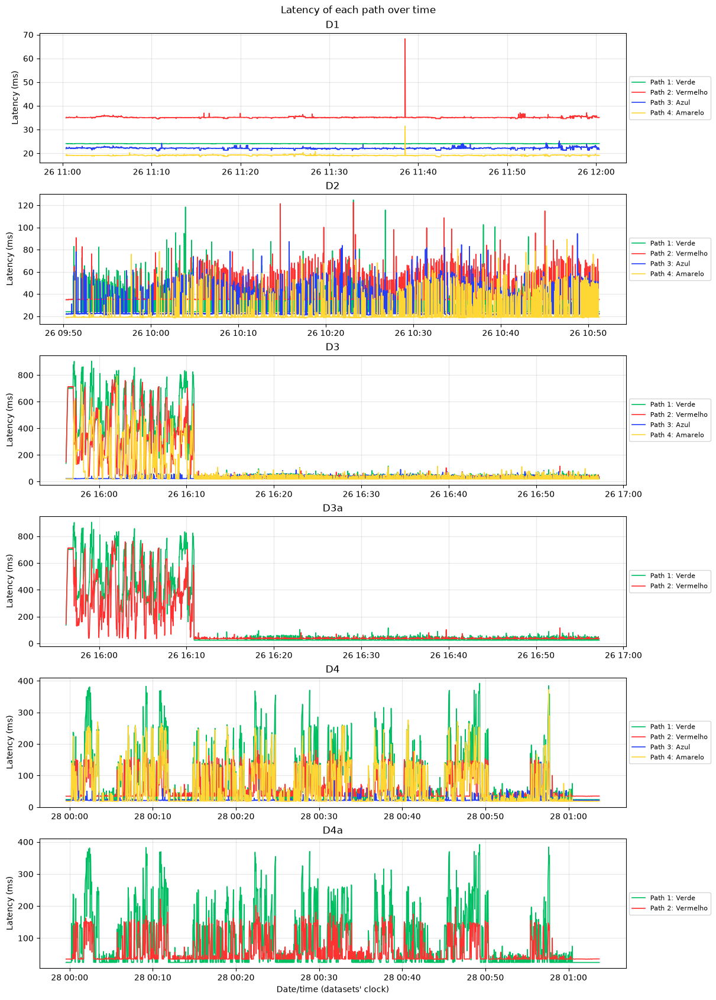

In [56]:
plot_route_metric_fs('latencia_ms', 'Latency (ms)', 'Latency of each path over time')

### Bandwidth of each path

Column *gargalo_Mbps__<route>* of **X**: the available bandwidth at the bottleneck link
of each path.

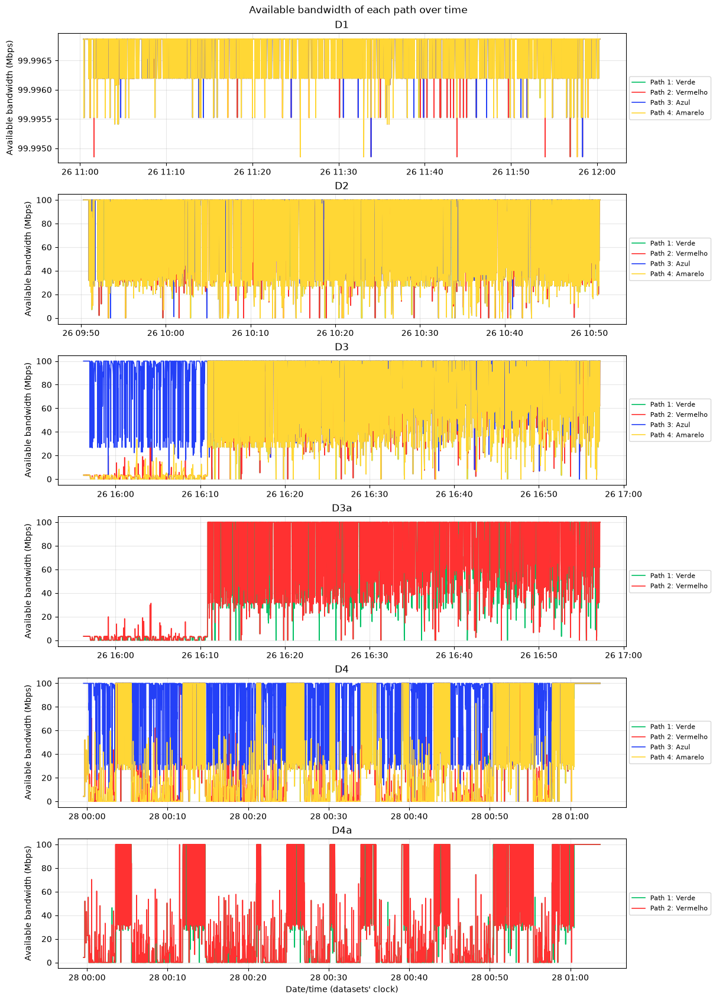

In [57]:
plot_route_metric_fs('gargalo_Mbps', 'Available bandwidth (Mbps)',
                     'Available bandwidth of each path over time')

### First rows of X

One row per instant and one column per feature and path. Only the first and last
columns are shown when there are many; the shape line gives the full size.

In [58]:
for dataset in datasets:
    wide = overview_frame_fs(dataset)
    # Named x_fs, not X, so the X of the older sections is left untouched
    x_fs = wide[pt.colunas_de_feature(wide)]
    x_fs.index = pd.to_datetime(wide['ts_epoch'], unit='s').rename('datetime')
    print(f'{dataset}: X has {x_fs.shape[0]} rows x {x_fs.shape[1]} columns '
          f'({len(path_ids_fs(wide))} paths)')
    display(x_fs.head())

D1: X has 3594 rows x 100 columns (4 paths)


,banda_delta_micro_longa__h11_h61,banda_delta_micro_longa__h12_h62,banda_delta_micro_longa__h13_h63,banda_delta_micro_longa__h14_h64,banda_media_Mbps__h11_h61,banda_media_Mbps__h12_h62,banda_media_Mbps__h13_h63,banda_media_Mbps__h14_h64,banda_media_curta_15s__h11_h61,banda_media_curta_15s__h12_h62,...,utilizacao_media_curta_15s__h13_h63,utilizacao_media_curta_15s__h14_h64,utilizacao_media_longa_30s__h11_h61,utilizacao_media_longa_30s__h12_h62,utilizacao_media_longa_30s__h13_h63,utilizacao_media_longa_30s__h14_h64,utilizacao_media_micro_5s__h11_h61,utilizacao_media_micro_5s__h12_h62,utilizacao_media_micro_5s__h13_h63,utilizacao_media_micro_5s__h14_h64
datetime,,,,,,,,,,,,,,,,,,,,,
2025-11-26 11:00:24,0.999968,0.999973,0.999973,0.999968,99.996864,99.996864,99.996864,99.996864,99.997038,99.997300,...,0.000028,0.000031,0.000031,0.000028,0.000028,0.000031,0.000031,0.000028,0.000028,0.000031
2025-11-26 11:00:25,0.999968,0.999974,0.999974,0.999968,99.997125,99.996864,99.996864,99.997021,99.997060,99.997191,...,0.000029,0.000031,0.000031,0.000029,0.000029,0.000031,0.000031,0.000029,0.000029,0.000031
2025-11-26 11:00:26,0.999968,0.999975,0.999975,0.999968,99.997125,99.996864,99.996864,99.997021,99.997073,99.997125,...,0.000030,0.000031,0.000031,0.000030,0.000030,0.000031,0.000031,0.000030,0.000030,0.000031
2025-11-26 11:00:27,0.999968,0.999975,0.999975,0.999968,99.996864,99.996864,99.996864,99.996864,99.997038,99.997082,...,0.000030,0.000031,0.000031,0.000030,0.000030,0.000031,0.000037,0.000036,0.000036,0.000037
2025-11-26 11:00:28,0.999987,0.999986,0.999987,0.999987,99.995781,99.995781,99.995520,99.995834,99.996859,99.996896,...,0.000032,0.000033,0.000033,0.000032,0.000032,0.000033,0.000034,0.000034,0.000034,0.000034


D2: X has 3656 rows x 100 columns (4 paths)


,banda_delta_micro_longa__h11_h61,banda_delta_micro_longa__h12_h62,banda_delta_micro_longa__h13_h63,banda_delta_micro_longa__h14_h64,banda_media_Mbps__h11_h61,banda_media_Mbps__h12_h62,banda_media_Mbps__h13_h63,banda_media_Mbps__h14_h64,banda_media_curta_15s__h11_h61,banda_media_curta_15s__h12_h62,...,utilizacao_media_curta_15s__h13_h63,utilizacao_media_curta_15s__h14_h64,utilizacao_media_longa_30s__h11_h61,utilizacao_media_longa_30s__h12_h62,utilizacao_media_longa_30s__h13_h63,utilizacao_media_longa_30s__h14_h64,utilizacao_media_micro_5s__h11_h61,utilizacao_media_micro_5s__h12_h62,utilizacao_media_micro_5s__h13_h63,utilizacao_media_micro_5s__h14_h64
datetime,,,,,,,,,,,,,,,,,,,,,
2025-11-26 09:50:18,0.999967,0.999975,0.999975,0.999967,99.997125,99.996864,99.996864,99.997021,99.997125,99.997163,...,0.000028,0.000031,0.000031,0.000028,0.000028,0.000031,0.000031,0.000028,0.000028,0.000031
2025-11-26 09:50:19,0.999968,0.999975,0.999975,0.999968,99.996864,99.996864,99.996864,99.996864,99.997060,99.997088,...,0.000029,0.000031,0.000031,0.000029,0.000029,0.000031,0.000031,0.000029,0.000029,0.000031
2025-11-26 09:50:20,0.999968,0.999975,0.999976,0.999968,99.996864,99.997125,99.996864,99.997021,99.997021,99.997095,...,0.000030,0.000031,0.000031,0.000030,0.000030,0.000031,0.000031,0.000030,0.000030,0.000031
2025-11-26 09:50:21,0.999968,0.999976,0.999976,0.999968,99.996867,99.996867,99.996867,99.996867,99.996995,99.997057,...,0.000030,0.000031,0.000031,0.000030,0.000030,0.000031,0.000037,0.000036,0.000036,0.000037
2025-11-26 09:50:22,0.999987,0.999979,0.999987,0.999979,99.995524,99.995263,99.995524,99.995368,99.996785,99.996801,...,0.000032,0.000034,0.000033,0.000033,0.000032,0.000034,0.000034,0.000036,0.000034,0.000036


D3: X has 3659 rows x 100 columns (4 paths)


,banda_delta_micro_longa__h11_h61,banda_delta_micro_longa__h12_h62,banda_delta_micro_longa__h13_h63,banda_delta_micro_longa__h14_h64,banda_media_Mbps__h11_h61,banda_media_Mbps__h12_h62,banda_media_Mbps__h13_h63,banda_media_Mbps__h14_h64,banda_media_curta_15s__h11_h61,banda_media_curta_15s__h12_h62,...,utilizacao_media_curta_15s__h13_h63,utilizacao_media_curta_15s__h14_h64,utilizacao_media_longa_30s__h11_h61,utilizacao_media_longa_30s__h12_h62,utilizacao_media_longa_30s__h13_h63,utilizacao_media_longa_30s__h14_h64,utilizacao_media_micro_5s__h11_h61,utilizacao_media_micro_5s__h12_h62,utilizacao_media_micro_5s__h13_h63,utilizacao_media_micro_5s__h14_h64
datetime,,,,,,,,,,,,,,,,,,,,,
2025-11-26 15:56:13,0.090945,0.041178,0.999974,0.043706,3.366960,67.779115,99.996864,61.349571,35.546062,78.506692,...,0.000028,0.644708,0.644745,0.644745,0.000028,0.644708,0.644745,0.644745,0.000028,0.644708
2025-11-26 15:56:14,0.117644,0.042638,0.999975,0.045693,3.277435,67.754539,99.996864,61.310602,27.478905,75.818653,...,0.000029,0.725329,0.725384,0.725384,0.000029,0.725329,0.725384,0.725384,0.000029,0.725329
2025-11-26 15:56:15,0.142309,0.043562,0.999976,0.046658,3.287963,67.777355,99.996864,61.303229,22.640717,74.210394,...,0.000030,0.773819,0.773864,0.773631,0.000030,0.773819,0.773864,0.773631,0.000030,0.773819
2025-11-26 15:56:16,0.165840,0.044201,0.999976,0.047542,3.365320,67.770746,99.996867,61.353611,19.428151,73.137119,...,0.000030,0.805946,0.806022,0.805828,0.000030,0.805946,0.967227,0.966994,0.000036,0.967135
2025-11-26 15:56:17,0.188031,0.045179,0.999987,0.048195,3.378408,67.807851,99.995524,61.337859,17.135330,72.375795,...,0.000032,0.828914,0.828979,0.828663,0.000032,0.828914,0.967036,0.966594,0.000034,0.966967


... (2 outputs left out)

D4: X has 3847 rows x 100 columns (4 paths)


,banda_delta_micro_longa__h11_h61,banda_delta_micro_longa__h12_h62,banda_delta_micro_longa__h13_h63,banda_delta_micro_longa__h14_h64,banda_media_Mbps__h11_h61,banda_media_Mbps__h12_h62,banda_media_Mbps__h13_h63,banda_media_Mbps__h14_h64,banda_media_curta_15s__h11_h61,banda_media_curta_15s__h12_h62,...,utilizacao_media_curta_15s__h13_h63,utilizacao_media_curta_15s__h14_h64,utilizacao_media_longa_30s__h11_h61,utilizacao_media_longa_30s__h12_h62,utilizacao_media_longa_30s__h13_h63,utilizacao_media_longa_30s__h14_h64,utilizacao_media_micro_5s__h11_h61,utilizacao_media_micro_5s__h12_h62,utilizacao_media_micro_5s__h13_h63,utilizacao_media_micro_5s__h14_h64
datetime,,,,,,,,,,,,,,,,,,,,,
2025-11-27 23:59:34,0.116029,0.053435,0.999922,0.056341,4.253627,68.084851,99.990598,61.691861,36.153483,78.714181,...,0.000086,0.638676,0.638676,0.638402,0.000086,0.638676,0.638676,0.638402,0.000086,0.638676
2025-11-27 23:59:35,0.148841,0.055302,0.999924,0.058861,4.273360,68.084854,99.990601,61.703705,28.183452,76.056849,...,0.000088,0.718324,0.718324,0.718118,0.000088,0.718324,0.718324,0.718118,0.000088,0.718324
2025-11-27 23:59:36,0.179238,0.056486,0.999926,0.060484,4.285264,68.088822,99.990601,61.708466,23.403814,74.463244,...,0.000089,0.766089,0.766089,0.765924,0.000089,0.766089,0.766089,0.765924,0.000089,0.766089
2025-11-27 23:59:37,0.207501,0.057303,0.999926,0.061617,4.277328,68.088822,99.990601,61.703705,20.216067,73.400840,...,0.000090,0.797951,0.797951,0.797794,0.000090,0.797951,0.957542,0.957353,0.000108,0.957542
2025-11-27 23:59:38,0.234251,0.058828,0.999961,0.062562,4.277269,68.084796,99.987096,61.702371,17.939096,72.641405,...,0.000096,0.820717,0.820717,0.820565,0.000096,0.820717,0.957393,0.957203,0.000102,0.957393


D4a: X has 3847 rows x 50 columns (2 paths)


,banda_delta_micro_longa__h11_h61,banda_delta_micro_longa__h12_h62,banda_media_Mbps__h11_h61,banda_media_Mbps__h12_h62,banda_media_curta_15s__h11_h61,banda_media_curta_15s__h12_h62,banda_media_longa_30s__h11_h61,banda_media_longa_30s__h12_h62,banda_media_micro_5s__h11_h61,banda_media_micro_5s__h12_h62,...,latencia_p95_micro_5s__h11_h61,latencia_p95_micro_5s__h12_h62,util_max_pct__h11_h61,util_max_pct__h12_h62,utilizacao_media_curta_15s__h11_h61,utilizacao_media_curta_15s__h12_h62,utilizacao_media_longa_30s__h11_h61,utilizacao_media_longa_30s__h12_h62,utilizacao_media_micro_5s__h11_h61,utilizacao_media_micro_5s__h12_h62
datetime,,,,,,,,,,,,,,,,,,,,,
2025-11-27 23:59:34,0.116029,0.053435,4.253627,68.084851,36.153483,78.714181,36.153483,78.714181,36.153483,78.714181,...,24.900023,36.277020,95.797744,95.726640,0.638676,0.638402,0.638676,0.638402,0.638676,0.638402
2025-11-27 23:59:35,0.148841,0.055302,4.273360,68.084854,28.183452,76.056849,28.183452,76.056849,28.183452,76.056849,...,24.886984,36.188755,95.726640,95.726640,0.718324,0.718118,0.718324,0.718118,0.718324,0.718118
2025-11-27 23:59:36,0.179238,0.056486,4.285264,68.088822,23.403814,74.463244,23.403814,74.463244,23.403814,74.463244,...,24.859412,36.113996,95.714736,95.714736,0.766089,0.765924,0.766089,0.765924,0.766089,0.765924
2025-11-27 23:59:37,0.207501,0.057303,4.277328,68.088822,20.216067,73.400840,20.216067,73.400840,4.259280,68.081008,...,24.831840,36.030234,95.726640,95.714736,0.797951,0.797794,0.797951,0.797794,0.957542,0.957353
2025-11-27 23:59:38,0.234251,0.058828,4.277269,68.084796,17.939096,72.641405,17.939096,72.641405,4.273370,68.086429,...,24.373194,34.672027,95.730672,95.718760,0.820717,0.820565,0.820717,0.820565,0.957393,0.957203


### First rows of y

`melhor_rota` is the pathId the model must predict at each instant (before any horizon
shift; scenario 1 moves it H seconds ahead).

In [59]:
for target in targets:
    first_y = {}
    for dataset in datasets:
        wide = overview_frame_fs(dataset, target)
        first_y[dataset] = pd.DataFrame({
            'datetime': pd.to_datetime(wide['ts_epoch'], unit='s'),
            'y': wide['melhor_rota'],
        }).head(10)
    print(f'target: {target}')
    display(pd.concat(first_y, axis=1))

target: lowest_latency


D1                     D2                     D3     \
             datetime  y            datetime  y            datetime  y   
0 2025-11-26 11:00:24  4 2025-11-26 09:50:18  4 2025-11-26 15:56:13  4   
1 2025-11-26 11:00:25  4 2025-11-26 09:50:19  4 2025-11-26 15:56:14  4   
2 2025-11-26 11:00:26  4 2025-11-26 09:50:20  4 2025-11-26 15:56:15  4   
3 2025-11-26 11:00:27  4 2025-11-26 09:50:21  4 2025-11-26 15:56:16  4   
4 2025-11-26 11:00:28  4 2025-11-26 09:50:22  4 2025-11-26 15:56:17  4   
5 2025-11-26 11:00:29  4 2025-11-26 09:50:23  4 2025-11-26 15:56:18  4   
6 2025-11-26 11:00:30  4 2025-11-26 09:50:24  4 2025-11-26 15:56:19  4   
7 2025-11-26 11:00:31  4 2025-11-26 09:50:25  4 2025-11-26 15:56:20  4   
8 2025-11-26 11:00:32  4 2025-11-26 09:50:26  4 2025-11-26 15:56:21  4   
9 2025-11-26 11:00:33  4 2025-11-26 09:50:27  4 2025-11-26 15:56:22  4   

                  D3a                     D4                    D4a     
             datetime  y            datetime  y            datetime  y  
0 2025-11-26 15:56:13  1 2025-11-27 23:59:34  4 2025-11-27 23:59:34  1  
1 2025-11-26 15:56:14  1 2025-11-27 23:59:35  4 2025-11-27 23:59:35  1  
2 2025-11-26 15:56:15  1 2025-11-27 23:59:36  4 2025-11-27 23:59:36  1  
3 2025-11-26 15:56:16  1 2025-11-27 23:59:37  4 2025-11-27 23:59:37  1  
4 2025-11-26 15:56:17  1 2025-11-27 23:59:38  4 2025-11-27 23:59:38  1  
5 2025-11-26 15:56:18  1 2025-11-27 23:59:39  4 2025-11-27 23:59:39  1  
6 2025-11-26 15:56:19  1 2025-11-27 23:59:40  4 2025-11-27 23:59:40  1  
7 2025-11-26 15:56:20  1 2025-11-27 23:59:41  4 2025-11-27 23:59:41  1  
8 2025-11-26 15:56:21  1 2025-11-27 23:59:42  4 2025-11-27 23:59:42  1  
9 2025-11-26 15:56:22  1 2025-11-27 23:59:43  4 2025-11-27 23:59:43  1

### PathIds and their distribution

Which paths each dataset has, and how often each one is the best path over the whole
series. The split into training and test blocks comes in the next section.

target: lowest_latency


,pathIds,pathIds in y,instants,Path 1: Verde,Path 2: Vermelho,Path 3: Azul,Path 4: Amarelo
dataset,,,,,,,
D1,"[1, 2, 3, 4]","[3, 4]",3594,0 (0.0%),0 (0.0%),2 (0.1%),3592 (99.9%)
D2,"[1, 2, 3, 4]","[1, 2, 3, 4]",3656,196 (5.4%),13 (0.4%),400 (10.9%),3047 (83.3%)
D3,"[1, 2, 3, 4]","[1, 2, 3, 4]",3659,332 (9.1%),48 (1.3%),1373 (37.5%),1906 (52.1%)
D3a,"[1, 2]","[1, 2]",3659,2532 (69.2%),1127 (30.8%),-,-
D4,"[1, 2, 3, 4]","[1, 2, 3, 4]",3847,37 (1.0%),18 (0.5%),1848 (48.0%),1944 (50.5%)
D4a,"[1, 2]","[1, 2]",3847,2016 (52.4%),1831 (47.6%),-,-


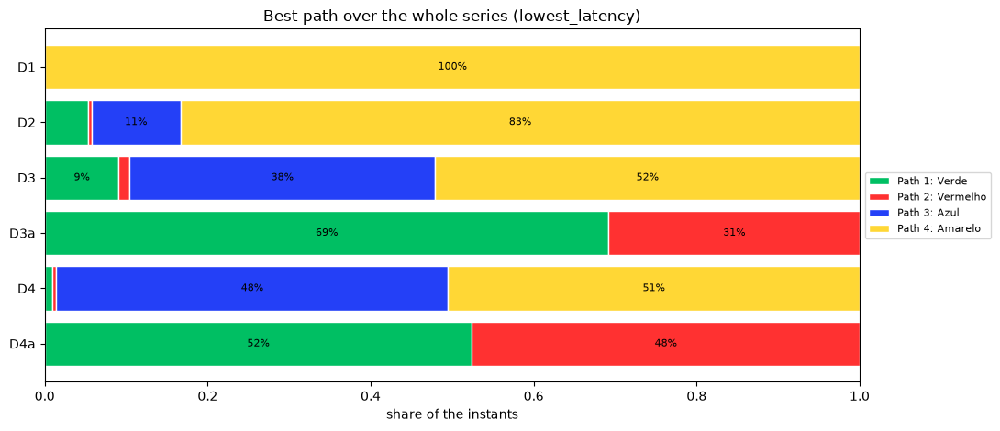

In [60]:
for target in targets:
    rows, shares = [], {}
    for dataset in datasets:
        wide = overview_frame_fs(dataset, target)
        path_ids = path_ids_fs(wide)
        counts = wide['melhor_rota'].value_counts().reindex(path_ids, fill_value=0)
        shares[dataset] = counts / counts.sum()
        row = {'dataset': dataset, 'pathIds': path_ids,
               'pathIds in y': sorted(int(p) for p in wide['melhor_rota'].unique()),
               'instants': int(counts.sum())}
        for path_id in path_ids:
            row[path_label_fs(path_id)] = f'{counts[path_id]} ({shares[dataset][path_id]:.1%})'
        rows.append(row)

    print(f'target: {target}')
    display(pd.DataFrame(rows).set_index('dataset').fillna('-'))

    # One stacked bar per dataset, each path in its colour
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(datasets) + 1.5))
    for position, (dataset, share) in enumerate(shares.items()):
        left = 0.0
        for path_id, value in share.items():
            ax.barh(position, value, left=left, color=rotas[path_id]['cor'],
                    edgecolor='white', label=path_label_fs(path_id))
            if value >= 0.06:
                ax.text(left + value / 2, position, f'{value:.0%}',
                        ha='center', va='center', fontsize=8)
            left += value
    ax.set_yticks(range(len(shares)), list(shares))
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel('share of the instants')
    ax.set_title(f'Best path over the whole series ({target})')
    handles, names = ax.get_legend_handles_labels()
    unique = dict(zip(names, handles))
    ax.legend(unique.values(), unique.keys(), loc='center left',
              bbox_to_anchor=(1.0, 0.5), fontsize=8)
    plt.tight_layout()
    plt.show()

## Joint analysis of the datasets

This section presents what each dataset gives the models to learn.

The first table shows the target at the reference horizon, over the whole series and over each
chronological block. It uses the same protocol as the evaluation, on the rows of the first feature set. A dataset where one route is best in almost every instant has little to predict. When the dominant route changes between train and test, the majority-class baseline measures the
regime shift rather than the imbalance.

The second table shows how much the features of each set actually vary. A column
whose coefficient of variation is below *VARIATION_THRESHOLD* is constant up to
numerical noise, and *StandardScaler* would promote that noise to unit variance.
This happens to the bandwidth of the idle scenario (D1). The table only flags those
columns; it never drops one.

The graph shows the label distribution on each block (train vs test).

In [53]:
def blocks_fs(wide, horizon_s, fraction=TRAIN_FRACTION):
    """Shifted frame and chronological masks, with the drop messages silenced."""
    with contextlib.redirect_stdout(io.StringIO()):
        frame, train, test = pt.preparar_treino_teste(wide, horizon_s, fracao_treino=fraction)
    return frame, train.to_numpy(), test.to_numpy()


def class_summary_fs(target, dataset, horizon_s=H_REF, feature_set=feature_sets[0]):
    frame, train, test = blocks_fs(WIDE_FS[target][(dataset, feature_set)], horizon_s)
    y = frame['melhor_rota'].astype(int)
    row = {'dataset': dataset}
    for name, block in {'full': y, 'train': y[train], 'test': y[test]}.items():
        shares = block.value_counts(normalize=True)
        row[f'{name} n'] = len(block)
        row[f'{name} classes'] = block.nunique()
        row[f'{name} dominant route'] = int(shares.idxmax())
        row[f'{name} dominant %'] = round(100 * shares.max(), 2)
    row['dominant route changes'] = row['train dominant route'] != row['test dominant route']
    return row


def route_shares_fs(target, dataset, horizon_s=H_REF, feature_set=feature_sets[0]):
    frame, train, test = blocks_fs(WIDE_FS[target][(dataset, feature_set)], horizon_s)
    y = frame['melhor_rota'].astype(int)
    return {name: block.value_counts(normalize=True)
            for name, block in {'train': y[train], 'test': y[test]}.items()}


def variation_fs(wide):
    values = wide[pt.colunas_de_feature(wide)]
    return (values.std() / values.mean().abs()).replace([np.inf, -np.inf], np.nan)


class_summary_table_fs, variation_table_fs = {}, {}
for target in targets:
    class_summary_table_fs[target] = pd.DataFrame(
        [class_summary_fs(target, d) for d in datasets]).set_index('dataset')
    class_summary_table_fs[target].to_csv(
        RESULTS_DIR[target] / f'class_distribution_H{H_REF}.csv')

    variation_rows = []
    for (dataset, feature_set), wide in WIDE_FS[target].items():
        cv = variation_fs(wide)
        flagged = cv.index[(cv < VARIATION_THRESHOLD) | cv.isna()]
        variation_rows.append({
            'dataset': dataset, 'feature set': feature_set,
            'columns of X': len(cv), 'constant up to noise': len(flagged),
            'cv min': cv.min(), 'cv median': cv.median(),
            'flagged features': sorted({c.split('__')[0] for c in flagged}),
        })
    variation_table_fs[target] = pd.DataFrame(variation_rows).set_index(['dataset', 'feature set'])
    variation_table_fs[target].to_csv(RESULTS_DIR[target] / 'feature_variation.csv')

    print(f'=== target: {target} ===')
    print(f'Target at H={H_REF}s (rows of {feature_sets[0]!r}):')
    display(class_summary_table_fs[target])
    print('Variation of the features:')
    display(variation_table_fs[target])

=== target: lowest_latency ===
Target at H=30s (rows of 'store: bandwidth features'):


,full n,full classes,full dominant route,full dominant %,train n,train classes,train dominant route,train dominant %,test n,test classes,test dominant route,test dominant %,dominant route changes
dataset,,,,,,,,,,,,,
D1,3561,2,4,99.94,2849,2,4,99.93,682,1,4,100.00,False
D2,3624,4,4,83.22,2900,4,4,86.24,695,4,4,71.51,False
D3,3627,4,4,51.72,2902,4,4,49.31,695,4,4,61.58,False
D3a,3627,2,1,68.96,2902,2,1,66.99,695,2,1,77.84,False
D4,3816,4,4,50.13,3053,4,3,53.98,733,4,4,71.49,True
D4a,3816,2,1,52.04,3053,2,2,52.93,733,2,1,72.44,True


Variation of the features:


columns of X  constant up to noise  \
dataset feature set                                                     
D1      store: bandwidth features            56                    36   
        store: latency features              44                     0   
        store: all features                 100                    36   
D2      store: bandwidth features            56                     0   
        store: latency features              44                     0   
        store: all features                 100                     0   
D3      store: bandwidth features            56                     0   
        store: latency features              44                     0   
        store: all features                 100                     0   
D3a     store: bandwidth features            28                     0   
        store: latency features              22                     0   
        store: all features                  50                     0   
D4      store: bandwidth features            56                     0   
        store: latency features              44                     0   
        store: all features                 100                     0   
D4a     store: bandwidth features            28                     0   
        store: latency features              22                     0   
        store: all features                  50                     0   

                                         cv min  cv median  \
dataset feature set                                          
D1      store: bandwidth features  2.517758e-07   0.000004   
        store: latency features    1.505561e-03   0.018117   
        store: all features        2.455600e-07   0.010617   
D2      store: bandwidth features  1.899067e-02   0.418981   
        store: latency features    6.178261e-02   0.334243   
        store: all features        1.896915e-02   0.385825   
D3      store: bandwidth features  1.955136e-02   0.690682   
        store: latency features    7.229787e-02   1.402119   
        store: all features        1.953069e-02   0.844815   
D3a     store: bandwidth features  1.415681e-01   0.818384   
        store: latency features    1.298544e+00   1.464143   
        store: all features        1.415870e-01   0.970707   
D4      store: bandwidth features  2.475153e-02   0.650515   
        store: latency features    6.746047e-02   0.736149   
        store: all features        2.473928e-02   0.708989   
D4a     store: bandwidth features  1.708309e-01   1.023429   
        store: latency features    4.216696e-01   0.728418   
        store: all features        1.708478e-01   0.772977   

                                                                                                                                                                                                                    flagged features  
dataset feature set                                                                                                                                                                                                                   
D1      store: bandwidth features  [banda_delta_micro_longa, banda_media_Mbps, banda_media_curta_15s, banda_media_longa_30s, banda_media_micro_5s, gargalo_Mbps, gargalo_min_curta_15s, gargalo_min_longa_30s, gargalo_min_micro_5s]  
        store: latency features                                                                                                                                                                                                   []  
        store: all features        [banda_delta_micro_longa, banda_media_Mbps, banda_media_curta_15s, banda_media_longa_30s, banda_media_micro_5s, gargalo_Mbps, gargalo_min_curta_15s, gargalo_min_longa_30s, gargalo_min_micro_5s]  
D2      store: bandwidth features                                                                                                                                                 

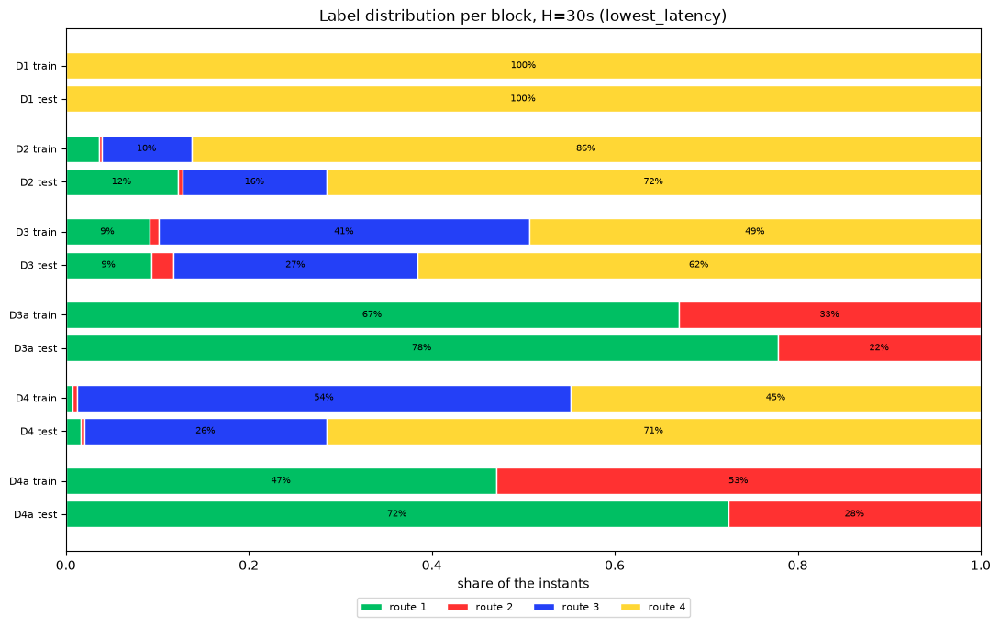

In [62]:
# Share of each route in the training and test blocks, one bar pair per dataset
for target in targets:
    plot_block_shares_fs({dataset: route_shares_fs(target, dataset) for dataset in datasets},
                         f'Label distribution per block, H={H_REF}s ({target})',
                         path=RESULTS_DIR[target] / f'class_distribution_H{H_REF}.png')

## Model evaluation, dataset by dataset

The loop below runs both scenarios for every dataset and every feature set:

**Scenario 1: horizon sweep.** For each **H** in *horizons*, the target label is shifted to *t + H* and cuts each dataset chronologically (first 80% to train, last 20% to test, with a gap of H seconds between them). Every model is trained *once* on the whole training block and measured on the whole test block. It is then compared to to the two baselines: **persistence** (the best route in H seconds is the best route now) and the **majority class** of the training block.

**Scenario 2: training window W.** The models are trained only on the last **W** seconds, instead of the whole training set. A window holds at most W samples, fewer where the series has gaps. Over a few seconds the best route rarely changes, so many windows hold a single label. Those windows predict that label directly, for every model, since most classifiers cannot be fitted on one class. For that reason the **window majority** (the most frequent label of the window) is reported as a third baseline: it is what a sliding-window learner gets without using X. Only one test instant every WINDOW_STEP seconds is evaluated,
because every one of them refits every model.

A training block with a single class makes some models fail; they get `NaN`
instead of stopping the loop.

In [55]:
def make_pipelines_fs(names=evaluated_models, random_state=RANDOM_STATE, n_jobs=-1,
                      n_samples=None):
    """The 7 classifiers of the predictive section, each preceded by a StandardScaler.

    n_samples: size of the training set when it is known to be small (scenario 2);
    KNN cannot ask for more neighbours than there are samples.
    """
    neighbours = 5 if n_samples is None else max(1, min(5, n_samples))
    catalogue = {
        'LogisticRegression': lambda: LogisticRegression(max_iter=1000),
        'KNeighbors': lambda: KNeighborsClassifier(n_neighbors=neighbours),
        'SVC': lambda: svm.SVC(random_state=random_state),
        'DecisionTree': lambda: tree.DecisionTreeClassifier(random_state=random_state),
        'ExtraTrees': lambda: ExtraTreesClassifier(random_state=random_state, n_jobs=n_jobs),
        'RandomForest': lambda: RandomForestClassifier(random_state=random_state, n_jobs=n_jobs),
        'GaussianNB': lambda: GaussianNB(var_smoothing=VAR_SMOOTHING),
    }
    return {name: Pipeline([('scaler', StandardScaler()), ('classifier', catalogue[name]())])
            for name in names}


def evaluate_full_block_fs(wide, horizon_s, evaluated_models=evaluated_models):
    """Scenario 1: train once on the training block, measure on the test block."""
    frame, train, test = blocks_fs(wide, horizon_s)
    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
    X_train, y_train, X_test, y_test = X[train], y[train], X[test], y[test]

    rows = []
    for name, model in make_pipelines_fs(evaluated_models).items():
        try:
            y_pred = model.fit(X_train, y_train).predict(X_test)
            accuracy = accuracy_score(y_test, y_pred)
            f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
        except ValueError as error:
            print(f'    {name}: not trained ({error})')
            accuracy = f1 = np.nan
        rows.append({'model': name, 'accuracy': accuracy, 'f1_macro': f1})

    majority_class = int(pd.Series(y_train).value_counts().idxmax())
    return {
        'results': pd.DataFrame(rows),
        'persistence': float((current[test] == y_test).mean()),
        'majority': float((y_test == majority_class).mean()),
        'n_train': len(y_train),
        'n_test': len(y_test),
    }


def evaluate_window_instant_fs(X_window, y_window, x_now, evaluated_models=evaluated_models):
    """Predictions of every model retrained on one window, plus the window majority."""
    labels, counts = np.unique(y_window, return_counts=True)
    majority = int(labels[counts.argmax()])  # a tie goes to the lowest route number
    out = {'window_majority': majority, 'single_class': len(labels) == 1, 'fallback': 0}

    for name, model in make_pipelines_fs(evaluated_models, n_jobs=1, n_samples=len(y_window)).items():
        if len(labels) == 1:
            out[name] = majority
            continue
        try:
            out[name] = int(model.fit(X_window, y_window).predict(x_now[None, :])[0])
        except ValueError:
            # e.g. a class with too few samples for the model; counted, not hidden
            out[name] = majority
            out['fallback'] += 1
    return out


def run_training_window_sweep_fs(wide, horizons_s, window_sizes=windows,
                                 step_s=WINDOW_STEP, evaluated_models=evaluated_models,
                                 n_jobs=N_JOBS):
    """Scenario 2 for several horizons at once, in a single Parallel call.

    Same cases and same rows, in the same order, as calling run_training_window_fs
    once per horizon; only the scheduling changes. One Parallel call per window size
    left the cores idle while the slowest window of each call finished, 99 times per
    feature set. The windows are sliced lazily, so the pending cases do not hold
    copies of X.
    """
    ordered = wide.sort_values(['dataset_id', 'ts_epoch']).reset_index(drop=True)

    arrays, cases = {}, []  # case: (H, dataset, W, evaluated instant, window positions)
    for H in horizons_s:
        frame, _, test = blocks_fs(ordered, H)
        X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
        y = frame['melhor_rota'].to_numpy(dtype=int)
        current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
        ts = frame['ts_epoch'].to_numpy()
        arrays[H] = (X, y, current, ts)
        # Last instant whose label is known at t: t - H, or t - 1 when H = 0
        last_known = max(H, 1)

        for dataset, positions in frame.groupby('dataset_id').indices.items():
            positions = positions[np.argsort(ts[positions])]
            ts_d = ts[positions]
            evaluated = positions[test[positions]][::step_s]

            for W in window_sizes:
                for i in evaluated:
                    upper = ts[i] - last_known
                    start = np.searchsorted(ts_d, upper - W, side='right')
                    stop = np.searchsorted(ts_d, upper, side='right')
                    if stop > start:
                        cases.append((H, dataset, W, i, positions[start:stop]))

    def tasks():
        for H, _, _, i, w in cases:
            X, y, _, _ = arrays[H]
            yield delayed(evaluate_window_instant_fs)(X[w], y[w], X[i], evaluated_models)

    outputs = Parallel(n_jobs=n_jobs)(tasks())

    rows = []
    for (H, dataset, W, i, w), out in zip(cases, outputs):
        _, y, current, ts = arrays[H]
        rows.append({'horizon_s': H, 'dataset': dataset, 'ts_epoch': int(ts[i]),
                     'window_s': W, 'n_train': len(w), 'y_true': int(y[i]),
                     'persistence': int(current[i]), **out})
    return pd.DataFrame(rows)


def run_training_window_fs(wide, horizon_s, window_sizes=windows,
                           step_s=WINDOW_STEP, evaluated_models=evaluated_models,
                           n_jobs=N_JOBS):
    """Scenario 2: one prediction per evaluated test instant, model and window size."""
    return run_training_window_sweep_fs(
        wide, [horizon_s], window_sizes, step_s, evaluated_models, n_jobs
    ).drop(columns='horizon_s')


In [64]:
import hashlib
import pickle

# Results of each (dataset, feature set) are cached on disk, so a run stopped in the
#   middle (or a restarted kernel) resumes where it stopped instead of starting over.
#   The file name holds a hash of the input frame and of every parameter below, so a
#   new parameter value or regenerated dataset is computed again on its own. A change
#   to the code of the models or of the loop is not detected: set RECOMPUTE_FS = True
#   (or delete the cache folder) after such a change.
RECOMPUTE_FS = False
CACHE_DIR_FS = {target: folder / 'cache' for target, folder in RESULTS_DIR.items()}


def cache_path_fs(target, dataset, feature_set, wide):
    settings = repr((target, dataset, feature_set, list(horizons), list(windows), WINDOW_STEP,
                     list(evaluated_models), TRAIN_FRACTION, RANDOM_STATE, VAR_SMOOTHING))
    digest = hashlib.sha1(settings.encode())
    digest.update(pd.util.hash_pandas_object(wide, index=True).to_numpy().tobytes())
    digest.update(repr(list(wide.columns)).encode())
    name = re.sub(r'[^A-Za-z0-9]+', '_', feature_set).strip('_')
    return CACHE_DIR_FS[target] / f'{dataset}__{name}__{digest.hexdigest()[:12]}.pkl'


def evaluate_case_fs(wide, dataset, feature_set):
    """Both scenarios for one (dataset, feature set), as the loop below stores them."""
    sweep_rows, baseline_rows = [], []

    # Scenario 1: horizon sweep, whole training block
    for H in horizons:
        result = evaluate_full_block_fs(wide, H)
        sweep_rows.append(result['results'].assign(
            dataset=dataset, feature_set=feature_set, horizon_s=H))
        baseline_rows.append({
            'dataset': dataset, 'feature_set': feature_set, 'horizon_s': H,
            'persistence': result['persistence'], 'majority': result['majority'],
            'n_train': result['n_train'], 'n_test': result['n_test'],
        })

    # Scenario 2: sliding training window, every horizon in one Parallel call
    window = run_training_window_sweep_fs(wide, horizons)
    window.insert(0, 'feature_set', feature_set)
    return {'sweep_rows': sweep_rows, 'baseline_rows': baseline_rows, 'window': window}


sweep_fs, sweep_baselines_fs, window_predictions_fs = {}, {}, {}

for target in targets:
    CACHE_DIR_FS[target].mkdir(parents=True, exist_ok=True)
    sweep_rows, baseline_rows, window_parts = [], [], []
    for dataset in datasets:
        for feature_set in feature_sets:
            wide = WIDE_FS[target][(dataset, feature_set)]
            started = time.time()

            cache = cache_path_fs(target, dataset, feature_set, wide)
            if cache.is_file() and not RECOMPUTE_FS:
                with open(cache, 'rb') as f:
                    case = pickle.load(f)
                source = 'cached'
            else:
                case = evaluate_case_fs(wide, dataset, feature_set)
                with open(cache.with_suffix('.tmp'), 'wb') as f:
                    pickle.dump(case, f)
                cache.with_suffix('.tmp').replace(cache)  # never a half-written cache
                source = 'computed'
            sweep_rows.extend(case['sweep_rows'])
            baseline_rows.extend(case['baseline_rows'])
            window_parts.append(case['window'])

            print(f'{target:24s} | {dataset:4s} | {feature_set:26s} | '
                  f'{len(pt.colunas_de_feature(wide)):3d} columns | {len(wide):5d} instants '
                  f'| {time.time() - started:6.1f} s ({source})')

    sweep_fs[target] = pd.concat(sweep_rows, ignore_index=True)[
        ['dataset', 'feature_set', 'horizon_s', 'model', 'accuracy', 'f1_macro']]
    sweep_baselines_fs[target] = pd.DataFrame(baseline_rows)
    window_predictions_fs[target] = pd.concat(window_parts, ignore_index=True)

    results_dir = RESULTS_DIR[target]
    sweep_fs[target].to_csv(results_dir / 'sweep_accuracy.csv', index=False)
    sweep_baselines_fs[target].to_csv(results_dir / 'sweep_baselines.csv', index=False)
    window_predictions_fs[target].to_csv(results_dir / 'window_predictions.csv', index=False)
    print(f'saved to {results_dir}')

lowest_latency           | D1   | store: bandwidth features  |  56 columns |  3595 instants |    0.0 s (cached)
lowest_latency           | D1   | store: latency features    |  44 columns |  3594 instants |    0.0 s (cached)
lowest_latency           | D1   | store: all features        | 100 columns |  3594 instants |    0.0 s (cached)
lowest_latency           | D2   | store: bandwidth features  |  56 columns |  3657 instants | 1239.7 s (computed)
lowest_latency           | D2   | store: latency features    |  44 columns |  3656 instants | 1195.8 s (computed)
lowest_latency           | D2   | store: all features        | 100 columns |  3656 instants | 1386.6 s (computed)
lowest_latency           | D3   | store: bandwidth features  |  56 columns |  3660 instants | 1246.2 s (computed)
lowest_latency           | D3   | store: latency features    |  44 columns |  3659 instants | 1228.7 s (computed)
lowest_latency           | D3   | store: all features        | 100 columns |  3659 instants | 

## Scenario 1: horizon sweep

The test accuracy of **every model** for each `(dataset, feature set, H)`, next to
the two baselines. One table per dataset: rows are the feature sets and, inside
each, the 7 models followed by the baselines (grey italics); columns are the
horizons `H`.

How to read the colours (per feature set and column):
- **green**: the model beats both baselines;
- **red**: the model does worse than persistence;
- **bold**: the best model.

The success criterion is not the absolute accuracy but the **gain over
persistence**: a model that does not beat "the best route in `H` seconds is the
best route now" does not predict anything a reactive controller would not get for
free. At `H = 0` persistence is 1.0 by construction, so that column is red for
every model and only isolates the effect of the chronological split.

The figure below the tables shows the same numbers as curves, one panel per
dataset and feature set.

In [65]:
_keys_fs = ['dataset', 'feature_set', 'horizon_s']
SWEEP_BASELINES_FS = ['persistence', 'majority']

best_fs, sweep_long_fs = {}, {}
for target in targets:
    # Best model of each case: kept for sweep_best_model.csv and the later sections
    best = (sweep_fs[target].dropna(subset=['accuracy'])
            .sort_values('accuracy', ascending=False)
            .drop_duplicates(_keys_fs)
            .merge(sweep_baselines_fs[target], on=_keys_fs)
            .rename(columns={'model': 'best model'}))
    best['gain over persistence'] = best['accuracy'] - best['persistence']
    best_fs[target] = best.set_index(_keys_fs).sort_index().reindex(datasets, level=0)
    best_fs[target].to_csv(RESULTS_DIR[target] / 'sweep_best_model.csv')

    # Every model and both baselines, one row per (case, predictor)
    sweep_long_fs[target] = every_model_long_fs(
        sweep_fs[target], sweep_baselines_fs[target][_keys_fs + SWEEP_BASELINES_FS], _keys_fs)

    print(f'=== target: {target} ===')
    for dataset in datasets:
        long = sweep_long_fs[target]
        table = every_model_table_fs(long[long.dataset == dataset], 'horizon_s',
                                     evaluated_models, SWEEP_BASELINES_FS, feature_sets)
        display(style_every_model_fs(
            table, evaluated_models, SWEEP_BASELINES_FS,
            f'{dataset} | test accuracy by horizon H (s), whole training block'))

=== target: lowest_latency ===


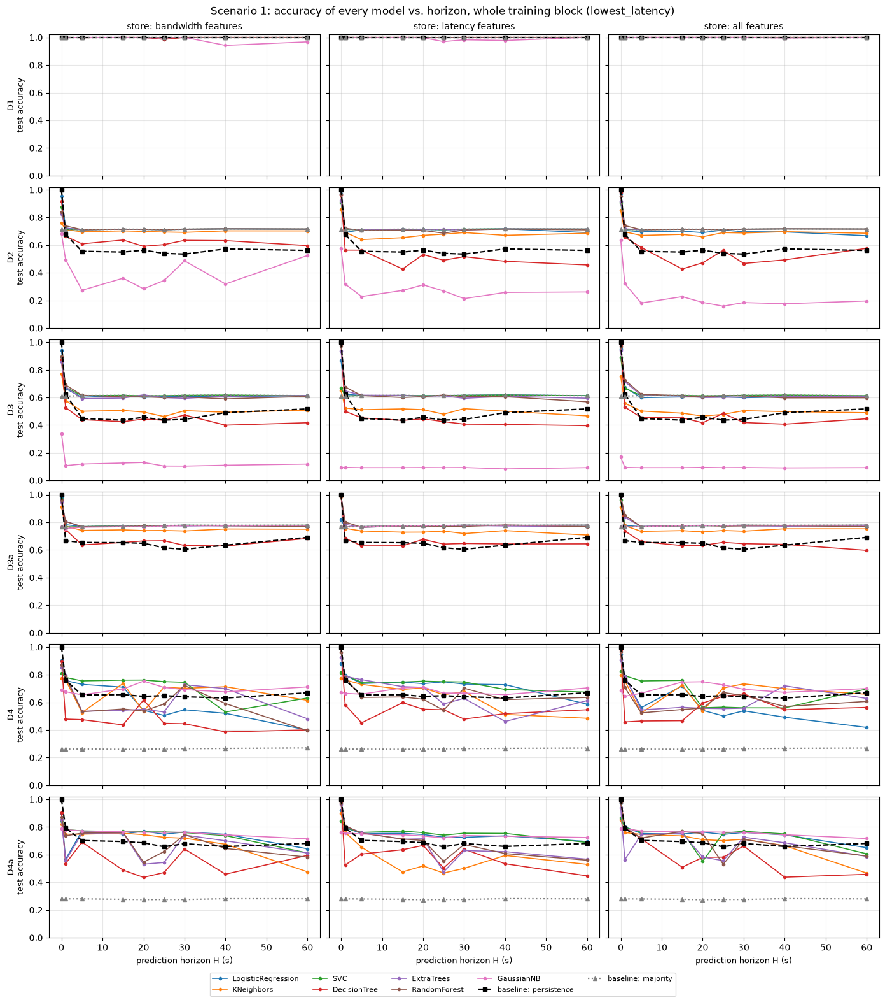

In [66]:
for target in targets:
    plot_every_model_fs(
        sweep_long_fs[target], 'horizon_s', evaluated_models, SWEEP_BASELINES_FS,
        datasets, feature_sets,
        f'Scenario 1: accuracy of every model vs. horizon, whole training block ({target})',
        'prediction horizon H (s)',
        path=RESULTS_DIR[target] / 'sweep_every_model.png')

### Scenario 1: confusion matrices and metrics beyond accuracy

Accuracy hides the class imbalance: in a dataset where one route is best in 70% of
the instants, a model that always answers that route scores 0.70. The metrics below
do not reward that:

| metric | what it measures | always predicting the majority route gives |
|---|---|---|
| `balanced_accuracy` | mean recall over the routes present in the test block | 1 / number of routes |
| `precision_macro`, `recall_macro`, `f1_macro` | mean over the routes, each route weighing the same | low, since the minority routes score 0 |
| `mcc` | Matthews correlation between predicted and actual routes, from −1 to 1 | 0 |

The loop of scenario 1 only kept accuracy and F1-macro, so the cell below retrains
the same models on the same blocks, this time keeping every prediction. The two
baselines are scored as predictors too, on the same instants: **persistence**
(the route of `t`) and the **majority class** of the training block. A check at the
end confirms that the retrained models reproduce the accuracies of the loop.

When the test block holds a single route (D1), `mcc` is undefined and scikit-learn reports 0 even for a perfect model; read D1 on the other metrics.

In [67]:
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef

# Horizons retrained here; list(horizons) reproduces the whole sweep
PREDICTION_HORIZONS_FS = list(horizons)

METRICS_FS = ['accuracy', 'balanced_accuracy', 'precision_macro', 'recall_macro',
              'f1_macro', 'mcc']
BASELINES_FS = ['persistence', 'majority']


def classification_metrics_fs(y_true, y_pred):
    """Every metric of METRICS_FS for one set of predictions."""
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision_macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'mcc': matthews_corrcoef(y_true, y_pred),
    }


def predict_full_block_fs(wide, horizon_s, evaluated_models=evaluated_models):
    """Scenario 1 again, returning one row per test instant with every prediction.

    Same blocks and same models as evaluate_full_block_fs. A model that cannot be
    trained (single-class training block) gets NaN predictions.
    """
    frame, train, test = blocks_fs(wide, horizon_s)
    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
    majority_class = int(pd.Series(y[train]).value_counts().idxmax())

    out = pd.DataFrame({
        'ts_epoch': frame['ts_epoch'].to_numpy()[test],
        'y_true': y[test],
        'persistence': current[test],
        'majority': majority_class,
    })
    for name, model in make_pipelines_fs(evaluated_models).items():
        try:
            out[name] = model.fit(X[train], y[train]).predict(X[test])
        except ValueError as error:
            print(f'    {name}: not trained ({error})')
            out[name] = np.nan
    return out


sweep_predictions_fs = {}
for target in targets:
    parts = []
    for dataset in datasets:
        started = time.time()
        for feature_set in feature_sets:
            for H in PREDICTION_HORIZONS_FS:
                part = predict_full_block_fs(WIDE_FS[target][(dataset, feature_set)], H)
                part.insert(0, 'horizon_s', H)
                part.insert(0, 'feature_set', feature_set)
                part.insert(0, 'dataset', dataset)
                parts.append(part)
        print(f'{target:24s} | {dataset:4s} | {time.time() - started:6.1f} s')

    sweep_predictions_fs[target] = pd.concat(parts, ignore_index=True)
    sweep_predictions_fs[target].to_csv(RESULTS_DIR[target] / 'sweep_predictions.csv',
                                        index=False)


def metrics_table_fs(predictions, keys, predictors):
    """One row per (case, predictor) with every metric of METRICS_FS."""
    rows = []
    for case, group in predictions.groupby(keys):
        case = dict(zip(keys, case if isinstance(case, tuple) else (case,)))
        for predictor in predictors:
            valid = group[predictor].notna()
            if not valid.any():
                continue
            rows.append({**case, 'predictor': predictor, 'instants': int(valid.sum()),
                         **classification_metrics_fs(group.y_true[valid],
                                                     group[predictor][valid].astype(int))})
    return pd.DataFrame(rows)


sweep_metrics_fs = {}
for target in targets:
    metrics = metrics_table_fs(sweep_predictions_fs[target],
                               ['dataset', 'feature_set', 'horizon_s'],
                               evaluated_models + BASELINES_FS)
    sweep_metrics_fs[target] = metrics
    metrics.to_csv(RESULTS_DIR[target] / 'sweep_metrics.csv', index=False)

    # The retrained models must reproduce the accuracies of the loop
    check = metrics.merge(
        sweep_fs[target].rename(columns={'model': 'predictor', 'accuracy': 'loop_accuracy'}),
        on=['dataset', 'feature_set', 'horizon_s', 'predictor'])
    print(f'=== target: {target} ===')
    print(f'largest accuracy difference against the loop: '
          f'{(check.accuracy - check.loop_accuracy).abs().max():.2e} '
          f'over {len(check)} cases')

    print(f'Every metric at the reference horizon H={H_REF}s:')
    display(metrics[metrics.horizon_s == H_REF]
            .set_index(['dataset', 'feature_set', 'predictor'])[METRICS_FS]
            .reindex(datasets, level=0).round(3))

lowest_latency           | D1   |   14.4 s
lowest_latency           | D2   |   55.6 s
lowest_latency           | D3   |   78.9 s
lowest_latency           | D3a  |   27.2 s
lowest_latency           | D4   |   70.2 s
lowest_latency           | D4a  |   29.0 s
=== target: lowest_latency ===
largest accuracy difference against the loop: 0.00e+00 over 1134 cases
Every metric at the reference horizon H=30s:


accuracy  \
dataset feature_set             predictor                      
D1      store: all features     LogisticRegression     1.000   
                                KNeighbors             1.000   
                                SVC                    1.000   
                                DecisionTree           1.000   
                                ExtraTrees             1.000   
...                                                      ...   
D4a     store: latency features ExtraTrees             0.630   
                                RandomForest           0.673   
                                GaussianNB             0.739   
                                persistence            0.680   
                                majority               0.276   

                                                    balanced_accuracy  \
dataset feature_set             predictor                               
D1      store: all features     LogisticRegression              1.000   
                                KNeighbors                      1.000   
                                SVC                             1.000   
                                DecisionTree                    1.000   
                                ExtraTrees                      1.000   
...                                                               ...   
D4a     store: latency features ExtraTrees                      0.550   
                                RandomForest                    0.591   
                                GaussianNB                      0.582   
                                persistence                     0.609   
                                majority                        0.500   

                                                    precision_macro  \
dataset feature_set             predictor                             
D1      store: all features     LogisticRegression            1.000   
                                KNeighbors                    1.000   
                                SVC                           1.000   
                                DecisionTree                  1.000   
                                ExtraTrees                    1.000   
...                                                             ...   
D4a     store: latency features ExtraTrees                    0.547   
                                RandomForest                  0.591   
                                GaussianNB                    0.664   
                                persistence                   0.605   
                                majority                      0.138   

                                                    recall_macro  f1_macro  \
dataset feature_set             predictor                                    
D1      store: all features     LogisticRegression         1.000     1.000   
                                KNeighbors                 1.000     1.000   
                                SVC                        1.000     1.000   
                                DecisionTree               1.000     1.000   
                                ExtraTrees                 1.000     1.000   
...                                                          ...       ...   
D4a     store: latency features ExtraTrees                 0.550     0.548   
                                RandomForest               0.591     0.591   
                                GaussianNB                 0.582     0.584   
                                persistence                0.609     0.607   
                                majority                   0.500     0.216   

                                                      mcc  
dataset feature_set             predictor                  
D1      store: all features     LogisticRegression  0.000  
                                KNeighbors          0.000  
                                SVC                 0.000  
                              

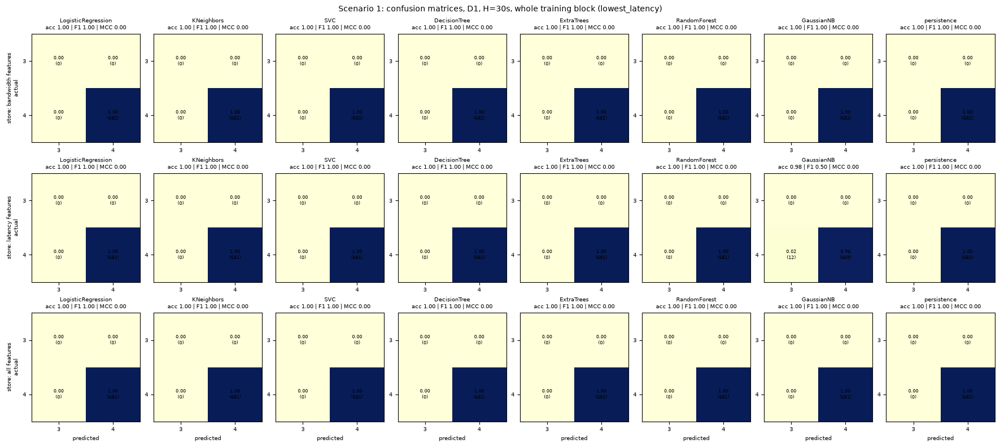

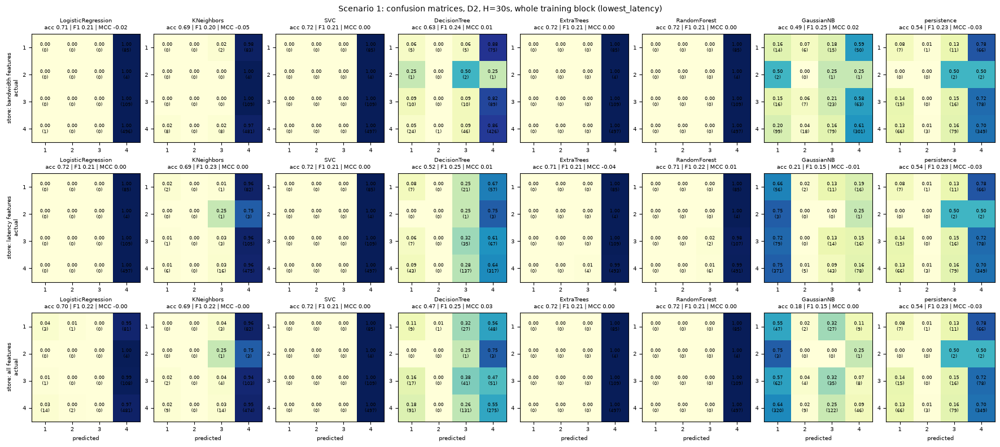

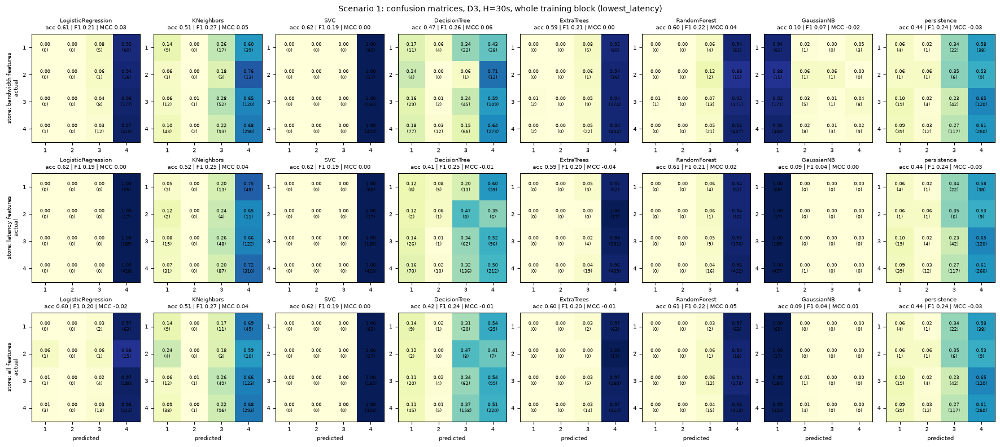

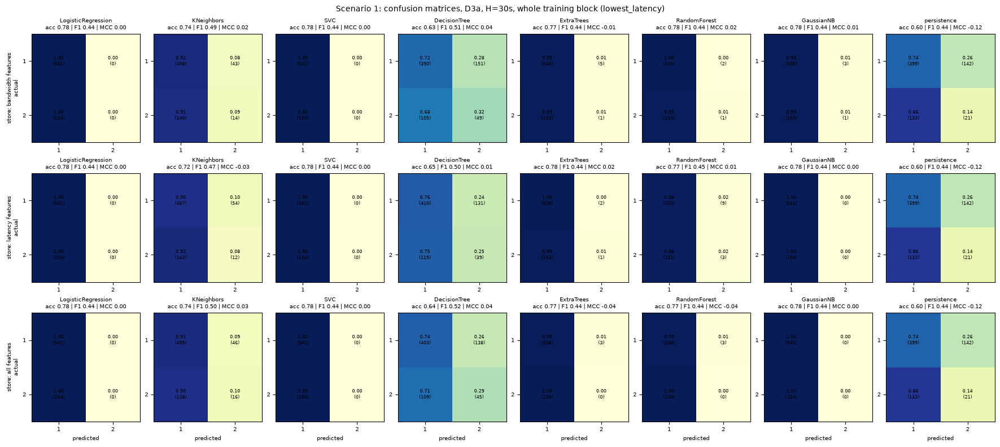

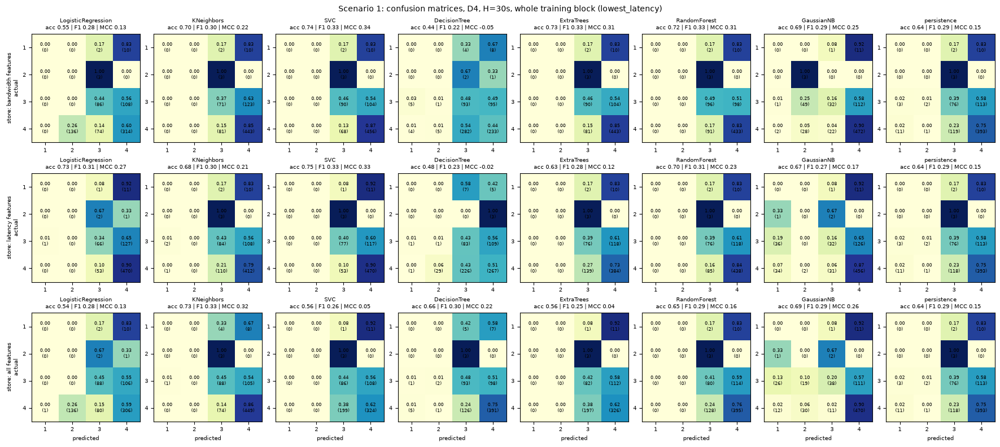

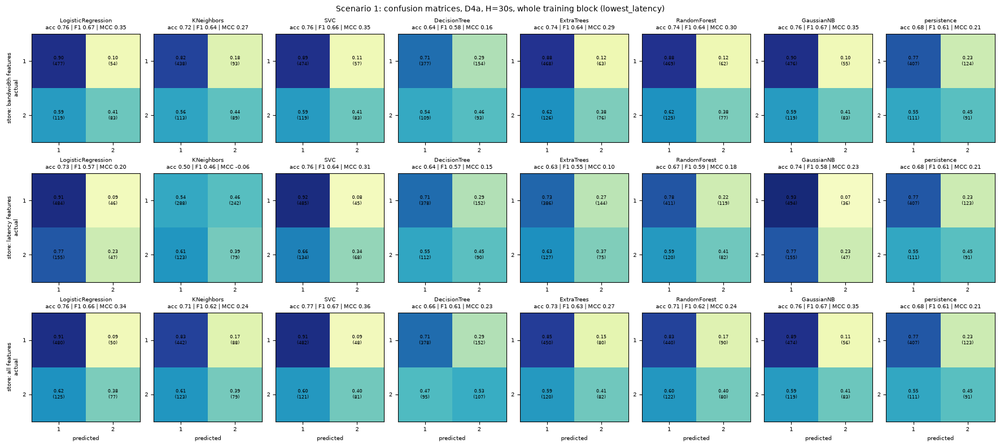

In [68]:
# Confusion matrices of every model at one horizon: one figure per dataset, one row
#   per feature set (plot_confusion_rows_fs). Persistence is drawn next to the models.
#   CONFUSION_NORMALIZE_FS = True divides each row by its support, so the diagonal
#   becomes the recall of that route; the raw count is shown below it.
CONFUSION_H_FS = H_REF
CONFUSION_PREDICTORS_FS = evaluated_models + ['persistence']
CONFUSION_NORMALIZE_FS = True

for target in targets:
    predictions = sweep_predictions_fs[target]
    for dataset in datasets:
        plot_confusion_rows_fs(
            predictions[predictions.horizon_s == CONFUSION_H_FS], dataset,
            f'Scenario 1: confusion matrices, {dataset}, H={CONFUSION_H_FS}s, '
            f'whole training block ({target})',
            CONFUSION_PREDICTORS_FS, feature_sets, normalize=CONFUSION_NORMALIZE_FS,
            path=RESULTS_DIR[target] / f'sweep_confusion_{dataset}_H{CONFUSION_H_FS}.png')

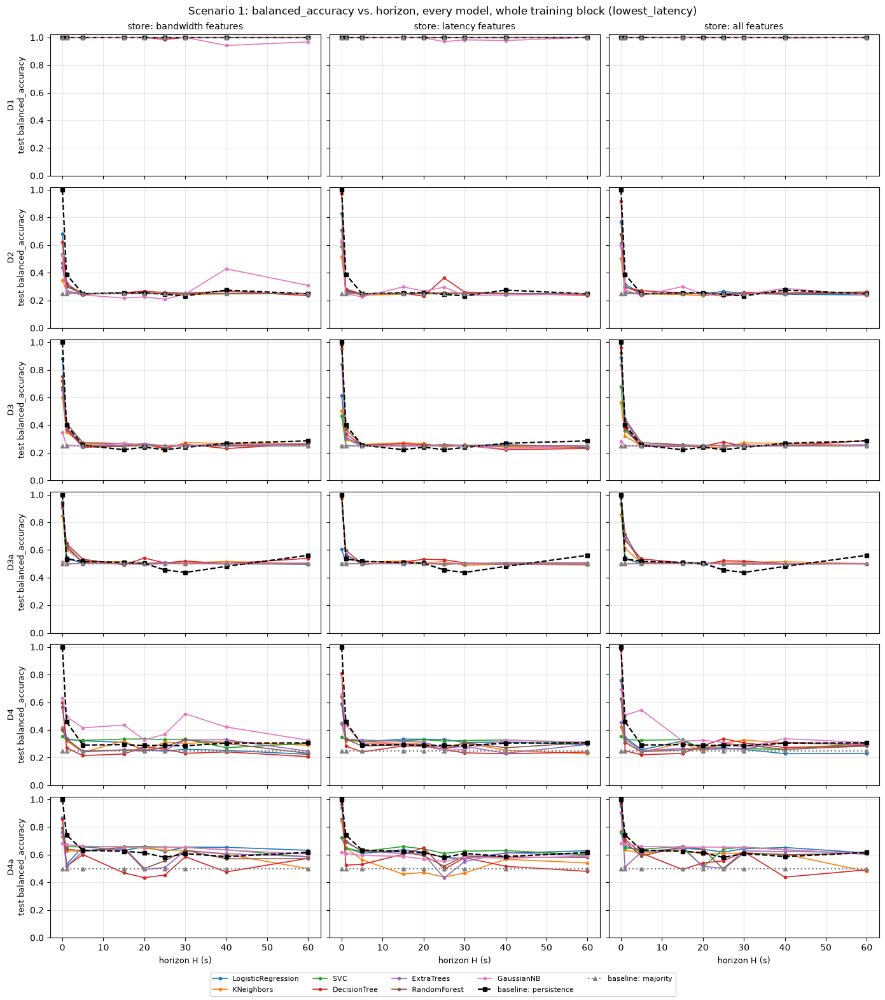

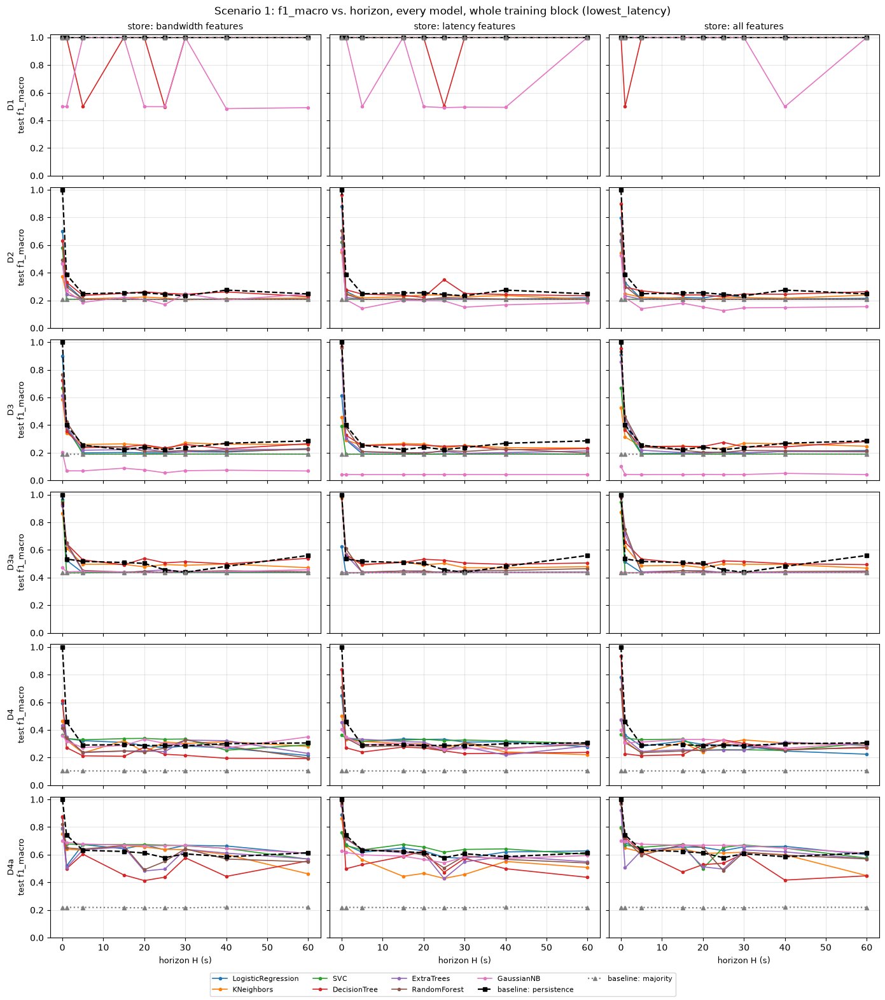

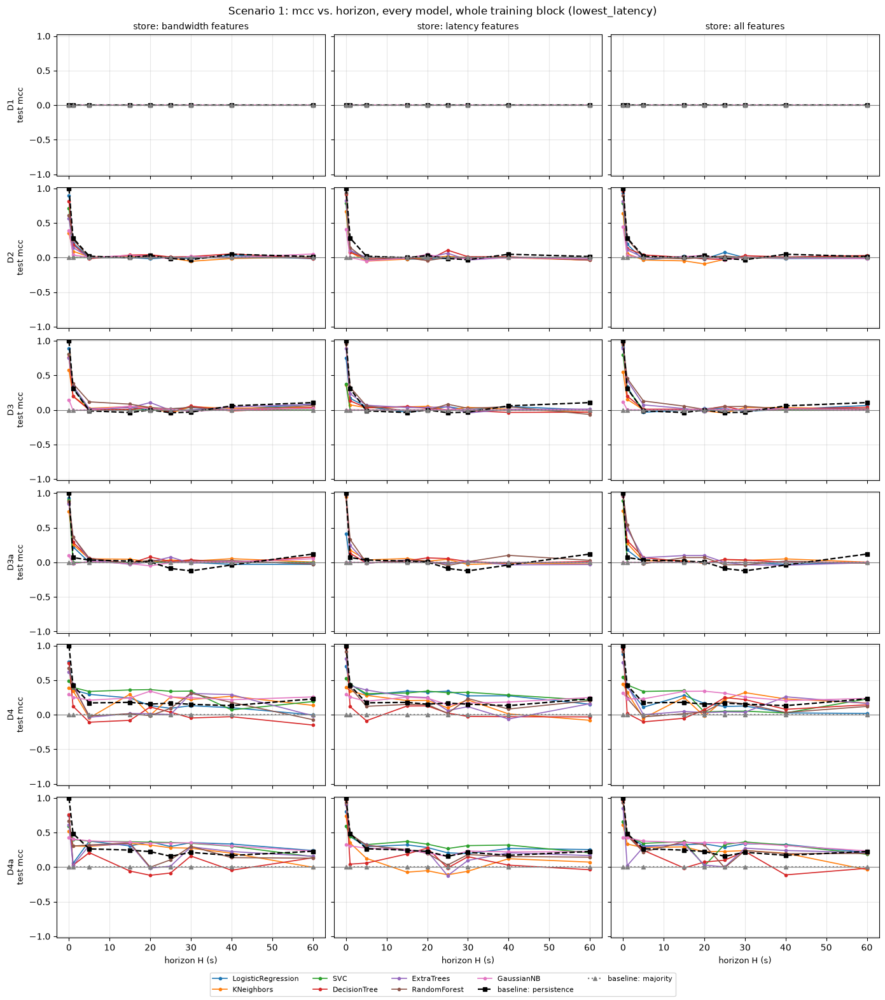

=== target: lowest_latency ===


In [69]:
# Metrics beyond accuracy over the horizons, for every model. One figure per metric of
#   METRICS_PLOT_FS (rows: datasets, columns: feature sets), one line per model, against
#   persistence and the majority class (accuracy itself is in the figure of the horizon
#   sweep above). On balanced accuracy, F1 and MCC the majority class drops to
#   1 / routes, low and 0 respectively, which is where a model that only follows the
#   dominant route shows up.
#   Then one table per dataset and metric of METRICS_TABLE_FS, read like the accuracy
#   tables of the sweep: green = beats both baselines, red = below persistence,
#   bold = best model of the feature set.
METRICS_PLOT_FS = ['balanced_accuracy', 'f1_macro', 'mcc']
METRICS_TABLE_FS = ['f1_macro']


def best_by_metric_fs(metrics, keys, predictors=evaluated_models):
    """For every case and metric, the highest value among the given predictors.

    No longer plotted here; scenario 2 still saves window_best_by_metric.csv with it.
    """
    models = metrics[metrics.predictor.isin(predictors)]
    return models.groupby(keys)[METRICS_FS].max()


for target in targets:
    metrics = sweep_metrics_fs[target]
    for metric in METRICS_PLOT_FS:
        plot_every_model_fs(
            metrics, 'horizon_s', evaluated_models, BASELINES_FS, datasets, feature_sets,
            f'Scenario 1: {metric} vs. horizon, every model, whole training block ({target})',
            'horizon H (s)', value=metric,
            path=RESULTS_DIR[target] / f'sweep_{metric}_every_model.png')

    print(f'=== target: {target} ===')
    for metric in METRICS_TABLE_FS:
        for dataset in datasets:
            table = every_model_table_fs(metrics[metrics.dataset == dataset], 'horizon_s',
                                         evaluated_models, BASELINES_FS, feature_sets,
                                         value=metric)
            display(style_every_model_fs(
                table, evaluated_models, BASELINES_FS,
                f'{dataset} | test {metric} by horizon H (s), whole training block'))

## Scenario 2: training window W

The accuracy of **every model** over the evaluated test instants, per
`(dataset, feature set, H, W)`, next to two baselines measured on the same
instants: **persistence** and the **window majority** (the most frequent label of
the window). One table per dataset and horizon in `WINDOW_TABLE_HORIZONS_FS` (the
reference horizon by default); columns are the window sizes `W`. The colours are
those of scenario 1: green beats both baselines, red is worse than persistence,
bold is the best model.

Two extra columns, not coloured:
- **full block**: the accuracy of the same model in scenario 1 (trained on the
  whole training block, same feature set and horizon). It is measured on every
  test instant and this scenario on one instant every `WINDOW_STEP` seconds, so
  the two match closely but not exactly.
- the **single-class windows** line under each table: the share of windows
  holding a single label. When it is close to 100%, every model collapses into
  the window majority, and a gain at that `W` comes from the recent labels rather
  than from `X`.

In [70]:
_case_fs = ['dataset', 'feature_set', 'horizon_s', 'window_s']
WINDOW_TABLE_BASELINES_FS = ['persistence', 'window_majority']
WINDOW_TABLE_HORIZONS_FS = [H_REF]  # horizons printed as tables; list(horizons) prints all

window_metrics_fs, window_best_fs, window_long_fs = {}, {}, {}
for target in targets:
    rows = []
    for case, group in window_predictions_fs[target].groupby(_case_fs):
        common = dict(zip(_case_fs, case),
                      instants=len(group),
                      mean_train_size=group.n_train.mean(),
                      single_class_pct=100 * group.single_class.mean(),
                      persistence=(group.persistence == group.y_true).mean(),
                      window_majority=(group.window_majority == group.y_true).mean())
        for model in evaluated_models:
            rows.append({
                **common, 'model': model,
                'accuracy': accuracy_score(group.y_true, group[model]),
                'f1_macro': f1_score(group.y_true, group[model], average='macro', zero_division=0),
            })

    window_metrics_fs[target] = pd.DataFrame(rows).merge(
        sweep_fs[target].rename(columns={'accuracy': 'full_block', 'f1_macro': 'full_block_f1'}),
        on=['dataset', 'feature_set', 'horizon_s', 'model'], how='left')
    window_metrics_fs[target].to_csv(RESULTS_DIR[target] / 'window_metrics.csv', index=False)

    # Best model of each case: kept for window_best_model.csv and the later sections
    best = (window_metrics_fs[target].sort_values('accuracy', ascending=False)
            .drop_duplicates(_case_fs)
            .rename(columns={'model': 'best model'})
            .set_index(_case_fs).sort_index()
            .reindex(datasets, level=0))
    best['gain over persistence'] = best['accuracy'] - best['persistence']
    best['gain over window majority'] = best['accuracy'] - best['window_majority']
    window_best_fs[target] = best
    best.to_csv(RESULTS_DIR[target] / 'window_best_model.csv')

    # Every model and both baselines, one row per (case, predictor)
    metrics = window_metrics_fs[target]
    window_long_fs[target] = every_model_long_fs(
        metrics, metrics[_case_fs + WINDOW_TABLE_BASELINES_FS], _case_fs)

    print(f'=== target: {target} ===')
    long, full = window_long_fs[target], sweep_long_fs[target]
    for H in WINDOW_TABLE_HORIZONS_FS:
        for dataset in datasets:
            part = long[(long.dataset == dataset) & (long.horizon_s == H)]
            table = every_model_table_fs(part, 'window_s', evaluated_models,
                                         WINDOW_TABLE_BASELINES_FS, feature_sets)
            reference = (full[(full.dataset == dataset) & (full.horizon_s == H)]
                         .set_index(['feature_set', 'predictor'])['accuracy'])
            table['full block'] = reference.reindex(table.index).to_numpy()
            display(style_every_model_fs(
                table, evaluated_models, WINDOW_TABLE_BASELINES_FS,
                f'{dataset} | H={H}s | test accuracy by training window W (s), '
                f'one instant every {WINDOW_STEP} s',
                uncoloured=['full block']))

            single = (metrics[(metrics.dataset == dataset) & (metrics.horizon_s == H)]
                      .drop_duplicates(['feature_set', 'window_s'])
                      .groupby('window_s').single_class_pct.first())
            print('single-class windows (%) by W: '
                  + ', '.join(f'W={W}: {pct:.0f}' for W, pct in single.items()))

=== target: lowest_latency ===


single-class windows (%) by W: W=5: 100, W=10: 100, W=15: 100, W=30: 100, W=45: 100, W=60: 100, W=120: 100, W=180: 100, W=300: 100, W=450: 100, W=600: 99


single-class windows (%) by W: W=5: 28, W=10: 8, W=15: 2, W=30: 0, W=45: 0, W=60: 0, W=120: 0, W=180: 0, W=300: 0, W=450: 0, W=600: 0


single-class windows (%) by W: W=5: 14, W=10: 2, W=15: 0, W=30: 0, W=45: 0, W=60: 0, W=120: 0, W=180: 0, W=300: 0, W=450: 0, W=600: 0


single-class windows (%) by W: W=5: 28, W=10: 6, W=15: 1, W=30: 0, W=45: 0, W=60: 0, W=120: 0, W=180: 0, W=300: 0, W=450: 0, W=600: 0


single-class windows (%) by W: W=5: 42, W=10: 23, W=15: 20, W=30: 18, W=45: 16, W=60: 14, W=120: 6, W=180: 0, W=300: 0, W=450: 0, W=600: 0


single-class windows (%) by W: W=5: 46, W=10: 27, W=15: 22, W=30: 18, W=45: 16, W=60: 14, W=120: 6, W=180: 0, W=300: 0, W=450: 0, W=600: 0


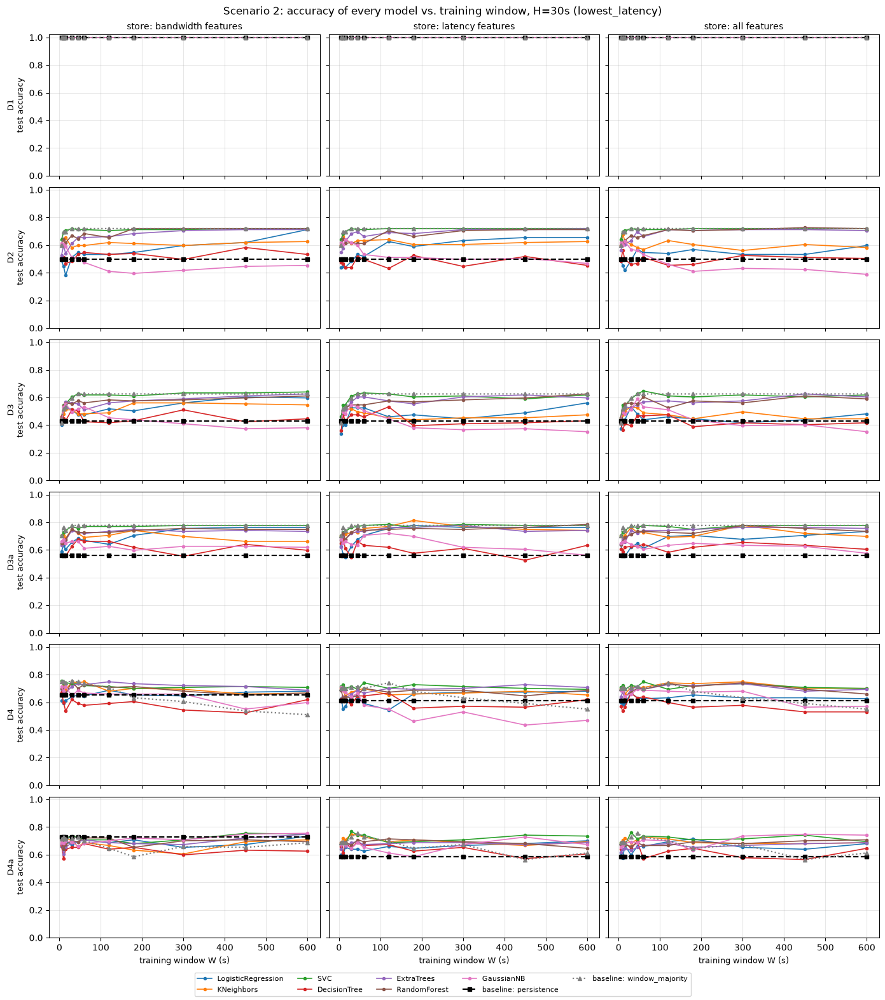

In [71]:
for target in targets:
    long = window_long_fs[target]
    plot_every_model_fs(
        long[long.horizon_s == H_REF], 'window_s', evaluated_models,
        WINDOW_TABLE_BASELINES_FS, datasets, feature_sets,
        f'Scenario 2: accuracy of every model vs. training window, H={H_REF}s ({target})',
        'training window W (s)',
        path=RESULTS_DIR[target] / f'window_every_model_H{H_REF}.png')

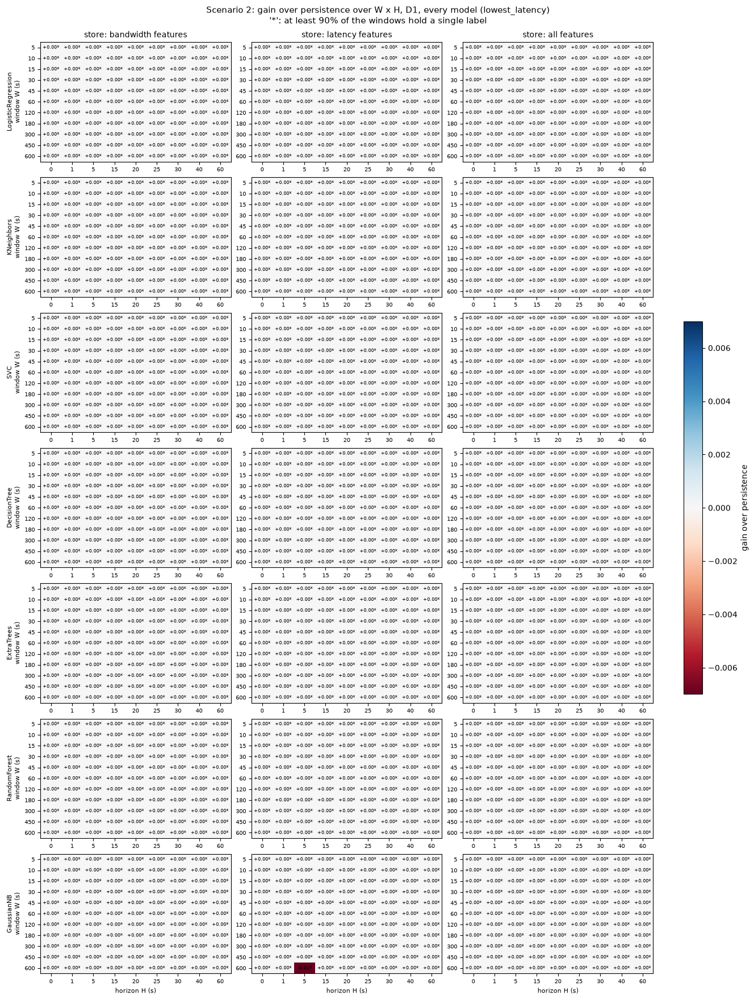

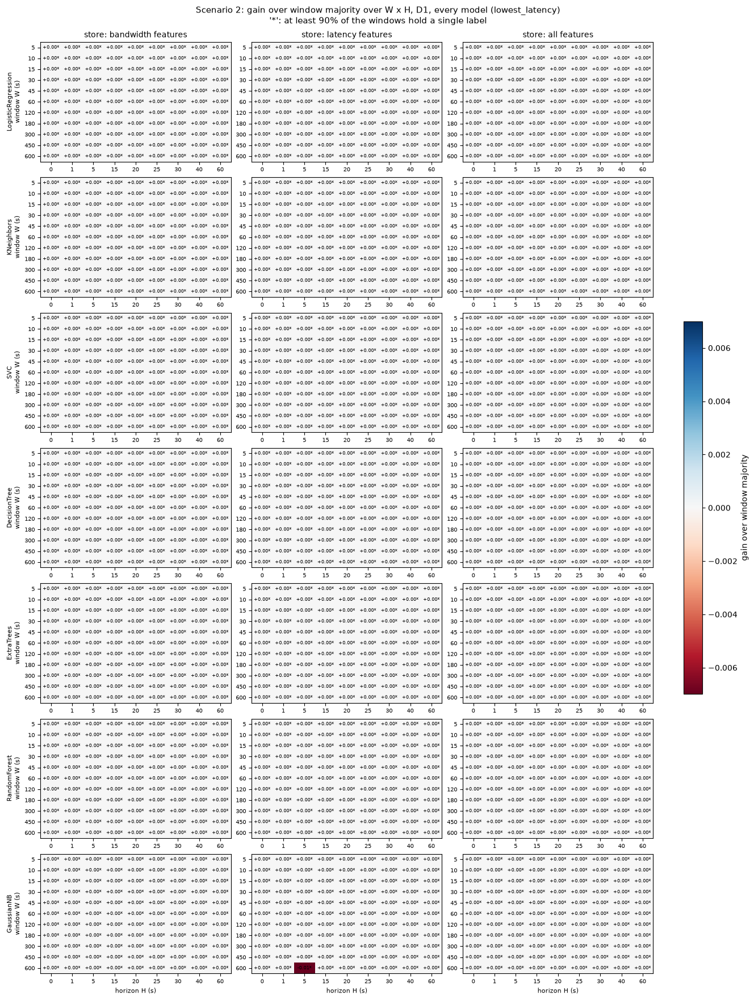

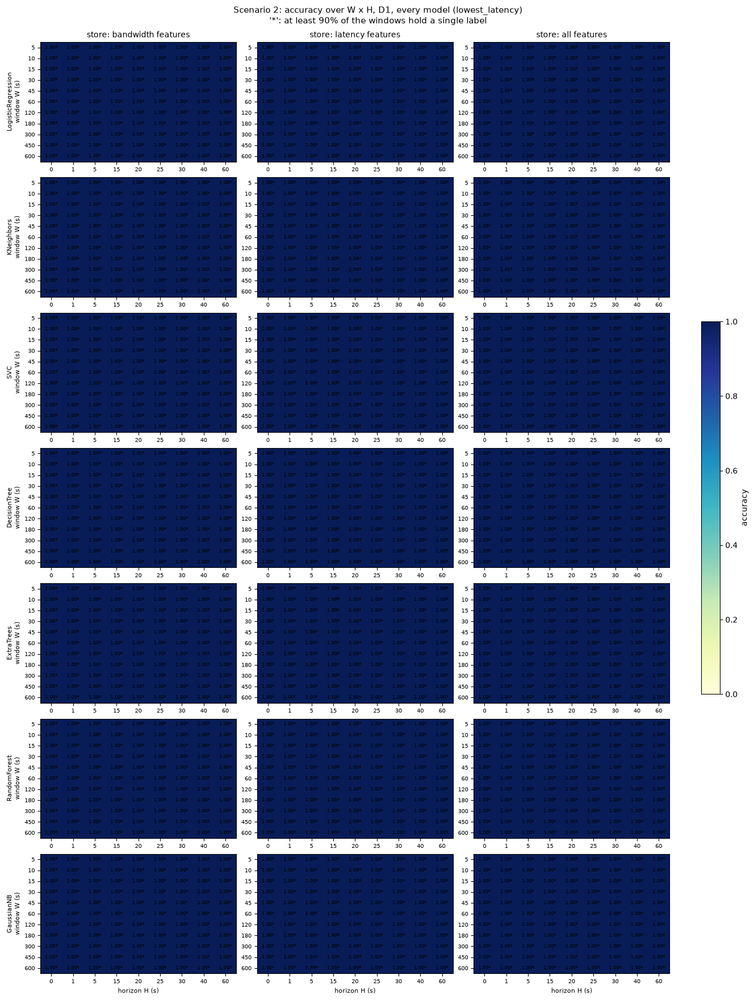

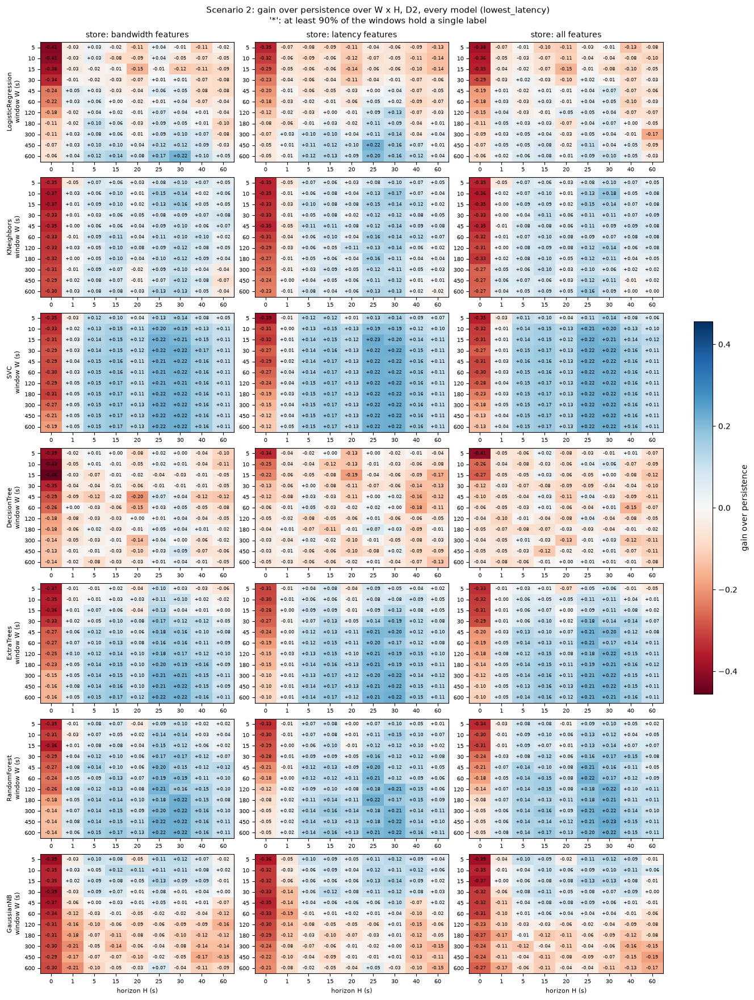

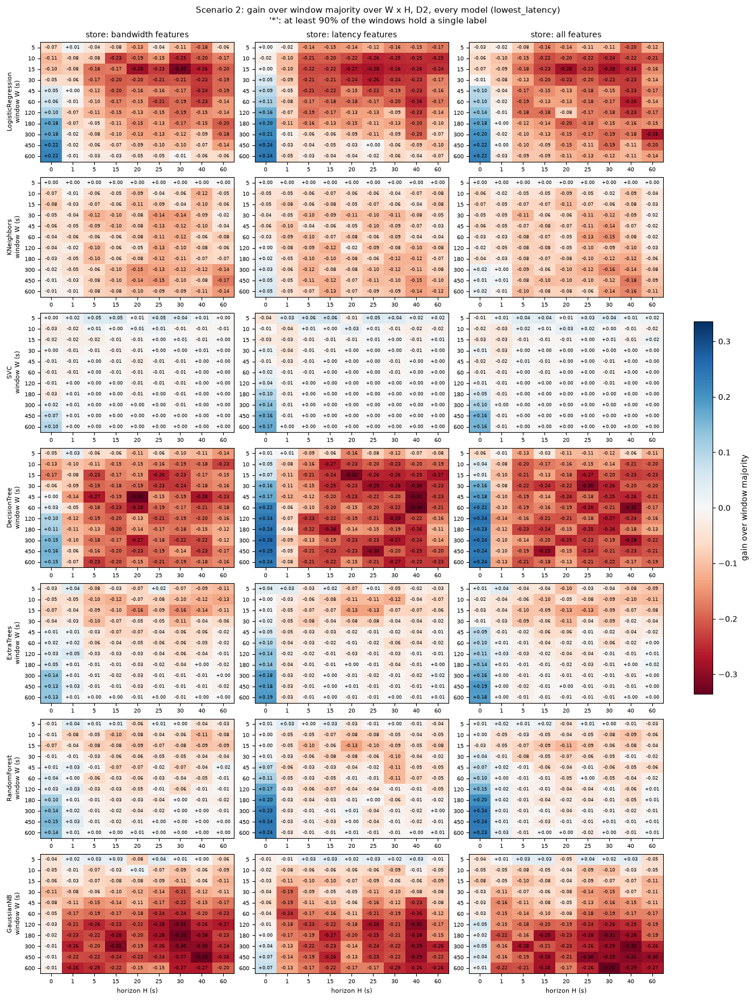

...

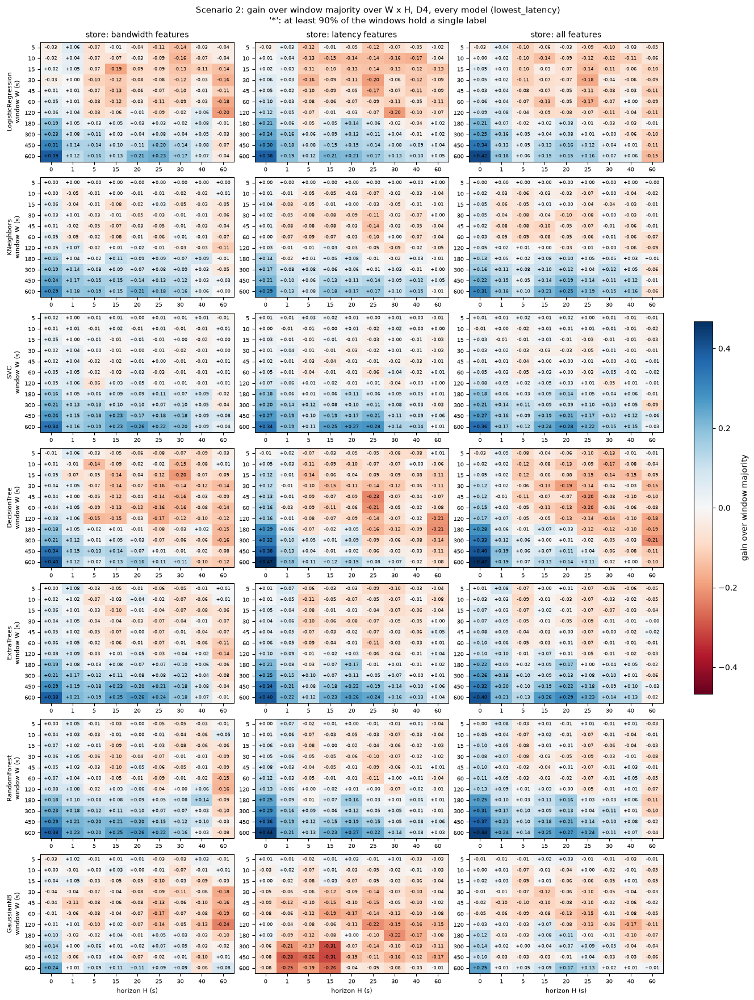

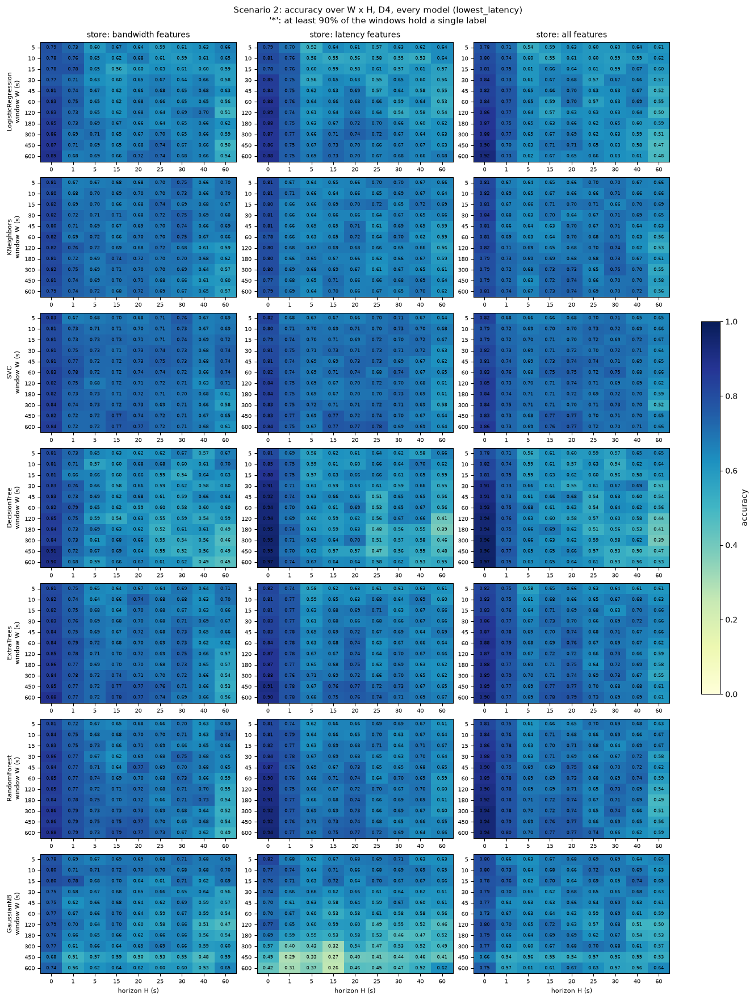

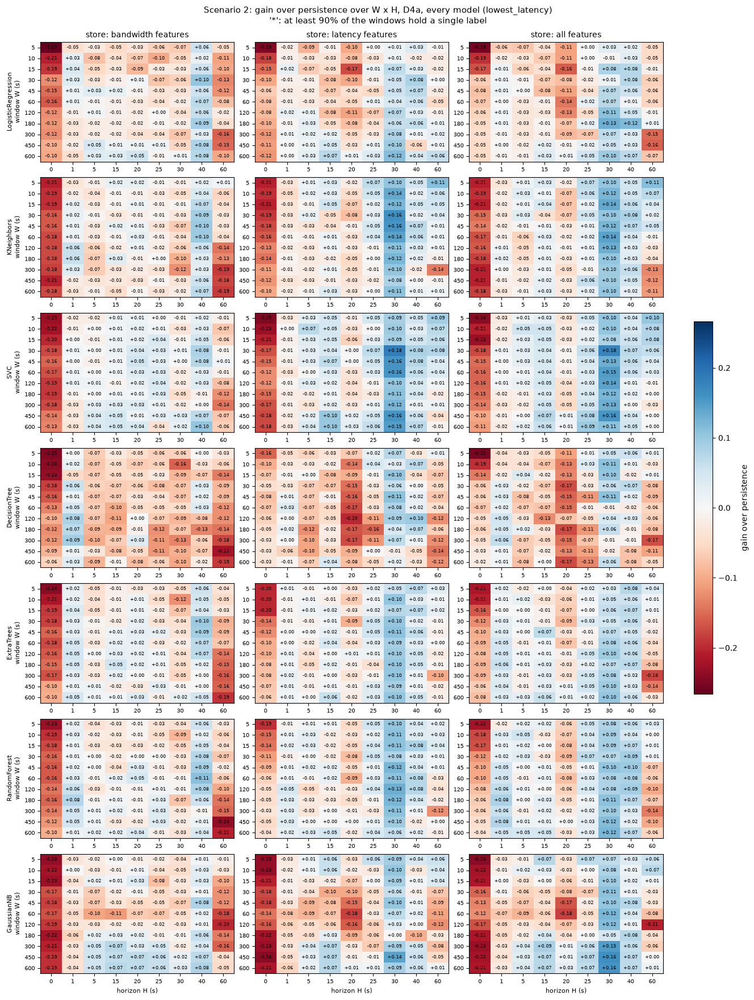

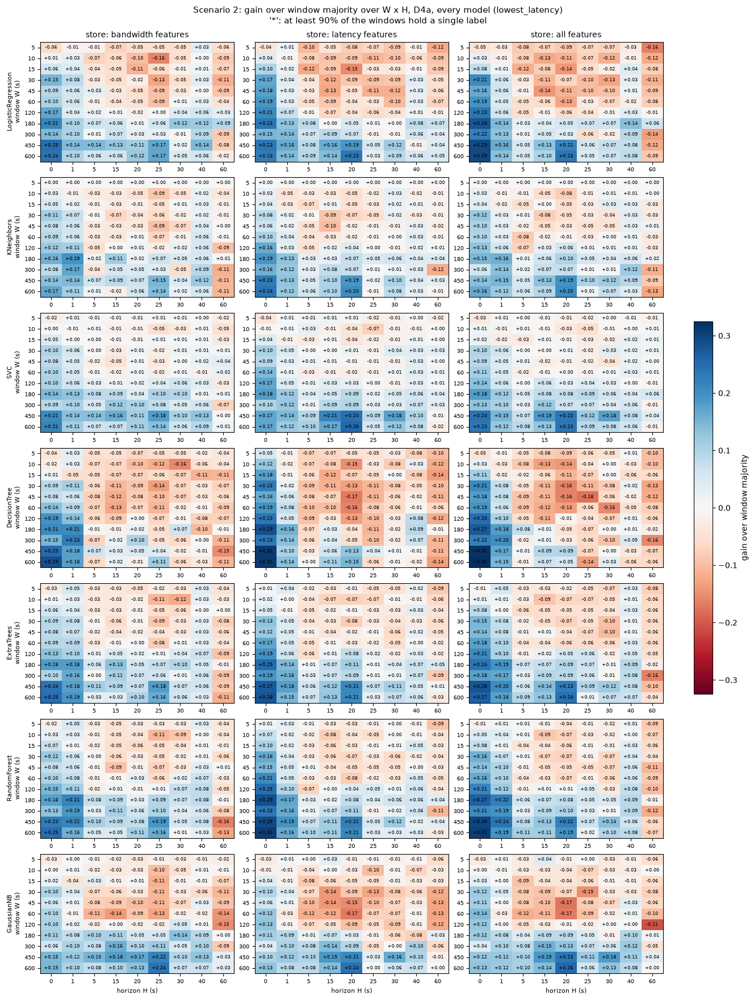

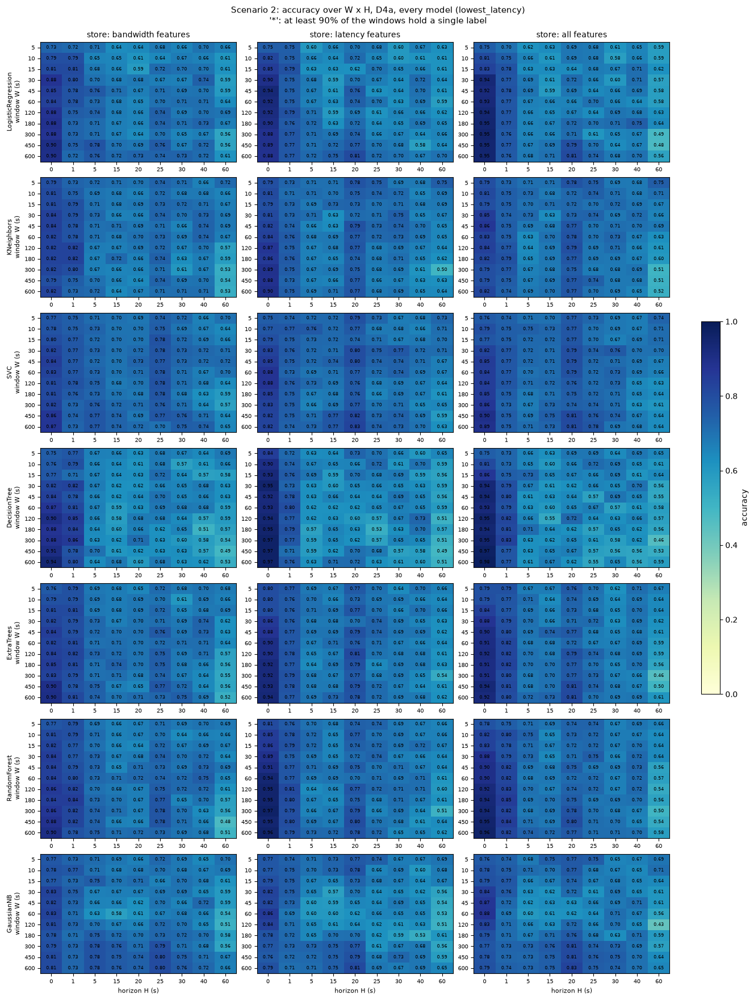

In [72]:
# Results over the whole (W, H) grid, for every model: one figure per dataset and
#   metric, with one heatmap per model (rows) and feature set (columns). In each
#   heatmap the training window W is on the rows and the horizon H on the columns.
#   MODEL_GRID_FS lists the models drawn; evaluated_models draws all of them.
#
#   Three metrics:
#     gain over persistence     - accuracy minus "the best route in H s is the one now"
#     gain over window majority - accuracy minus the most frequent label of the window,
#                                 i.e. what the model adds by using X at all
#     accuracy                  - the absolute value, for reference
#   A '*' marks the cells where at least SINGLE_CLASS_MARK_FS % of the windows hold a
#   single label: there every model returns the window majority, so the cell says
#   nothing about X.
#   The same numbers as tables: the scenario 2 accuracy tables above, with
#   WINDOW_TABLE_HORIZONS_FS = list(horizons).
MODEL_GRID_FS = evaluated_models
SINGLE_CLASS_MARK_FS = 90

GRID_METRICS_FS = ['gain over persistence', 'gain over window majority', 'accuracy']

grid_table_fs = {}
for target in targets:
    metrics = window_metrics_fs[target]
    grid_source = metrics[metrics.model.isin(MODEL_GRID_FS)].copy()
    grid_source['gain over persistence'] = grid_source.accuracy - grid_source.persistence
    grid_source['gain over window majority'] = (grid_source.accuracy
                                                - grid_source.window_majority)

    # Long table of the grid, one row per (dataset, feature set, model, W, H)
    grid_table_fs[target] = (grid_source
                             .set_index(['dataset', 'feature_set', 'model',
                                         'window_s', 'horizon_s'])
                             [GRID_METRICS_FS + ['persistence', 'window_majority',
                                                 'single_class_pct']]
                             .sort_index())
    grid_table_fs[target].to_csv(RESULTS_DIR[target] / 'window_grid_W_H_every_model.csv')

    for dataset in datasets:
        for metric in GRID_METRICS_FS:
            plot_window_grid_every_model_fs(
                grid_source, metric, dataset, MODEL_GRID_FS, feature_sets, windows, horizons,
                SINGLE_CLASS_MARK_FS,
                f'Scenario 2: {metric} over W x H, {dataset}, every model ({target})',
                path=(RESULTS_DIR[target]
                      / f'window_grid_{metric.replace(" ", "_")}_{dataset}_every_model.png'))

### Scenario 2: confusion matrices and metrics beyond accuracy

The same metrics for the sliding training window, computed from the predictions the
loop already stored (`window_predictions_fs`), so nothing is retrained. The
predictors are the 7 models plus **persistence** and the **window majority**.
Each `(dataset, feature set, H, W)` case is scored on the evaluated instants only,
about 25 per case with `WINDOW_STEP = 30`. With so few instants a minority route
may appear once or twice, so `mcc` and the macro averages move in large steps; read
them as orders of magnitude.

=== target: lowest_latency ===
Best model by each metric, H=30s (rows: dataset, feature set, W):


accuracy  balanced_accuracy  \
dataset feature_set             window_s                                
D1      store: all features     5            1.000              1.000   
                                10           1.000              1.000   
                                15           1.000              1.000   
                                30           1.000              1.000   
                                45           1.000              1.000   
...                                            ...                ...   
D4a     store: latency features 120          0.714              0.601   
                                180          0.707              0.627   
                                300          0.707              0.674   
                                450          0.741              0.586   
                                600          0.735              0.633   

                                          precision_macro  recall_macro  \
dataset feature_set             window_s                                  
D1      store: all features     5                   1.000         1.000   
                                10                  1.000         1.000   
                                15                  1.000         1.000   
                                30                  1.000         1.000   
                                45                  1.000         1.000   
...                                                   ...           ...   
D4a     store: latency features 120                 0.611         0.601   
                                180                 0.629         0.627   
                                300                 0.641         0.674   
                                450                 0.687         0.586   
                                600                 0.653         0.633   

                                          f1_macro    mcc  
dataset feature_set             window_s                   
D1      store: all features     5            1.000  0.000  
                                10           1.000  0.000  
                                15           1.000  0.000  
                                30           1.000  0.000  
                                45           1.000  0.000  
...                                            ...    ...  
D4a     store: latency features 120          0.597  0.197  
                                180          0.628  0.256  
                                300          0.640  0.314  
                                450          0.591  0.215  
                                600          0.631  0.273  

[198 rows x 6 columns]

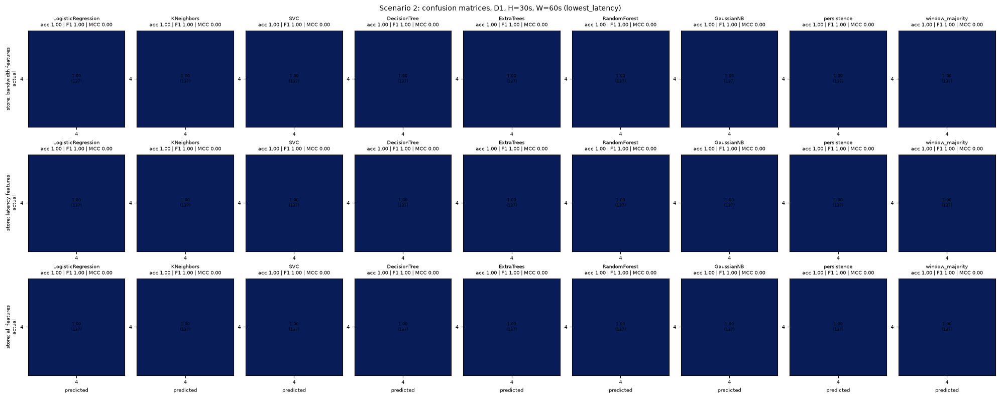

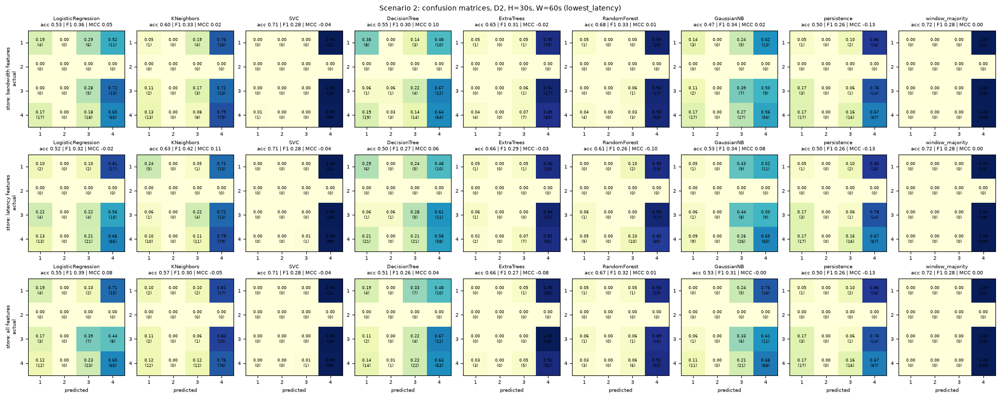

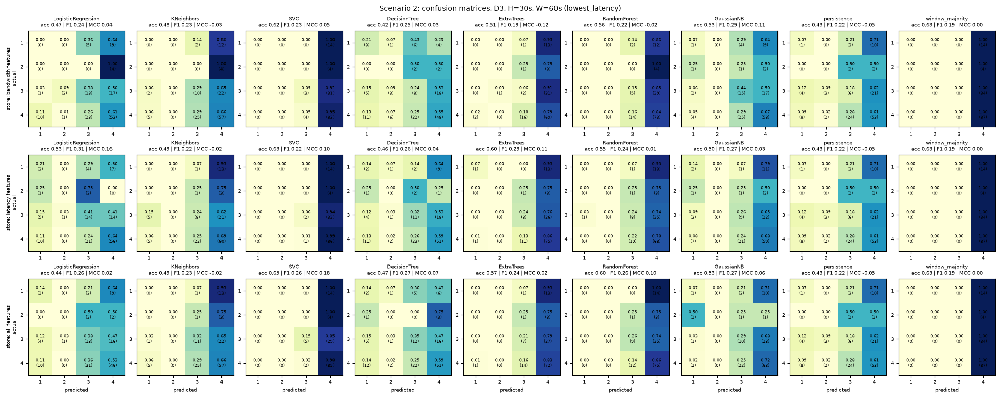

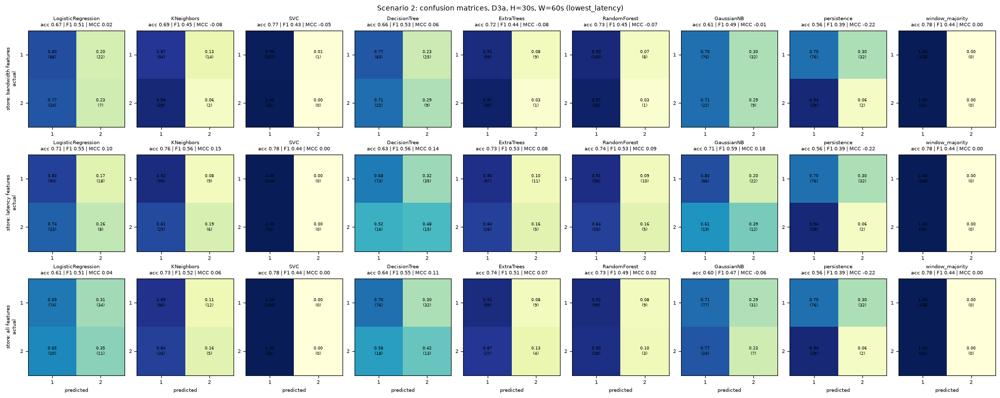

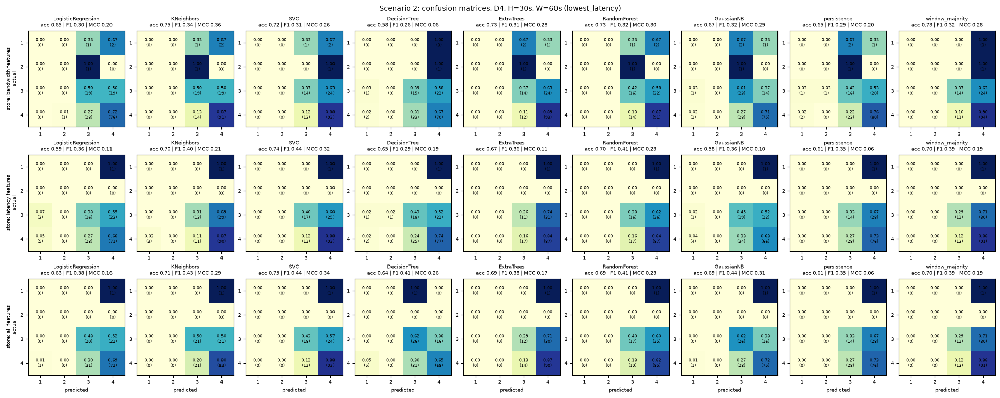

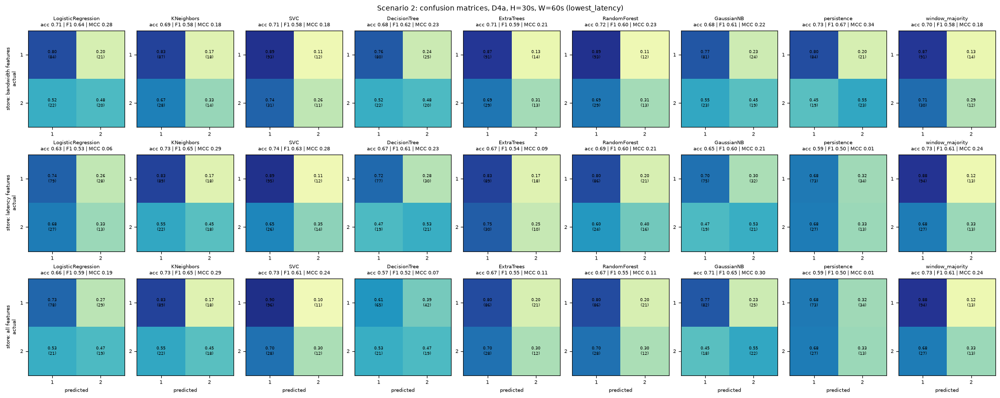

In [73]:
WINDOW_BASELINES_FS = ['persistence', 'window_majority']

# Confusion matrices at the reference horizon and one window size, summed over the
#   evaluated instants of each dataset's test block
CONFUSION_W_FS = 60
CONFUSION_WINDOW_PREDICTORS_FS = evaluated_models + WINDOW_BASELINES_FS

window_class_metrics_fs, window_best_metrics_fs = {}, {}
for target in targets:
    predictions = window_predictions_fs[target]
    window_class_metrics_fs[target] = metrics_table_fs(
        predictions, ['dataset', 'feature_set', 'horizon_s', 'window_s'],
        evaluated_models + WINDOW_BASELINES_FS)
    window_class_metrics_fs[target].to_csv(RESULTS_DIR[target] / 'window_class_metrics.csv',
                                           index=False)

    window_best_metrics_fs[target] = best_by_metric_fs(
        window_class_metrics_fs[target], ['dataset', 'feature_set', 'horizon_s', 'window_s'])
    window_best_metrics_fs[target].to_csv(RESULTS_DIR[target] / 'window_best_by_metric.csv')

    print(f'=== target: {target} ===')
    print(f'Best model by each metric, H={H_REF}s (rows: dataset, feature set, W):')
    display(window_best_metrics_fs[target].xs(H_REF, level='horizon_s')
            .reindex(datasets, level=0).round(3))

    case = predictions[(predictions.horizon_s == H_REF)
                       & (predictions.window_s == CONFUSION_W_FS)]
    for dataset in datasets:
        plot_confusion_rows_fs(
            case, dataset,
            f'Scenario 2: confusion matrices, {dataset}, H={H_REF}s, W={CONFUSION_W_FS}s '
            f'({target})',
            CONFUSION_WINDOW_PREDICTORS_FS, feature_sets, normalize=CONFUSION_NORMALIZE_FS,
            path=(RESULTS_DIR[target]
                  / f'window_confusion_{dataset}_H{H_REF}_W{CONFUSION_W_FS}.png'))

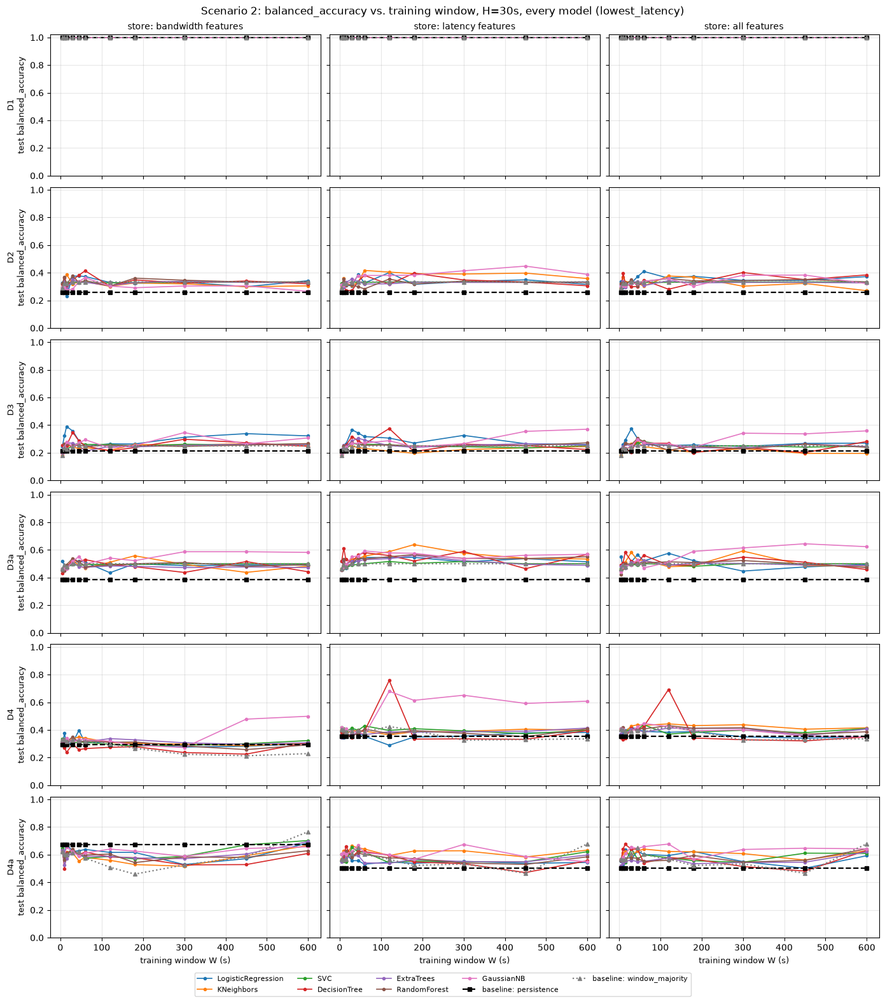

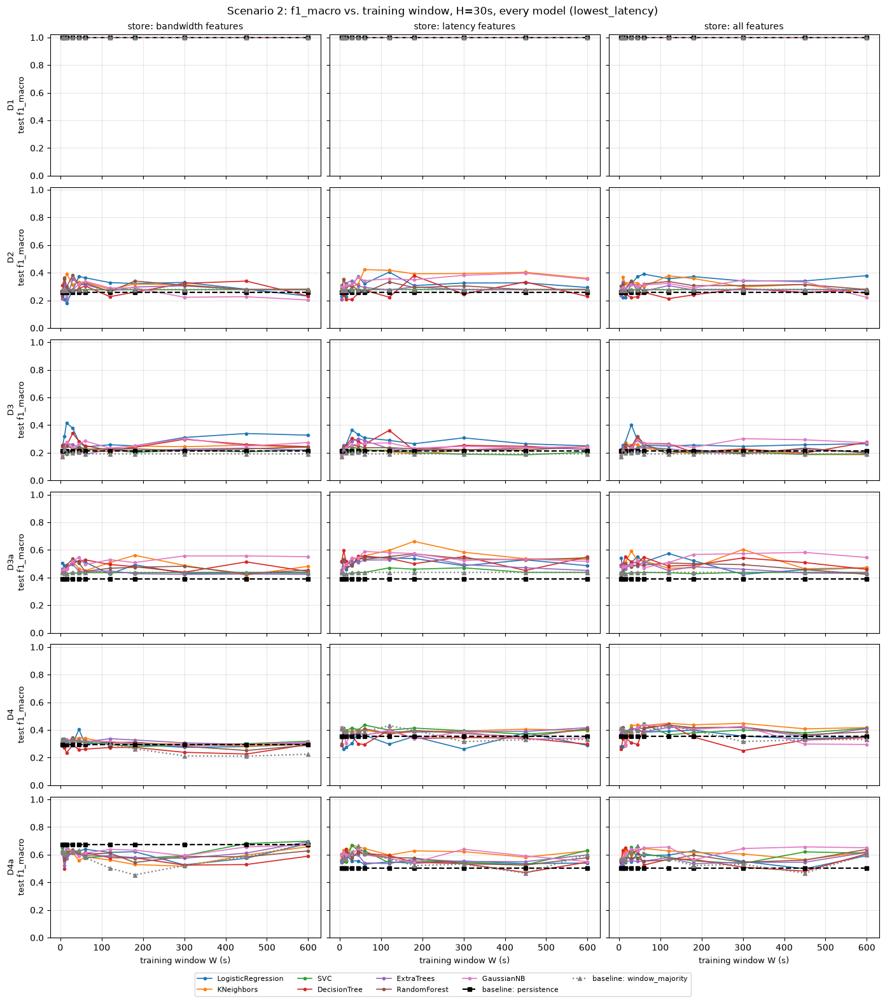

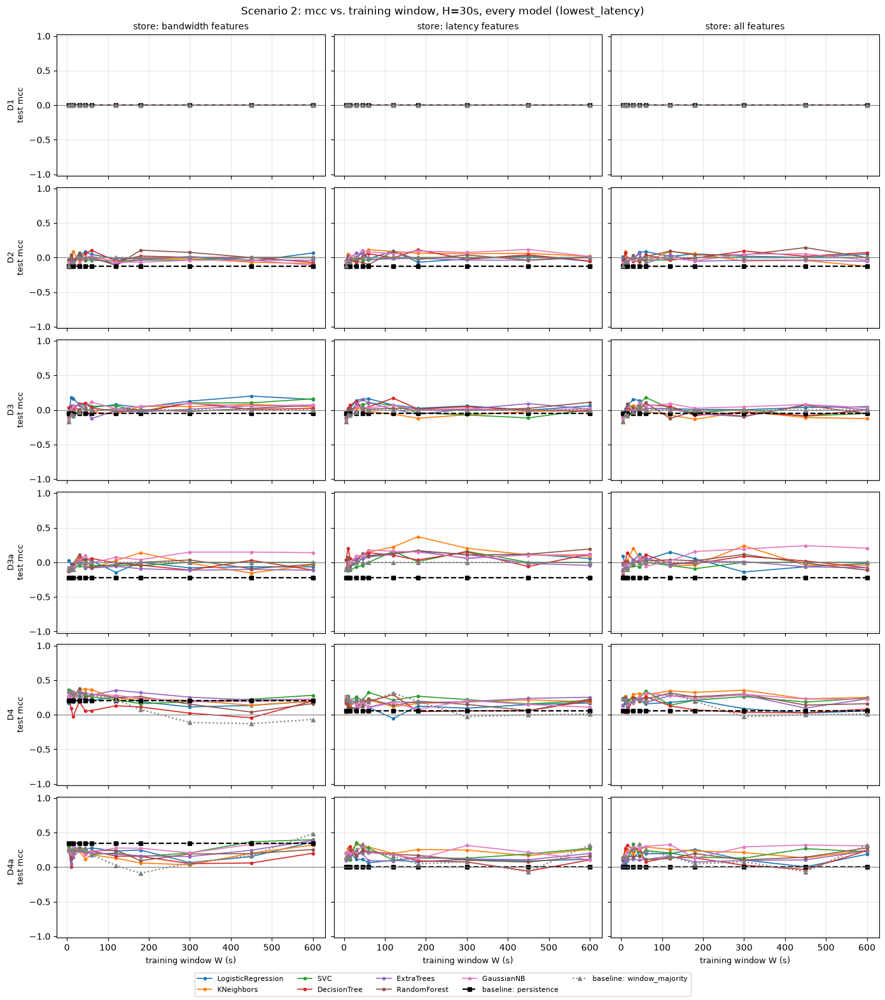

=== target: lowest_latency ===


In [74]:
# Metrics beyond accuracy against the window size, at the reference horizon, for every
#   model: one figure per metric of METRICS_PLOT_FS (rows: datasets, columns: feature
#   sets), against persistence and the window majority on the same evaluated instants.
#   Then one table per dataset of METRIC_GRID_FS against W, for every horizon of
#   WINDOW_TABLE_HORIZONS_FS, read like the accuracy tables of scenario 2.
METRIC_GRID_FS = 'f1_macro'

for target in targets:
    class_metrics = window_class_metrics_fs[target]
    for metric in METRICS_PLOT_FS:
        plot_every_model_fs(
            class_metrics[class_metrics.horizon_s == H_REF], 'window_s', evaluated_models,
            WINDOW_BASELINES_FS, datasets, feature_sets,
            f'Scenario 2: {metric} vs. training window, H={H_REF}s, every model ({target})',
            'training window W (s)', value=metric,
            path=RESULTS_DIR[target] / f'window_{metric}_every_model_H{H_REF}.png')

    print(f'=== target: {target} ===')
    for H in WINDOW_TABLE_HORIZONS_FS:
        for dataset in datasets:
            part = class_metrics[(class_metrics.dataset == dataset)
                                 & (class_metrics.horizon_s == H)]
            table = every_model_table_fs(part, 'window_s', evaluated_models,
                                         WINDOW_BASELINES_FS, feature_sets,
                                         value=METRIC_GRID_FS)
            display(style_every_model_fs(
                table, evaluated_models, WINDOW_BASELINES_FS,
                f'{dataset} | H={H}s | test {METRIC_GRID_FS} by training window W (s), '
                f'one instant every {WINDOW_STEP} s'))

# Other evaluations (for the future)

## Targets side by side

With more than one target in `targets`, the reference horizon `H_REF` of both
scenarios, one column block per target. Each target is read against its own
persistence: the same route can be the best by latency and not by bandwidth, so
the absolute accuracies are not comparable across targets, the gains are.

In [75]:
_scenario_1_columns_fs = ['best model', 'accuracy', 'persistence', 'majority',
                          'gain over persistence']
print(f'Scenario 1, H={H_REF}s: best model trained on the whole training block')
display(pd.concat({target: best_fs[target].xs(H_REF, level='horizon_s')[_scenario_1_columns_fs]
                   for target in targets}, axis=1).round(4))

print(f'Scenario 2, H={H_REF}s: gain of the best window model over persistence '
      f'and over the window majority')
display(pd.concat({target: window_best_fs[target].xs(H_REF, level='horizon_s')
                   [['gain over persistence', 'gain over window majority']]
                   for target in targets}, axis=1).round(4))

Scenario 1, H=30s: best model trained on the whole training block


lowest_latency                       \
                                           best model accuracy persistence   
dataset feature_set                                                          
D1      store: all features              DecisionTree   1.0000      1.0000   
        store: bandwidth features          KNeighbors   1.0000      1.0000   
        store: latency features    LogisticRegression   1.0000      1.0000   
D2      store: all features                       SVC   0.7151      0.5353   
        store: bandwidth features        RandomForest   0.7151      0.5353   
        store: latency features                   SVC   0.7151      0.5353   
D3      store: all features                       SVC   0.6158      0.4417   
        store: bandwidth features                 SVC   0.6158      0.4417   
        store: latency features    LogisticRegression   0.6158      0.4417   
D3a     store: all features                GaussianNB   0.7784      0.6043   
        store: bandwidth features  LogisticRegression   0.7784      0.6043   
        store: latency features                   SVC   0.7784      0.6043   
D4      store: all features                KNeighbors   0.7336      0.6407   
        store: bandwidth features                 SVC   0.7449      0.6398   
        store: latency features                   SVC   0.7473      0.6407   
D4a     store: all features                       SVC   0.7691      0.6803   
        store: bandwidth features  LogisticRegression   0.7640      0.6794   
        store: latency features                   SVC   0.7555      0.6803   

                                                                  
                                  majority gain over persistence  
dataset feature_set                                               
D1      store: all features         1.0000                0.0000  
        store: bandwidth features   1.0000                0.0000  
        store: latency features     1.0000                0.0000  
D2      store: all features         0.7151                0.1799  
        store: bandwidth features   0.7151                0.1799  
        store: latency features     0.7151                0.1799  
D3      store: all features         0.6158                0.1741  
        store: bandwidth features   0.6158                0.1741  
        store: latency features     0.6158                0.1741  
D3a     store: all features         0.7784                0.1741  
        store: bandwidth features   0.7784                0.1741  
        store: latency features     0.7784                0.1741  
D4      store: all features         0.2650                0.0929  
        store: bandwidth features   0.2647                0.1050  
        store: latency features     0.2650                0.1066  
D4a     store: all features         0.2760                0.0888  
        store: bandwidth features   0.2756                0.0846  
        store: latency features     0.2760                0.0751

Scenario 2, H=30s: gain of the best window model over persistence and over the window majority


lowest_latency  \
                                         gain over persistence   
dataset feature_set             window_s                         
D1      store: all features     5                       0.0000   
                                10                      0.0000   
                                15                      0.0000   
                                30                      0.0000   
                                45                      0.0000   
...                                                        ...   
D4a     store: latency features 120                     0.1293   
                                180                     0.1224   
                                300                     0.1224   
                                450                     0.1565   
                                600                     0.1497   

                                                                    
                                         gain over window majority  
dataset feature_set             window_s                            
D1      store: all features     5                           0.0000  
                                10                          0.0000  
                                15                          0.0000  
                                30                          0.0000  
                                45                          0.0000  
...                                                            ...  
D4a     store: latency features 120                         0.0136  
                                180                         0.0612  
                                300                         0.0340  
                                450                         0.1769  
                                600                         0.1224  

[198 rows x 2 columns]

## Model selection by time-series cross-validation

The tables above report, for every case, the **best of the 7 models by its accuracy
on the test block**. That choice is made on the test block itself, so part of the
gap to the baselines is selection luck, more so in scenario 2, where each case rests
on about 25 instants. This section **adds** a selection that never looks at the
test block:

1. For every `(dataset, feature set, H)`, the training block of scenario 1 is split
   by `TimeSeriesSplit(n_splits=CV_FOLDS, gap=H)`: `CV_FOLDS` consecutive validation
   chunks, each one scored by the models trained on every instant before it, with
   `H` rows left out between the two, the same rule as the gap between the training
   and test blocks. The store has one row per second, so `H` rows span at least `H`
   seconds and no training label `y(τ + H)` falls inside the validation chunk.
2. The model with the highest mean validation accuracy is the **CV-selected model**.
   A model that cannot be trained on some fold (e.g. a fold with a single route)
   ranks below the models trained on every fold; ties go to the first model of
   `evaluated_models`.
3. Its test accuracy is read from scenario 1 (`sweep_fs`): same model, same training
   block, so nothing is refitted on the test block.
4. Scenario 2 keeps the CV-selected model of the same `(dataset, feature set, H)` and
   reads its accuracy at every `W` from `window_metrics_fs`. `W` itself is not
   selected: every `W` is reported.

Next to it, the **test-selected** model (the best model of the tables above) and two
differences:

| column | meaning |
|---|---|
| `selection optimism` | test-selected minus CV-selected accuracy; never negative, and the part of the earlier tables that came from choosing on the test block |
| `cv minus test` | mean validation accuracy minus test accuracy of the CV-selected model; large values mean the regime changes between the training and test blocks |

The hyperparameters are the fixed ones of `make_pipelines_fs`: this section chooses
among the 7 models, it does not tune them.

In [24]:
from sklearn.model_selection import TimeSeriesSplit

CV_FOLDS = 5

# Results of this section, next to the folder of each target:
#   CenarioPreditivoFS_cv_selection, CenarioPreditivoFS_<target>_cv_selection
RESULTS_DIR_CV = {target: folder.with_name(f'{folder.name}_cv_selection')
                  for target, folder in RESULTS_DIR.items()}
for _folder in RESULTS_DIR_CV.values():
    _folder.mkdir(parents=True, exist_ok=True)


def cross_validate_training_block_fs(wide, horizon_s, folds=CV_FOLDS,
                                     evaluated_models=evaluated_models):
    """Forward-chaining CV of every model inside the training block of scenario 1.

    Same frame and training block as evaluate_full_block_fs. Returns one row per
    (fold, model); a model that cannot be trained on a fold gets NaN there.
    """
    frame, train, _ = blocks_fs(wide, horizon_s)
    rows_train = np.flatnonzero(train)
    rows_train = rows_train[np.argsort(frame['ts_epoch'].to_numpy()[rows_train], kind='stable')]
    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)[rows_train]
    y = frame['melhor_rota'].to_numpy(dtype=int)[rows_train]

    rows = []
    splitter = TimeSeriesSplit(n_splits=folds, gap=horizon_s)
    for fold, (fit, validation) in enumerate(splitter.split(X), start=1):
        for name, model in make_pipelines_fs(evaluated_models).items():
            try:
                y_pred = model.fit(X[fit], y[fit]).predict(X[validation])
                accuracy = accuracy_score(y[validation], y_pred)
                f1 = f1_score(y[validation], y_pred, average='macro', zero_division=0)
            except ValueError:
                accuracy = f1 = np.nan
            rows.append({'fold': fold, 'model': name, 'n_fit': len(fit),
                         'n_validation': len(validation),
                         'fit_routes': len(np.unique(y[fit])),
                         'validation_routes': len(np.unique(y[validation])),
                         'accuracy': accuracy, 'f1_macro': f1})
    return pd.DataFrame(rows)


def select_model_cv_fs(cv_folds, evaluated_models=evaluated_models):
    """CV-selected model of one case and the per-model CV summary.

    Order: most folds trained, then highest mean validation accuracy, then the
    order of evaluated_models.
    """
    summary = (cv_folds.groupby('model')
               .agg(cv_accuracy=('accuracy', 'mean'), cv_accuracy_std=('accuracy', 'std'),
                    cv_f1_macro=('f1_macro', 'mean'), trained_folds=('accuracy', 'count'))
               .reindex(evaluated_models))
    ranking = (summary.assign(_order=np.arange(len(summary)))
               .sort_values(['trained_folds', 'cv_accuracy', '_order'],
                            ascending=[False, False, True], na_position='last'))
    return ranking.index[0], summary


print(f'CV helpers defined: TimeSeriesSplit with {CV_FOLDS} folds, gap = H rows')
for _target, _folder in RESULTS_DIR_CV.items():
    print(f'results      : {_folder} ({_target})')

CV helpers defined: TimeSeriesSplit with 5 folds, gap = H rows
results      : /home/beatrizam/Documents/beatriz/path-aware-datasets/resultados_am/CenarioPreditivoFS_cv_selection (lowest_latency)


In [77]:
# Scenario 1: CV inside every training block, then the test accuracy of the selected model
cv_folds_fs, cv_summary_fs, cv_selected_fs = {}, {}, {}

for target in targets:
    fold_parts, summary_parts, selected_rows = [], [], []
    for dataset in datasets:
        started = time.time()
        for feature_set in feature_sets:
            wide = WIDE_FS[target][(dataset, feature_set)]
            for H in horizons:
                case = {'dataset': dataset, 'feature_set': feature_set, 'horizon_s': H}
                folds_table = cross_validate_training_block_fs(wide, H)
                selected, summary = select_model_cv_fs(folds_table)
                fold_parts.append(folds_table.assign(**case))
                summary_parts.append(summary.reset_index().assign(
                    **case, selected=lambda table: table.model == selected))
                selected_rows.append({**case, 'cv model': selected,
                                      **summary.loc[selected].to_dict()})
        print(f'{target:24s} | {dataset:4s} | {time.time() - started:6.1f} s')

    cv_folds_fs[target] = pd.concat(fold_parts, ignore_index=True)
    cv_summary_fs[target] = pd.concat(summary_parts, ignore_index=True)

    # Test accuracy of the CV-selected model, read from the loop of scenario 1
    test_of_model = sweep_fs[target].rename(columns={
        'model': 'cv model', 'accuracy': 'test accuracy', 'f1_macro': 'test f1_macro'})
    test_selected = (best_fs[target].reset_index()
                     [_keys_fs + ['best model', 'accuracy']]
                     .rename(columns={'best model': 'test-selected model',
                                      'accuracy': 'test-selected accuracy'}))
    selected = (pd.DataFrame(selected_rows)
                .merge(test_of_model, on=_keys_fs + ['cv model'], how='left')
                .merge(sweep_baselines_fs[target][_keys_fs + ['persistence', 'majority']],
                       on=_keys_fs, how='left')
                .merge(test_selected, on=_keys_fs, how='left'))
    selected['gain over persistence'] = selected['test accuracy'] - selected['persistence']
    selected['selection optimism'] = (selected['test-selected accuracy']
                                      - selected['test accuracy'])
    selected['cv minus test'] = selected['cv_accuracy'] - selected['test accuracy']
    cv_selected_fs[target] = (selected.set_index(_keys_fs).sort_index()
                              .reindex(datasets, level=0))

    results_dir = RESULTS_DIR_CV[target]
    cv_folds_fs[target].to_csv(results_dir / 'cv_folds.csv', index=False)
    cv_summary_fs[target].to_csv(results_dir / 'cv_summary.csv', index=False)
    cv_selected_fs[target].to_csv(results_dir / 'sweep_cv_selected_model.csv')

    assert cv_selected_fs[target]['test accuracy'].notna().all(), \
        'a CV-selected model has no test accuracy in sweep_fs'
    assert (cv_selected_fs[target]['selection optimism'] >= -1e-12).all()

    table = cv_selected_fs[target]
    print(f'=== target: {target} ===')
    print('Test accuracy of the CV-selected model, by horizon:')
    display(table['test accuracy'].unstack('horizon_s').round(4))
    print('CV-selected model:')
    display(table['cv model'].unstack('horizon_s'))
    print('Gain of the CV-selected model over persistence:')
    display(table['gain over persistence'].unstack('horizon_s').round(4))
    print('Selection optimism (test-selected minus CV-selected accuracy):')
    display(table['selection optimism'].unstack('horizon_s').round(4))
    print(f'At H={H_REF}s:')
    display(table.xs(H_REF, level='horizon_s')[
        ['cv model', 'cv_accuracy', 'cv_accuracy_std', 'trained_folds', 'test accuracy',
         'cv minus test', 'test-selected model', 'test-selected accuracy',
         'selection optimism', 'persistence', 'majority', 'gain over persistence']].round(4))

lowest_latency           | D1   |   45.5 s
lowest_latency           | D2   |  111.5 s
lowest_latency           | D3   |  124.1 s
lowest_latency           | D3a  |   86.9 s
lowest_latency           | D4   |  132.2 s
lowest_latency           | D4a  |   93.0 s
=== target: lowest_latency ===
Test accuracy of the CV-selected model, by horizon:


horizon_s                              0       1       5       15      20  \
dataset feature_set                                                         
D1      store: all features        1.0000  1.0000  1.0000  1.0000  1.0000   
        store: bandwidth features  1.0000  1.0000  1.0000  1.0000  1.0000   
        store: latency features    1.0000  1.0000  1.0000  1.0000  1.0000   
D2      store: all features        0.9808  0.7407  0.7113  0.7153  0.7143   
        store: bandwidth features  0.9562  0.7394  0.7113  0.7153  0.7143   
        store: latency features    0.9617  0.7133  0.7113  0.7153  0.7143   
D3      store: all features        0.9808  0.7270  0.6138  0.6129  0.6040   
        store: bandwidth features  0.9412  0.6904  0.6138  0.6157  0.6054   
        store: latency features    0.9754  0.6763  0.6138  0.6157  0.6068   
D3a     store: all features        0.9904  0.8505  0.7683  0.7742  0.7751   
        store: bandwidth features  0.9754  0.7822  0.7683  0.7672  0.7666   
        store: latency features    0.9904  0.7668  0.7628  0.7714  0.7723   
D4      store: all features        0.9805  0.7066  0.5446  0.5640  0.5565   
        store: bandwidth features  0.8713  0.7849  0.7549  0.7603  0.7611   
        store: latency features    0.9883  0.7797  0.7362  0.7467  0.7083   
D4a     store: all features        0.9740  0.8018  0.7717  0.7640  0.7648   
        store: bandwidth features  0.8713  0.5567  0.7720  0.7683  0.7651   
        store: latency features    0.9207  0.7953  0.7533  0.7707  0.7352   

horizon_s                              25      30      40      60  
dataset feature_set                                                
D1      store: all features        1.0000  1.0000  1.0000  1.0000  
        store: bandwidth features  1.0000  1.0000  1.0000  1.0000  
        store: latency features    1.0000  1.0000  1.0000  1.0000  
D2      store: all features        0.7118  0.7151  0.7174  0.7162  
        store: bandwidth features  0.7118  0.7151  0.7174  0.7162  
        store: latency features    0.7118  0.7151  0.7174  0.7162  
D3      store: all features        0.6134  0.6115  0.6061  0.6131  
        store: bandwidth features  0.6091  0.6043  0.6091  0.6146  
        store: latency features    0.6134  0.6158  0.6179  0.6131  
D3a     store: all features        0.7760  0.7784  0.7716  0.7785  
        store: bandwidth features  0.7718  0.7755  0.7745  0.7785  
        store: latency features    0.7689  0.7770  0.7804  0.7785  
D4      store: all features        0.6707  0.5601  0.7194  0.6997  
        store: bandwidth features  0.7497  0.7449  0.5298  0.6313  
        store: latency features    0.6545  0.6284  0.5125  0.6121  
D4a     store: all features        0.7629  0.7609  0.7444  0.7170  
        store: bandwidth features  0.7618  0.7626  0.7434  0.7145  
        store: latency features    0.7412  0.7391  0.6222  0.7241

CV-selected model:


horizon_s                                          0                   1   \
dataset feature_set                                                         
D1      store: all features                KNeighbors          KNeighbors   
        store: bandwidth features          KNeighbors          KNeighbors   
        store: latency features            KNeighbors          KNeighbors   
D2      store: all features              DecisionTree        RandomForest   
        store: bandwidth features  LogisticRegression        RandomForest   
        store: latency features          DecisionTree                 SVC   
D3      store: all features              DecisionTree        RandomForest   
        store: bandwidth features  LogisticRegression        RandomForest   
        store: latency features          RandomForest        RandomForest   
D3a     store: all features              RandomForest        RandomForest   
        store: bandwidth features  LogisticRegression  LogisticRegression   
        store: latency features          RandomForest  LogisticRegression   
D4      store: all features              DecisionTree        RandomForest   
        store: bandwidth features        RandomForest        RandomForest   
        store: latency features          DecisionTree        RandomForest   
D4a     store: all features        LogisticRegression  LogisticRegression   
        store: bandwidth features        RandomForest          ExtraTrees   
        store: latency features    LogisticRegression  LogisticRegression   

horizon_s                                          5             15  \
dataset feature_set                                                   
D1      store: all features                KNeighbors    KNeighbors   
        store: bandwidth features          KNeighbors    KNeighbors   
        store: latency features            KNeighbors    KNeighbors   
D2      store: all features                       SVC           SVC   
        store: bandwidth features                 SVC           SVC   
        store: latency features                   SVC           SVC   
D3      store: all features                       SVC  RandomForest   
        store: bandwidth features                 SVC           SVC   
        store: latency features                   SVC           SVC   
D3a     store: all features        LogisticRegression    GaussianNB   
        store: bandwidth features  LogisticRegression    GaussianNB   
        store: latency features            ExtraTrees  RandomForest   
D4      store: all features                ExtraTrees    ExtraTrees   
        store: bandwidth features                 SVC           SVC   
        store: latency features    LogisticRegression           SVC   
D4a     store: all features                GaussianNB    GaussianNB   
        store: bandwidth features  LogisticRegression           SVC   
        store: latency features    LogisticRegression           SVC   

horizon_s                                    20                  25  \
dataset feature_set                                                   
D1      store: all features          KNeighbors          KNeighbors   
        store: bandwidth features    KNeighbors          KNeighbors   
        store: latency features      KNeighbors          KNeighbors   
D2      store: all features                 SVC                 SVC   
        store: bandwidth features           SVC  LogisticRegression   
        store: latency features             SVC                 SVC   
D3      store: all features        RandomForest        RandomForest   
        store: bandwidth features  RandomForest  LogisticRegression   
        store: latency features    RandomForest                 SVC   
D3a     store: all features          GaussianNB          GaussianNB   
        store: bandwidth features    GaussianNB          GaussianNB   
        store: latency features    RandomForest        RandomForest   
D4      store: all features          ExtraTr

Gain of the CV-selected model over persistence:


horizon_s                              0       1       5       15      20  \
dataset feature_set                                                         
D1      store: all features        0.0000  0.0000  0.0000  0.0000  0.0000   
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  0.0000   
        store: latency features    0.0000  0.0000  0.0000  0.0000  0.0000   
D2      store: all features       -0.0192  0.0645  0.1561  0.1655  0.1513   
        store: bandwidth features -0.0438  0.0631  0.1561  0.1655  0.1513   
        store: latency features   -0.0383  0.0370  0.1561  0.1655  0.1513   
D3      store: all features       -0.0192  0.1029  0.1655  0.1767  0.1471   
        store: bandwidth features -0.0588  0.0658  0.1655  0.1795  0.1485   
        store: latency features   -0.0246  0.0521  0.1655  0.1795  0.1499   
D3a     store: all features       -0.0096  0.1838  0.1145  0.1220  0.1273   
        store: bandwidth features -0.0246  0.1164  0.1145  0.1150  0.1188   
        store: latency features   -0.0096  0.1001  0.1090  0.1192  0.1245   
D4      store: all features       -0.0195 -0.0535 -0.1089 -0.0907 -0.0860   
        store: bandwidth features -0.1287  0.0248  0.1022  0.1052  0.1181   
        store: latency features   -0.0117  0.0196  0.0827  0.0920  0.0659   
D4a     store: all features       -0.0260  0.0091  0.0682  0.0693  0.0780   
        store: bandwidth features -0.1287 -0.2360  0.0695  0.0732  0.0792   
        store: latency features   -0.0793  0.0026  0.0499  0.0760  0.0484   

horizon_s                              25      30      40      60  
dataset feature_set                                                
D1      store: all features        0.0000  0.0000  0.0000  0.0000  
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  
        store: latency features    0.0000  0.0000  0.0000  0.0000  
D2      store: all features        0.1712  0.1799  0.1449  0.1548  
        store: bandwidth features  0.1712  0.1799  0.1449  0.1548  
        store: latency features    0.1712  0.1799  0.1449  0.1548  
D3      store: all features        0.1769  0.1698  0.1157  0.0956  
        store: bandwidth features  0.1726  0.1626  0.1186  0.0971  
        store: latency features    0.1769  0.1741  0.1274  0.0956  
D3a     store: all features        0.1612  0.1741  0.1376  0.0880  
        store: bandwidth features  0.1569  0.1712  0.1406  0.0880  
        store: latency features    0.1541  0.1727  0.1464  0.0880  
D4      store: all features        0.0230 -0.0806  0.0889  0.0302  
        store: bandwidth features  0.1015  0.1050 -0.1012 -0.0373  
        store: latency features    0.0068 -0.0123 -0.1181 -0.0575  
D4a     store: all features        0.1057  0.0806  0.0847  0.0359  
        store: bandwidth features  0.1042  0.0832  0.0846  0.0330  
        store: latency features    0.0840  0.0587 -0.0375  0.0431

Selection optimism (test-selected minus CV-selected accuracy):


horizon_s                              0       1       5       15      20  \
dataset feature_set                                                         
D1      store: all features        0.0000  0.0000  0.0000  0.0000  0.0000   
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  0.0000   
        store: latency features    0.0000  0.0000  0.0000  0.0000  0.0000   
D2      store: all features        0.0000  0.0000  0.0000  0.0000  0.0000   
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  0.0000   
        store: latency features    0.0109  0.0082  0.0000  0.0000  0.0000   
D3      store: all features        0.0000  0.0000  0.0097  0.0028  0.0085   
        store: bandwidth features  0.0000  0.0000  0.0028  0.0000  0.0141   
        store: latency features    0.0123  0.0000  0.0028  0.0000  0.0057   
D3a     store: all features        0.0000  0.0000  0.0014  0.0028  0.0028   
        store: bandwidth features  0.0000  0.0247  0.0000  0.0070  0.0085   
        store: latency features    0.0014  0.0343  0.0055  0.0028  0.0028   
D4      store: all features        0.0000  0.0847  0.2100  0.1947  0.1922   
        store: bandwidth features  0.0325  0.0104  0.0000  0.0000  0.0000   
        store: latency features    0.0000  0.0156  0.0276  0.0000  0.0444   
D4a     store: all features        0.0104  0.0000  0.0000  0.0040  0.0000   
        store: bandwidth features  0.0338  0.2256  0.0000  0.0000  0.0054   
        store: latency features    0.0663  0.0130  0.0079  0.0000  0.0242   

horizon_s                              25      30      40      60  
dataset feature_set                                                
D1      store: all features        0.0000  0.0000  0.0000  0.0000  
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  
        store: latency features    0.0000  0.0000  0.0000  0.0000  
D2      store: all features        0.0000  0.0000  0.0000  0.0000  
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  
        store: latency features    0.0014  0.0000  0.0000  0.0000  
D3      store: all features        0.0000  0.0043  0.0117  0.0000  
        store: bandwidth features  0.0043  0.0115  0.0088  0.0000  
        store: latency features    0.0043  0.0000  0.0015  0.0000  
D3a     store: all features        0.0000  0.0000  0.0059  0.0000  
        store: bandwidth features  0.0057  0.0029  0.0029  0.0000  
        store: latency features    0.0071  0.0014  0.0000  0.0000  
D4      store: all features        0.0556  0.1735  0.0000  0.0000  
        store: bandwidth features  0.0000  0.0000  0.1831  0.0803  
        store: latency features    0.0949  0.1189  0.2153  0.0920  
D4a     store: all features        0.0000  0.0082  0.0056  0.0000  
        store: bandwidth features  0.0027  0.0014  0.0042  0.0000  
        store: latency features    0.0000  0.0164  0.1319  0.0000

At H=30s:


cv model  cv_accuracy  cv_accuracy_std  \
dataset feature_set                                                             
D1      store: all features          KNeighbors       0.9992           0.0019   
        store: bandwidth features    KNeighbors       0.9992           0.0019   
        store: latency features      KNeighbors       0.9992           0.0019   
D2      store: all features                 SVC       0.8455           0.0507   
        store: bandwidth features           SVC       0.8455           0.0507   
        store: latency features             SVC       0.8455           0.0507   
D3      store: all features        RandomForest       0.5619           0.1366   
        store: bandwidth features  RandomForest       0.5677           0.1196   
        store: latency features             SVC       0.6153           0.0499   
D3a     store: all features          GaussianNB       0.7830           0.0779   
        store: bandwidth features    GaussianNB       0.7839           0.0747   
        store: latency features      ExtraTrees       0.7743           0.0925   
D4      store: all features                 SVC       0.6118           0.0518   
        store: bandwidth features           SVC       0.6535           0.0398   
        store: latency features      ExtraTrees       0.5953           0.0410   
D4a     store: all features          GaussianNB       0.6453           0.0483   
        store: bandwidth features    GaussianNB       0.6543           0.0521   
        store: latency features      GaussianNB       0.5705           0.0435   

                                   trained_folds  test accuracy  \
dataset feature_set                                               
D1      store: all features                  5.0         1.0000   
        store: bandwidth features            5.0         1.0000   
        store: latency features              5.0         1.0000   
D2      store: all features                  5.0         0.7151   
        store: bandwidth features            5.0         0.7151   
        store: latency features              5.0         0.7151   
D3      store: all features                  5.0         0.6115   
        store: bandwidth features            5.0         0.6043   
        store: latency features              5.0         0.6158   
D3a     store: all features                  5.0         0.7784   
        store: bandwidth features            5.0         0.7755   
        store: latency features              5.0         0.7770   
D4      store: all features                  5.0         0.5601   
        store: bandwidth features            5.0         0.7449   
        store: latency features              5.0         0.6284   
D4a     store: all features                  5.0         0.7609   
        store: bandwidth features            5.0         0.7626   
        store: latency features              5.0         0.7391   

                                   cv minus test test-selected model  \
dataset feature_set                                                    
D1      store: all features              -0.0008        DecisionTree   
        store: bandwidth features        -0.0008          KNeighbors   
        store: latency features          -0.0008  LogisticRegression   
D2      store: all features               0.1304                 SVC   
        store: bandwidth features         0.1304        RandomForest   
        store: latency features           0.1304                 SVC   
D3      store: all features              -0.0496                 SVC   
        store: bandwidth features        -0.0366                 SVC   
        store: latency features          -0.0005  LogisticRegression   
D3a     store: all features               0.0046          GaussianNB   
        store: bandwidth features         0.0083  LogisticRegression   
        store: latency features          -0.0027                 SVC   
D4      store: all features               0.0517          KNeighbors 

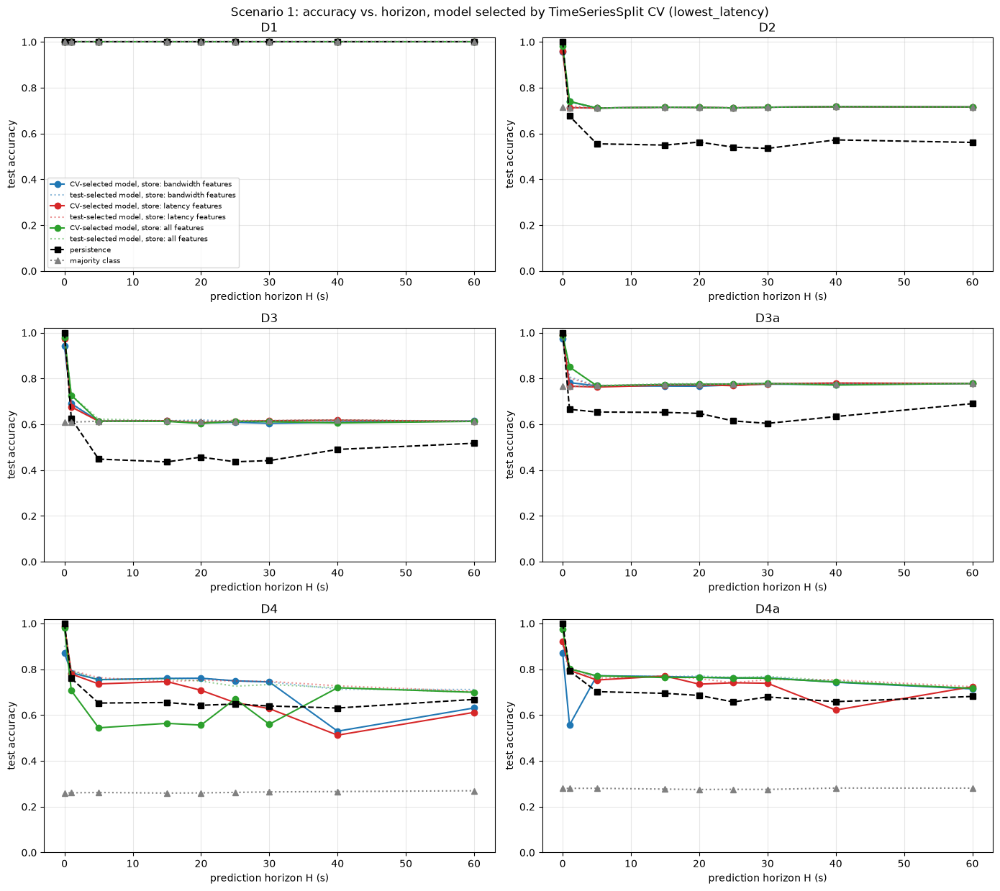

In [78]:
def plot_cv_selected_accuracy_fs(selected, baselines, datasets, feature_sets, colors,
                                 title, path=None):
    """Scenario 1: test accuracy of the CV-selected model against H.

    The test-selected model of the earlier tables is drawn as a faint dotted line of
    the same color, so the vertical distance between the two is the selection optimism.
    """
    fig, axes = _dataset_panels_fs(datasets)
    for axis, dataset in zip(axes.ravel(), datasets):
        for feature_set in feature_sets:
            cases = selected.loc[(dataset, feature_set)]
            color = colors[feature_set]
            axis.plot(cases.index, cases['test accuracy'], marker='o', color=color,
                      label=f'CV-selected model, {feature_set}')
            axis.plot(cases.index, cases['test-selected accuracy'], linestyle=':',
                      color=color, alpha=0.5, label=f'test-selected model, {feature_set}')
        base = baselines[(baselines.dataset == dataset)
                         & (baselines.feature_set == feature_sets[0])]
        axis.plot(base.horizon_s, base.persistence, 's--', color='black', label='persistence')
        axis.plot(base.horizon_s, base.majority, '^:', color='gray', label='majority class')
        axis.set_title(dataset)
        axis.set_xlabel('prediction horizon H (s)')
        axis.set_ylabel('test accuracy')
        axis.set_ylim(0, 1.02)
        axis.grid(alpha=0.3)

    axes[0][0].legend(fontsize=7, loc='lower left')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


for target in targets:
    plot_cv_selected_accuracy_fs(
        cv_selected_fs[target], sweep_baselines_fs[target], datasets, feature_sets,
        feature_sets_colors,
        f'Scenario 1: accuracy vs. horizon, model selected by TimeSeriesSplit CV '
        f'({target})',
        path=RESULTS_DIR_CV[target] / 'sweep_cv_selected_model.png')

In [79]:
# Scenario 2: the CV-selected model of scenario 1, read at every training window W
_case_cv_fs = ['dataset', 'feature_set', 'horizon_s', 'window_s']
window_cv_selected_fs = {}
for target in targets:
    chosen = cv_selected_fs[target].reset_index()[_keys_fs + ['cv model']]
    window = (window_metrics_fs[target]
              .merge(chosen, on=_keys_fs)
              .query('model == `cv model`')
              .drop(columns='model'))
    test_selected = (window_best_fs[target].reset_index()
                     [_case_cv_fs + ['best model', 'accuracy']]
                     .rename(columns={'best model': 'test-selected model',
                                      'accuracy': 'test-selected accuracy'}))
    window = window.merge(test_selected, on=_case_cv_fs, how='left')
    window['gain over persistence'] = window['accuracy'] - window['persistence']
    window['gain over window majority'] = window['accuracy'] - window['window_majority']
    window['selection optimism'] = window['test-selected accuracy'] - window['accuracy']
    window_cv_selected_fs[target] = (window.set_index(_case_cv_fs).sort_index()
                                     .reindex(datasets, level=0))
    window_cv_selected_fs[target].to_csv(RESULTS_DIR_CV[target] / 'window_cv_selected_model.csv')

    assert len(window) == len(window_best_fs[target]), \
        'every (dataset, feature set, H, W) case must have its CV-selected model'

    table = window_cv_selected_fs[target]
    print(f'=== target: {target} ===')
    print(f'CV-selected model per window at the reference horizon H={H_REF}s:')
    display(table.xs(H_REF, level='horizon_s')[
        ['cv model', 'accuracy', 'persistence', 'window_majority', 'full_block',
         'single_class_pct', 'gain over persistence', 'gain over window majority',
         'test-selected model', 'test-selected accuracy', 'selection optimism']].round(4))
    print('Gain of the CV-selected model over persistence (rows: dataset, feature set, W; '
          'columns: H):')
    display(table['gain over persistence'].unstack('horizon_s').round(4))
    print('Selection optimism (test-selected minus CV-selected accuracy; rows: dataset, '
          'feature set, W; columns: H):')
    display(table['selection optimism'].unstack('horizon_s').round(4))

=== target: lowest_latency ===
CV-selected model per window at the reference horizon H=30s:


cv model  accuracy  persistence  \
dataset feature_set             window_s                                      
D1      store: all features     5         KNeighbors    1.0000        1.000   
                                10        KNeighbors    1.0000        1.000   
                                15        KNeighbors    1.0000        1.000   
                                30        KNeighbors    1.0000        1.000   
                                45        KNeighbors    1.0000        1.000   
...                                              ...       ...          ...   
D4a     store: latency features 120       GaussianNB    0.6122        0.585   
                                180       GaussianNB    0.5850        0.585   
                                300       GaussianNB    0.6735        0.585   
                                450       GaussianNB    0.7279        0.585   
                                600       GaussianNB    0.6735        0.585   

                                          window_majority  full_block  \
dataset feature_set             window_s                                
D1      store: all features     5                  1.0000      1.0000   
                                10                 1.0000      1.0000   
                                15                 1.0000      1.0000   
                                30                 1.0000      1.0000   
                                45                 1.0000      1.0000   
...                                                   ...         ...   
D4a     store: latency features 120                0.7007      0.7391   
                                180                0.6463      0.7391   
                                300                0.6735      0.7391   
                                450                0.5646      0.7391   
                                600                0.6122      0.7391   

                                          single_class_pct  \
dataset feature_set             window_s                     
D1      store: all features     5                 100.0000   
                                10                100.0000   
                                15                100.0000   
                                30                100.0000   
                                45                100.0000   
...                                                    ...   
D4a     store: latency features 120                 6.1224   
                                180                 0.0000   
                                300                 0.0000   
                                450                 0.0000   
                                600                 0.0000   

                                          gain over persistence  \
dataset feature_set             window_s                          
D1      store: all features     5                        0.0000   
                                10                       0.0000   
                                15                       0.0000   
                                30                       0.0000   
                                45                       0.0000   
...                                                         ...   
D4a     store: latency features 120                      0.0272   
                                180                      0.0000   
                                300                      0.0884   
                                450                      0.1429   
                                600                      0.0884   

                                          gain over window majority  \
dataset feature_set             window_s                              
D1      store: all features     5                            0.0000   
                                10                           0.0000   
                                15                           0.0000   
                                

Gain of the CV-selected model over persistence (rows: dataset, feature set, W; columns: H):


horizon_s                                     0       1       5       15  \
dataset feature_set             window_s                                   
D1      store: all features     5         0.0000  0.0000  0.0000  0.0000   
                                10        0.0000  0.0000  0.0000  0.0000   
                                15        0.0000  0.0000  0.0000  0.0000   
                                30        0.0000  0.0000  0.0000  0.0000   
                                45        0.0000  0.0000  0.0000  0.0000   
...                                          ...     ...     ...     ...   
D4a     store: latency features 120      -0.0844  0.0195  0.0131  0.0200   
                                180      -0.0974 -0.0065  0.0261  0.0067   
                                300      -0.1169  0.0065  0.0196  0.0200   
                                450      -0.1104  0.0000  0.0131  0.1000   
                                600      -0.1169  0.0000  0.0261  0.1000   

horizon_s                                     20      25      30      40  \
dataset feature_set             window_s                                   
D1      store: all features     5         0.0000  0.0000  0.0000  0.0000   
                                10        0.0000  0.0000  0.0000  0.0000   
                                15        0.0000  0.0000  0.0000  0.0000   
                                30        0.0000  0.0000  0.0000  0.0000   
                                45        0.0000  0.0000  0.0000  0.0000   
...                                          ...     ...     ...     ...   
D4a     store: latency features 120      -0.1611 -0.0068  0.0272  0.0486   
                                180      -0.0940 -0.0270  0.0000  0.0486   
                                300      -0.0268  0.0135  0.0884  0.0139   
                                450      -0.0134  0.0473  0.1429  0.0069   
                                600       0.0134  0.0608  0.0884  0.0486   

horizon_s                                     60  
dataset feature_set             window_s          
D1      store: all features     5         0.0000  
                                10        0.0000  
                                15        0.0000  
                                30        0.0000  
                                45        0.0000  
...                                          ...  
D4a     store: latency features 120      -0.1214  
                                180      -0.0286  
                                300      -0.0786  
                                450      -0.0500  
                                600       0.0143  

[198 rows x 9 columns]

Selection optimism (test-selected minus CV-selected accuracy; rows: dataset, feature set, W; columns: H):


horizon_s                                     0       1       5       15  \
dataset feature_set             window_s                                   
D1      store: all features     5         0.0000  0.0000  0.0000  0.0000   
                                10        0.0000  0.0000  0.0000  0.0000   
                                15        0.0000  0.0000  0.0000  0.0000   
                                30        0.0000  0.0000  0.0000  0.0000   
                                45        0.0000  0.0000  0.0000  0.0000   
...                                          ...     ...     ...     ...   
D4a     store: latency features 120       0.0390  0.0260  0.0196  0.0000   
                                180       0.0519  0.0390  0.0000  0.0200   
                                300       0.0844  0.0195  0.0196  0.0533   
                                450       0.0779  0.0325  0.0131  0.0000   
                                600       0.0844  0.0195  0.0131  0.0000   

horizon_s                                     20      25      30      40  \
dataset feature_set             window_s                                   
D1      store: all features     5         0.0000  0.0000  0.0000  0.0000   
                                10        0.0000  0.0000  0.0000  0.0000   
                                15        0.0000  0.0000  0.0000  0.0000   
                                30        0.0000  0.0000  0.0000  0.0000   
                                45        0.0000  0.0000  0.0000  0.0000   
...                                          ...     ...     ...     ...   
D4a     store: latency features 120       0.1745  0.0473  0.1020  0.0486   
                                180       0.0805  0.0270  0.1224  0.0208   
                                300       0.0134  0.0000  0.0340  0.0347   
                                450       0.0336  0.0000  0.0136  0.0486   
                                600       0.0134  0.0000  0.0612  0.0208   

horizon_s                                     60  
dataset feature_set             window_s          
D1      store: all features     5         0.0000  
                                10        0.0000  
                                15        0.0000  
                                30        0.0000  
                                45        0.0000  
...                                          ...  
D4a     store: latency features 120       0.1286  
                                180       0.0429  
                                300       0.1000  
                                450       0.0571  
                                600       0.0500  

[198 rows x 9 columns]

## Scenario 2: model and window selection by prequential evaluation in the training block

The previous section chooses the model of scenario 2 by the CV of scenario 1, that is,
by how it does when trained on a whole training block. A model that is good with
about 2,000 samples is not necessarily good with the 5 to 60 samples of a window, so
that choice transfers poorly. This section **adds** a selection made in the regime
of scenario 2 itself, again without looking at the test block:

1. The procedure of scenario 2 (`run_training_window_fs`) is replayed **inside the
   training block**: one instant `t` every `TRAIN_WINDOW_STEP` rows of the training
   block is evaluated, and for each one every model is retrained on the window
   `t − H' − W < τ ≤ t − H'`, with `H' = max(H, 1)`, and predicts `y(t + H)`. This is
   prequential (test-then-train) evaluation. Only instants whose longest window fits
   in the series are evaluated, so every `W` is scored on the same instants.
2. Nothing of the test block enters: every window ends at `t − H' ≤ t_train-end − 1`,
   and the labels it holds were all observed inside the training block.
3. Two selections are made from that training-block accuracy:
   - **per window**: for each `(dataset, feature set, H, W)`, the model with the best
     prequential accuracy, so every `W` is still reported;
   - **joint**: for each `(dataset, feature set, H)`, the pair `(W, model)` with the
     best prequential accuracy, which gives a single number per case for scenario 2,
     comparable with the CV-selected model of scenario 1.
   Ties go to the first model of `evaluated_models`, then to the smallest `W`.
4. The test accuracy of each choice is read from `window_metrics_fs`, nothing is
   refitted on the test block.

The jointly selected window model is also compared with the **CV-selected full-block
model of scenario 1 on the same evaluated test instants** (from `sweep_predictions_fs`),
so the two scenarios are read on exactly the same instants.

In [80]:
# One evaluated instant every TRAIN_WINDOW_STEP rows of the training block. The training
#   block is about 4 times the test block, so with the same step as WINDOW_STEP this
#   costs about 4 times the scenario 2 loop; a larger step is cheaper and noisier.
TRAIN_WINDOW_STEP = WINDOW_STEP

# Results of this section, next to the folder of each target:
#   CenarioPreditivoFS_prequential_selection, CenarioPreditivoFS_<target>_prequential_selection
RESULTS_DIR_PREQ = {target: folder.with_name(f'{folder.name}_prequential_selection')
                    for target, folder in RESULTS_DIR.items()}
for _folder in RESULTS_DIR_PREQ.values():
    _folder.mkdir(parents=True, exist_ok=True)


def run_training_window_in_train_fs(wide, horizon_s, window_sizes=windows,
                                    step_s=TRAIN_WINDOW_STEP,
                                    evaluated_models=evaluated_models, n_jobs=N_JOBS):
    """Scenario 2 replayed inside the training block, same windows and same models.

    Same frame and blocks as run_training_window_fs; only the evaluated instants
    change: they come from the training block, and only those whose longest window
    lies inside the series are kept.
    """
    ordered = wide.sort_values(['dataset_id', 'ts_epoch']).reset_index(drop=True)
    frame, train, _ = blocks_fs(ordered, horizon_s)

    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
    ts = frame['ts_epoch'].to_numpy()
    last_known = max(horizon_s, 1)
    longest = max(window_sizes)

    rows = []
    for dataset, positions in frame.groupby('dataset_id').indices.items():
        positions = positions[np.argsort(ts[positions])]
        ts_d = ts[positions]
        candidates = positions[train[positions]]
        candidates = candidates[ts[candidates] - last_known - longest >= ts_d[0] - 1]
        evaluated = candidates[::step_s]

        for W in window_sizes:
            cases = []
            for i in evaluated:
                upper = ts[i] - last_known
                start = np.searchsorted(ts_d, upper - W, side='right')
                stop = np.searchsorted(ts_d, upper, side='right')
                if stop > start:
                    cases.append((i, positions[start:stop]))

            outputs = Parallel(n_jobs=n_jobs)(
                delayed(evaluate_window_instant_fs)(X[w], y[w], X[i], evaluated_models)
                for i, w in cases
            )
            for (i, w), out in zip(cases, outputs):
                rows.append({'dataset': dataset, 'ts_epoch': int(ts[i]), 'window_s': W,
                             'n_train': len(w), 'y_true': int(y[i]),
                             'persistence': int(current[i]), **out})
    return pd.DataFrame(rows)


print(f'prequential helpers defined: one training instant every {TRAIN_WINDOW_STEP} rows')
for _target, _folder in RESULTS_DIR_PREQ.items():
    print(f'results      : {_folder} ({_target})')

prequential helpers defined: one training instant every 5 rows
results      : /home/beatrizam/Documents/beatriz/path-aware-datasets/resultados_am/CenarioPreditivoFS_prequential_selection (lowest_latency)


In [81]:
# Prequential evaluation inside every training block (the slow cell of this section)
train_window_predictions_fs = {}
for target in targets:
    parts = []
    for dataset in datasets:
        started = time.time()
        for feature_set in feature_sets:
            wide = WIDE_FS[target][(dataset, feature_set)]
            for H in horizons:
                part = run_training_window_in_train_fs(wide, H)
                part.insert(0, 'horizon_s', H)
                part.insert(0, 'feature_set', feature_set)
                parts.append(part)
        print(f'{target:24s} | {dataset:4s} | {time.time() - started:6.1f} s')

    train_window_predictions_fs[target] = pd.concat(parts, ignore_index=True)
    train_window_predictions_fs[target].to_csv(
        RESULTS_DIR_PREQ[target] / 'train_window_predictions.csv', index=False)

lowest_latency           | D1   |  912.9 s
lowest_latency           | D2   | 11232.1 s
lowest_latency           | D3   | 13611.3 s
lowest_latency           | D3a  | 13413.6 s
lowest_latency           | D4   | 14394.6 s
lowest_latency           | D4a  | 11760.9 s


In [82]:
_model_order_fs = {name: position for position, name in enumerate(evaluated_models)}


def prequential_accuracy_fs(predictions, keys=_case_fs, evaluated_models=evaluated_models):
    """Accuracy of every model on the evaluated instants, one row per (case, model)."""
    rows = []
    for case, group in predictions.groupby(keys):
        common = dict(zip(keys, case), instants=len(group),
                      single_class_pct=100 * group.single_class.mean(),
                      window_majority=(group.window_majority == group.y_true).mean())
        for model in evaluated_models:
            rows.append({**common, 'model': model,
                         'accuracy': (group[model] == group.y_true).mean()})
    return pd.DataFrame(rows)


def pick_best_fs(table, keys):
    """Row of the highest accuracy per keys; ties to the first model, then the smallest W."""
    ranked = (table.assign(_order=table.model.map(_model_order_fs))
              .sort_values(['accuracy', '_order', 'window_s'],
                           ascending=[False, True, True]))
    return ranked.drop_duplicates(keys).drop(columns='_order')


train_window_metrics_fs, preq_per_window_fs, preq_joint_fs = {}, {}, {}
for target in targets:
    train_metrics = prequential_accuracy_fs(train_window_predictions_fs[target])
    train_window_metrics_fs[target] = train_metrics
    train_metrics.to_csv(RESULTS_DIR_PREQ[target] / 'train_window_metrics.csv', index=False)

    test_metrics = window_metrics_fs[target][
        _case_fs + ['model', 'accuracy', 'f1_macro', 'persistence', 'window_majority',
                    'single_class_pct', 'instants']].rename(columns={
        'accuracy': 'test accuracy', 'f1_macro': 'test f1_macro',
        'persistence': 'test persistence', 'window_majority': 'test window majority',
        'single_class_pct': 'test single_class_pct', 'instants': 'test instants'})
    test_selected = (window_best_fs[target].reset_index()[_case_fs + ['best model', 'accuracy']]
                     .rename(columns={'best model': 'test-selected model',
                                      'accuracy': 'test-selected accuracy'}))

    # Per window: model chosen on the training block, for every W
    per_window = (pick_best_fs(train_metrics, _case_fs)
                  .rename(columns={'model': 'preq model', 'accuracy': 'train accuracy',
                                   'instants': 'train instants',
                                   'window_majority': 'train window majority',
                                   'single_class_pct': 'train single_class_pct'})
                  .merge(test_metrics.rename(columns={'model': 'preq model'}),
                         on=_case_fs + ['preq model'], how='left')
                  .merge(test_selected, on=_case_fs, how='left'))
    per_window['gain over persistence'] = per_window['test accuracy'] - per_window['test persistence']
    per_window['gain over window majority'] = (per_window['test accuracy']
                                               - per_window['test window majority'])
    per_window['selection optimism'] = (per_window['test-selected accuracy']
                                        - per_window['test accuracy'])
    preq_per_window_fs[target] = (per_window.set_index(_case_fs).sort_index()
                                  .reindex(datasets, level=0))
    preq_per_window_fs[target].to_csv(RESULTS_DIR_PREQ[target] / 'window_preq_selected_model.csv')

    # Joint: the pair (W, model) chosen on the training block, one row per (dataset, feature set, H)
    joint = (pick_best_fs(train_metrics, _keys_fs)
             .rename(columns={'model': 'preq model', 'window_s': 'preq W',
                              'accuracy': 'train accuracy'})
             [_keys_fs + ['preq W', 'preq model', 'train accuracy']]
             .merge(test_metrics.rename(columns={'model': 'preq model', 'window_s': 'preq W'}),
                    on=_keys_fs + ['preq W', 'preq model'], how='left'))

    # Scenario 1 on the same evaluated test instants: the CV-selected full-block model
    #   when the CV section has run, its predictions read from sweep_predictions_fs
    if 'cv_selected_fs' in globals() and target in cv_selected_fs:
        instants = (window_predictions_fs[target]
                    [['dataset', 'feature_set', 'horizon_s', 'ts_epoch']].drop_duplicates())
        full = sweep_predictions_fs[target].merge(instants, on=instants.columns.tolist())
        chosen = cv_selected_fs[target]['cv model']
        full_rows = []
        for case, group in full.groupby(_keys_fs):
            model = chosen.loc[case]
            full_rows.append(dict(zip(_keys_fs, case), **{
                'full-block CV model': model,
                'full-block accuracy (same instants)': (group[model] == group.y_true).mean()}))
        joint = joint.merge(pd.DataFrame(full_rows), on=_keys_fs, how='left')
        joint['window minus full block'] = (joint['test accuracy']
                                            - joint['full-block accuracy (same instants)'])

    joint['gain over persistence'] = joint['test accuracy'] - joint['test persistence']
    joint['gain over window majority'] = joint['test accuracy'] - joint['test window majority']
    preq_joint_fs[target] = joint.set_index(_keys_fs).sort_index().reindex(datasets, level=0)
    preq_joint_fs[target].to_csv(RESULTS_DIR_PREQ[target] / 'window_preq_joint_selection.csv')

    assert per_window['test accuracy'].notna().all() and joint['test accuracy'].notna().all(), \
        'a selected (W, model) has no test accuracy in window_metrics_fs'
    assert (per_window['selection optimism'] >= -1e-12).all()

    print(f'=== target: {target} ===')
    print(f'Per window, H={H_REF}s: model chosen by prequential accuracy in the training block')
    display(preq_per_window_fs[target].xs(H_REF, level='horizon_s')[
        ['preq model', 'train accuracy', 'test accuracy', 'test persistence',
         'test window majority', 'gain over window majority', 'test-selected model',
         'test-selected accuracy', 'selection optimism']].round(4))
    print('Per window, gain over the window majority (rows: dataset, feature set, W; '
          'columns: H):')
    display(preq_per_window_fs[target]['gain over window majority']
            .unstack('horizon_s').reindex(columns=horizons).round(4))
    print('Joint (W, model) selection, test accuracy and gains (rows: dataset, feature set, H):')
    display(preq_joint_fs[target].round(4))

=== target: lowest_latency ===
Per window, H=30s: model chosen by prequential accuracy in the training block


preq model  train accuracy  \
dataset feature_set             window_s                                       
D1      store: all features     5         LogisticRegression          1.0000   
                                10                KNeighbors          1.0000   
                                15                KNeighbors          1.0000   
                                30                KNeighbors          1.0000   
                                45                KNeighbors          1.0000   
...                                                      ...             ...   
D4a     store: latency features 120       LogisticRegression          0.5753   
                                180               GaussianNB          0.5278   
                                300       LogisticRegression          0.5175   
                                450               ExtraTrees          0.5299   
                                600               GaussianNB          0.5773   

                                          test accuracy  test persistence  \
dataset feature_set             window_s                                    
D1      store: all features     5                1.0000             1.000   
                                10               1.0000             1.000   
                                15               1.0000             1.000   
                                30               1.0000             1.000   
                                45               1.0000             1.000   
...                                                 ...               ...   
D4a     store: latency features 120              0.6599             0.585   
                                180              0.5850             0.585   
                                300              0.6667             0.585   
                                450              0.6735             0.585   
                                600              0.6735             0.585   

                                          test window majority  \
dataset feature_set             window_s                         
D1      store: all features     5                       1.0000   
                                10                      1.0000   
                                15                      1.0000   
                                30                      1.0000   
                                45                      1.0000   
...                                                        ...   
D4a     store: latency features 120                     0.7007   
                                180                     0.6463   
                                300                     0.6735   
                                450                     0.5646   
                                600                     0.6122   

                                          gain over window majority  \
dataset feature_set             window_s                              
D1      store: all features     5                            0.0000   
                                10                           0.0000   
                                15                           0.0000   
                                30                           0.0000   
                                45                           0.0000   
...                                                             ...   
D4a     store: latency features 120                         -0.0408   
                                180                         -0.0612   
                                300                         -0.0068   
                                450                          0.1088   
                                600                          0.0612   

                                         test-selected model  \
dataset feature_set             window_s                       
D1      store: all features     5               RandomForest   
                                

Per window, gain over the window majority (rows: dataset, feature set, W; columns: H):


horizon_s                                     0       1       5       15  \
dataset feature_set             window_s                                   
D1      store: all features     5         0.0000  0.0000  0.0000  0.0000   
                                10        0.0000  0.0000  0.0000  0.0000   
                                15        0.0000  0.0000  0.0000  0.0000   
                                30        0.0000  0.0000  0.0000  0.0000   
                                45        0.0000  0.0000  0.0000  0.0000   
...                                          ...     ...     ...     ...   
D4a     store: latency features 120       0.2338  0.0714 -0.0588 -0.0667   
                                180       0.2857  0.1299  0.0327  0.0667   
                                300       0.2338  0.1429  0.0850  0.1400   
                                450       0.3117  0.1623  0.0980  0.1867   
                                600       0.3117  0.1494  0.0980  0.1400   

horizon_s                                     20      25      30      40  \
dataset feature_set             window_s                                   
D1      store: all features     5         0.0000  0.0000  0.0000  0.0000   
                                10        0.0000  0.0000  0.0000  0.0000   
                                15        0.0000  0.0000  0.0000  0.0000   
                                30        0.0000  0.0000  0.0000  0.0000   
                                45        0.0000  0.0000  0.0000  0.0000   
...                                          ...     ...     ...     ...   
D4a     store: latency features 120      -0.0403 -0.0608 -0.0408  0.0208   
                                180       0.0336 -0.0135 -0.0612  0.0833   
                                300       0.0940 -0.0541 -0.0068  0.0694   
                                450       0.2081  0.0338  0.1088  0.0972   
                                600       0.2416  0.0000  0.0612  0.0694   

horizon_s                                     60  
dataset feature_set             window_s          
D1      store: all features     5         0.0000  
                                10        0.0000  
                                15        0.0000  
                                30        0.0000  
                                45        0.0000  
...                                          ...  
D4a     store: latency features 120      -0.1214  
                                180      -0.0071  
                                300      -0.1071  
                                450       0.0357  
                                600      -0.0286  

[198 rows x 9 columns]

Joint (W, model) selection, test accuracy and gains (rows: dataset, feature set, H):


preq W          preq model  \
dataset feature_set             horizon_s                               
D1      store: all features     0               5  LogisticRegression   
                                1               5        DecisionTree   
                                5              15  LogisticRegression   
                                15              5  LogisticRegression   
                                20             30  LogisticRegression   
...                                           ...                 ...   
D4a     store: latency features 20            600          GaussianNB   
                                25            600          GaussianNB   
                                30             15        RandomForest   
                                40             15          GaussianNB   
                                60              5        DecisionTree   

                                           train accuracy  test accuracy  \
dataset feature_set             horizon_s                                  
D1      store: all features     0                  1.0000         1.0000   
                                1                  1.0000         1.0000   
                                5                  1.0000         1.0000   
                                15                 1.0000         1.0000   
                                20                 1.0000         1.0000   
...                                                   ...            ...   
D4a     store: latency features 20                 0.6237         0.8121   
                                25                 0.6119         0.6892   
                                30                 0.5959         0.6939   
                                40                 0.5768         0.6389   
                                60                 0.5759         0.6500   

                                           test f1_macro  test persistence  \
dataset feature_set             horizon_s                                    
D1      store: all features     0                 1.0000            1.0000   
                                1                 1.0000            1.0000   
                                5                 1.0000            1.0000   
                                15                1.0000            1.0000   
                                20                1.0000            1.0000   
...                                                  ...               ...   
D4a     store: latency features 20                0.6523            0.7987   
                                25                0.5415            0.6824   
                                30                0.6223            0.5850   
                                40                0.5979            0.6319   
                                60                0.6135            0.6357   

                                           test window majority  \
dataset feature_set             horizon_s                         
D1      store: all features     0                        1.0000   
                                1                        1.0000   
                                5                        1.0000   
                                15                       1.0000   
                                20                       1.0000   
...                                                         ...   
D4a     store: latency features 20                       0.5705   
                                25                       0.6892   
                                30                       0.6871   
                                40                       0.6667   
                                60                       0.7500   

                                           test single_class_pct  \
dataset feature_set             horizon_s                          
D1      store: all features     0                       100.0000   
             

## Scenario 3: expanding training window

Scenario 2 retrains on the last `W` seconds only, so it mixes two effects: it
**updates** the model with labels observed after the training block, and it
**forgets** everything older than `W`. This section **adds** the baseline that
separates them: at each evaluated test instant `t`, the models are retrained from
scratch on **every** labelled pair up to the same limit as scenario 2,

    τ ≤ t − H',   H' = max(H, 1)

that is, the whole training block, the gap and the test instants whose label was
already observed at `t`. The evaluated instants are those of scenario 2 (one every
`WINDOW_STEP` rows of the test block), so the three training regimes are read on the
same instants:

| regime | trained on | column |
|---|---|---|
| frozen (scenario 1) | the training block, once | `frozen accuracy` |
| expanding (this section) | everything up to `t − H'`, retrained at each `t` | `expanding accuracy` |
| sliding (scenario 2) | the last `W` seconds before `t − H'` | `sliding accuracy` |

The model of the frozen and expanding regimes is the CV-selected model of scenario 1
(an expanding window holds about as many samples as the training block, so that
choice transfers); the sliding regime uses the `(W, model)` pair chosen by
prequential evaluation in the training block. No choice is made on the test block.

- `expanding minus frozen` is the effect of **updating** the model with recent labels.
- `sliding minus expanding` is the effect of **forgetting** what is older than `W`.

The **expanding majority** (most frequent label up to `t − H'`) is the baseline of this
regime that does not use `X`. Run this section after the two selection sections above.

In [50]:
# Optional: run scenario 3 without rerunning scenarios 1 and 2 and the CV selection.
#   Each table missing from the kernel is read from the CSV its section saved; a table
#   already in memory is kept. WIDE_FS (the data build cells) must still run first, and
#   the saved CSVs must come from the same datasets, feature sets and horizons.
assert 'WIDE_FS' in globals(), 'run the feature store data build cells first'
_keys_fs = ['dataset', 'feature_set', 'horizon_s']


def _load_saved_fs(name, file_of, **read_csv):
    """Fill globals()[name][target] from the CSV of each target, when it is missing."""
    table = globals().setdefault(name, {})
    for target in targets:
        if target in table:
            print(f'{name:24s} | {target}: already in memory')
            continue
        path = file_of(target)
        if not path.is_file():
            print(f'{name:24s} | {target}: no {path}, run its section')
            continue
        frame = pd.read_csv(path, **read_csv)
        if isinstance(frame.index, pd.MultiIndex):
            frame = frame.sort_index().reindex(datasets, level=0)
        table[target] = frame
        print(f'{name:24s} | {target}: read {path.name} ({len(frame)} rows)')


_load_saved_fs('window_predictions_fs', lambda t: RESULTS_DIR[t] / 'window_predictions.csv')
_load_saved_fs('sweep_predictions_fs', lambda t: RESULTS_DIR[t] / 'sweep_predictions.csv')
_load_saved_fs('cv_selected_fs',
               lambda t: RESULTS_DIR[t].with_name(f'{RESULTS_DIR[t].name}_cv_selection')
               / 'sweep_cv_selected_model.csv', index_col=_keys_fs)
_load_saved_fs('preq_joint_fs',
               lambda t: RESULTS_DIR[t].with_name(f'{RESULTS_DIR[t].name}_prequential_selection')
               / 'window_preq_joint_selection.csv', index_col=_keys_fs)
for _name in ('cv_selected_fs', 'preq_joint_fs'):  # the regime cell tests these by name
    if not globals()[_name]:
        del globals()[_name]

# Every (dataset, feature set, H) of this run must be in the loaded tables
_expected_fs = pd.MultiIndex.from_product([datasets, feature_sets, horizons], names=_keys_fs)
for target in targets:
    for _name in ('window_predictions_fs', 'sweep_predictions_fs'):
        if target in globals()[_name]:
            _have = pd.MultiIndex.from_frame(globals()[_name][target][_keys_fs].drop_duplicates())
            _missing = _expected_fs.difference(_have)
            assert _missing.empty, f'{_name}[{target!r}] lacks {list(_missing)[:5]}'
    if 'cv_selected_fs' in globals() and target in cv_selected_fs:
        _missing = _expected_fs.difference(cv_selected_fs[target].index)
        assert _missing.empty, f'cv_selected_fs[{target!r}] lacks {list(_missing)[:5]}'

window_predictions_fs    | lowest_latency: read window_predictions.csv (255541 rows)
sweep_predictions_fs     | lowest_latency: read sweep_predictions.csv (115832 rows)
cv_selected_fs           | lowest_latency: read sweep_cv_selected_model.csv (162 rows)
preq_joint_fs            | lowest_latency: read window_preq_joint_selection.csv (162 rows)


In [51]:
# Results of this section, next to the folder of each target:
#   CenarioPreditivoFS_expanding_window, CenarioPreditivoFS_<target>_expanding_window
RESULTS_DIR_EXP = {target: folder.with_name(f'{folder.name}_expanding_window')
                   for target, folder in RESULTS_DIR.items()}
for _folder in RESULTS_DIR_EXP.values():
    _folder.mkdir(parents=True, exist_ok=True)

# Models refitted at every expanding-window instant:
#   'cv'  : only the CV-selected model of each (dataset, feature set, H), the one the
#           training-regime comparison reads. 7 times fewer fits, and the costly SVC and
#           forests are fitted only where CV chose them. Its predictions are identical to
#           the ones 'all' gives for that model.
#   'all' : the 7 models, so expanding_metrics.csv covers every model (hours per dataset)
EXPANDING_MODELS = 'cv'
# Reuse the predictions of a dataset saved by an earlier run with the same models, step,
#   feature sets and horizons (files in <results>/expanding_parts); False recomputes all
EXPANDING_RESUME = True


def run_expanding_window_sweep_fs(wides, horizons_s, models_of, step_s=WINDOW_STEP,
                                  n_jobs=N_JOBS):
    """Expanding window for every feature set and horizon, in a single Parallel call.

    wides: {feature_set: wide frame}; models_of(dataset, feature_set, H) -> model names.
    Same evaluated instants as run_training_window_fs, but every model is retrained on
    all the pairs up to t - H' instead of the last W seconds. One Parallel call per
    (feature set, H) left the cores idle while the last, largest fits of each call
    finished; here the tasks are sent largest training set first, and the windows are
    sliced lazily, so the pending cases do not hold copies of X.
    """
    arrays, cases = {}, []  # case: (feature set, H, dataset, evaluated instant, positions)
    for feature_set, wide in wides.items():
        ordered = wide.sort_values(['dataset_id', 'ts_epoch']).reset_index(drop=True)
        for H in horizons_s:
            frame, _, test = blocks_fs(ordered, H)
            X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
            y = frame['melhor_rota'].to_numpy(dtype=int)
            current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
            ts = frame['ts_epoch'].to_numpy()
            arrays[(feature_set, H)] = (X, y, current, ts)
            last_known = max(H, 1)

            for dataset, positions in frame.groupby('dataset_id').indices.items():
                positions = positions[np.argsort(ts[positions])]
                ts_d = ts[positions]
                evaluated = positions[test[positions]][::step_s]
                stops = np.searchsorted(ts_d, ts[evaluated] - last_known, side='right')
                for i, stop in zip(evaluated, stops):
                    if stop > 0:
                        cases.append((feature_set, H, dataset, i, positions[:stop]))

    order = sorted(range(len(cases)), key=lambda k: -len(cases[k][4]))

    def tasks():
        for k in order:
            feature_set, H, dataset, i, w = cases[k]
            X, y, _, _ = arrays[(feature_set, H)]
            yield delayed(evaluate_window_instant_fs)(X[w], y[w], X[i],
                                                      models_of(dataset, feature_set, H))

    outputs = Parallel(n_jobs=n_jobs)(tasks())

    rows = [None] * len(cases)
    for k, out in zip(order, outputs):
        feature_set, H, dataset, i, w = cases[k]
        _, y, current, ts = arrays[(feature_set, H)]
        out['expanding_majority'] = out.pop('window_majority')
        rows[k] = {'feature_set': feature_set, 'horizon_s': H, 'dataset': dataset,
                   'ts_epoch': int(ts[i]), 'n_train': len(w), 'y_true': int(y[i]),
                   'persistence': int(current[i]), **out}
    return pd.DataFrame(rows)


def run_expanding_window_fs(wide, horizon_s, step_s=WINDOW_STEP,
                            evaluated_models=evaluated_models, n_jobs=N_JOBS):
    """Expanding window for one (feature set, H), every model in evaluated_models."""
    return run_expanding_window_sweep_fs(
        {None: wide}, [horizon_s], lambda *_: evaluated_models, step_s, n_jobs
    ).drop(columns=['feature_set', 'horizon_s'])


print(f'expanding-window helper defined: same instants as scenario 2 '
      f'(one every {WINDOW_STEP} test rows), models: {EXPANDING_MODELS!r}')
for _target, _folder in RESULTS_DIR_EXP.items():
    print(f'results      : {_folder} ({_target})')

expanding-window helper defined: same instants as scenario 2 (one every 5 test rows), models: 'cv'
results      : /home/beatrizam/Documents/beatriz/path-aware-datasets/resultados_am/CenarioPreditivoFS_expanding_window (lowest_latency)


In [56]:
# Expanding window over every (dataset, feature set, H); each instant refits the models of
#   EXPANDING_MODELS on a few thousand samples. One Parallel call per dataset, and each
#   finished dataset is saved, so an interrupted run resumes where it stopped.
assert EXPANDING_MODELS in ('cv', 'all'), EXPANDING_MODELS
assert EXPANDING_MODELS == 'all' or 'cv_selected_fs' in globals(), \
    "EXPANDING_MODELS = 'cv' needs the TimeSeriesSplit selection section to run first"

expanding_predictions_fs = {}
for target in targets:
    parts_dir = RESULTS_DIR_EXP[target] / 'expanding_parts'
    parts_dir.mkdir(exist_ok=True)
    if EXPANDING_MODELS == 'cv':
        chosen = cv_selected_fs[target]['cv model']
        models_of = lambda dataset, feature_set, H: [chosen.loc[(dataset, feature_set, H)]]
    else:
        models_of = lambda dataset, feature_set, H: evaluated_models

    parts = []
    for dataset in datasets:
        path = parts_dir / f'{dataset}_{EXPANDING_MODELS}_step{WINDOW_STEP}.csv'
        if EXPANDING_RESUME and path.is_file():
            part = pd.read_csv(path)
            if (set(part.feature_set) == set(feature_sets)
                    and set(part.horizon_s) == set(horizons)):
                parts.append(part)
                print(f'{target:24s} | {dataset:4s} | reused {path.name}')
                continue

        started = time.time()
        part = run_expanding_window_sweep_fs(
            {feature_set: WIDE_FS[target][(dataset, feature_set)]
             for feature_set in feature_sets},
            horizons, models_of)
        part.to_csv(path, index=False)
        parts.append(part)
        print(f'{target:24s} | {dataset:4s} | {time.time() - started:6.1f} s')

    expanding_predictions_fs[target] = pd.concat(parts, ignore_index=True)
    expanding_predictions_fs[target].to_csv(
        RESULTS_DIR_EXP[target] / 'expanding_predictions.csv', index=False)

    # Same evaluated instants as scenario 2
    sliding = (window_predictions_fs[target][_keys_fs + ['ts_epoch']]
               .drop_duplicates().sort_values(_keys_fs + ['ts_epoch']).reset_index(drop=True))
    expanding = (expanding_predictions_fs[target][_keys_fs + ['ts_epoch']]
                 .sort_values(_keys_fs + ['ts_epoch']).reset_index(drop=True))
    assert sliding.equals(expanding), 'expanding and sliding windows must share their instants'

lowest_latency           | D1   | reused D1_cv_step5.csv
lowest_latency           | D2   | reused D2_cv_step5.csv
lowest_latency           | D3   | 1545.1 s
lowest_latency           | D3a  |  573.3 s
lowest_latency           | D4   | 1396.4 s
lowest_latency           | D4a  |  211.7 s


In [57]:
assert 'cv_selected_fs' in globals(), 'run the TimeSeriesSplit selection section first'

expanding_metrics_fs, regimes_fs = {}, {}
for target in targets:
    rows = []
    for case, group in expanding_predictions_fs[target].groupby(_keys_fs):
        common = dict(zip(_keys_fs, case), instants=len(group),
                      mean_train_size=group.n_train.mean(),
                      persistence=(group.persistence == group.y_true).mean(),
                      expanding_majority=(group.expanding_majority == group.y_true).mean())
        # With EXPANDING_MODELS = 'cv' only the CV-selected model has predictions
        for model in [m for m in evaluated_models if m in group and group[m].notna().all()]:
            rows.append({**common, 'model': model,
                         'accuracy': (group[model] == group.y_true).mean(),
                         'f1_macro': f1_score(group.y_true, group[model], average='macro',
                                              zero_division=0)})
    expanding_metrics_fs[target] = pd.DataFrame(rows)
    expanding_metrics_fs[target].to_csv(RESULTS_DIR_EXP[target] / 'expanding_metrics.csv',
                                        index=False)

    # Frozen and expanding regimes with the CV-selected model of each case
    chosen = cv_selected_fs[target]['cv model']
    instants = expanding_predictions_fs[target][_keys_fs + ['ts_epoch']]
    frozen = sweep_predictions_fs[target].merge(instants, on=_keys_fs + ['ts_epoch'])
    expanding_by_model = expanding_metrics_fs[target].set_index(_keys_fs + ['model'])
    regime_rows = []
    for case, group in frozen.groupby(_keys_fs):
        model = chosen.loc[case]
        expanding_row = expanding_by_model.loc[case + (model,)]
        regime_rows.append(dict(zip(_keys_fs, case), **{
            'cv model': model, 'instants': len(group),
            'frozen accuracy': (group[model] == group.y_true).mean(),
            'expanding accuracy': expanding_row['accuracy'],
            'persistence': expanding_row['persistence'],
            'expanding majority': expanding_row['expanding_majority']}))
    regimes = pd.DataFrame(regime_rows)

    # Sliding regime with the (W, model) pair of the prequential selection, when it has run
    if 'preq_joint_fs' in globals() and target in preq_joint_fs:
        sliding_choice = (preq_joint_fs[target].reset_index()
                          [_keys_fs + ['preq W', 'preq model', 'test accuracy',
                                       'test window majority']]
                          .rename(columns={'test accuracy': 'sliding accuracy',
                                           'test window majority': 'window majority'}))
        regimes = regimes.merge(sliding_choice, on=_keys_fs, how='left')
        regimes['sliding minus expanding'] = (regimes['sliding accuracy']
                                              - regimes['expanding accuracy'])

    regimes['expanding minus frozen'] = regimes['expanding accuracy'] - regimes['frozen accuracy']
    regimes['expanding gain over persistence'] = (regimes['expanding accuracy']
                                                  - regimes['persistence'])
    regimes_fs[target] = regimes.set_index(_keys_fs).sort_index().reindex(datasets, level=0)
    regimes_fs[target].to_csv(RESULTS_DIR_EXP[target] / 'training_regimes.csv')

    table = regimes_fs[target]
    print(f'=== target: {target} ===')
    print(f'Training regimes at H={H_REF}s, same evaluated test instants:')
    display(table.xs(H_REF, level='horizon_s').round(4))
    print('Effect of updating, expanding minus frozen (rows: dataset, feature set; '
          'columns: H):')
    display(table['expanding minus frozen'].unstack('horizon_s').round(4))
    if 'sliding minus expanding' in table:
        print('Effect of forgetting, sliding minus expanding (rows: dataset, feature set; '
              'columns: H):')
        display(table['sliding minus expanding'].unstack('horizon_s').round(4))

=== target: lowest_latency ===
Training regimes at H=30s, same evaluated test instants:


cv model  instants  frozen accuracy  \
dataset feature_set                                                          
D1      store: all features          KNeighbors       137           1.0000   
        store: bandwidth features    KNeighbors       137           1.0000   
        store: latency features      KNeighbors       137           1.0000   
D2      store: all features                 SVC       139           0.7194   
        store: bandwidth features           SVC       139           0.7194   
        store: latency features             SVC       139           0.7194   
D3      store: all features        RandomForest       139           0.6259   
        store: bandwidth features  RandomForest       139           0.6115   
        store: latency features             SVC       139           0.6259   
D3a     store: all features          GaussianNB       139           0.7770   
        store: bandwidth features    GaussianNB       139           0.7770   
        store: latency features      ExtraTrees       139           0.7770   
D4      store: all features                 SVC       147           0.5306   
        store: bandwidth features           SVC       147           0.7551   
        store: latency features      ExtraTrees       147           0.6259   
D4a     store: all features          GaussianNB       147           0.7483   
        store: bandwidth features    GaussianNB       147           0.7551   
        store: latency features      GaussianNB       147           0.7347   

                                   expanding accuracy  persistence  \
dataset feature_set                                                  
D1      store: all features                    1.0000       1.0000   
        store: bandwidth features              1.0000       1.0000   
        store: latency features                1.0000       1.0000   
D2      store: all features                    0.7194       0.4964   
        store: bandwidth features              0.7194       0.4964   
        store: latency features                0.7194       0.4964   
D3      store: all features                    0.5899       0.4317   
        store: bandwidth features              0.6043       0.4317   
        store: latency features                0.6259       0.4317   
D3a     store: all features                    0.7770       0.5612   
        store: bandwidth features              0.7770       0.5612   
        store: latency features                0.7842       0.5612   
D4      store: all features                    0.7075       0.6122   
        store: bandwidth features              0.7687       0.6531   
        store: latency features                0.7211       0.6122   
D4a     store: all features                    0.7551       0.5850   
        store: bandwidth features              0.7551       0.7279   
        store: latency features                0.7143       0.5850   

                                   expanding majority  preq W  \
dataset feature_set                                             
D1      store: all features                    1.0000       5   
        store: bandwidth features              1.0000       5   
        store: latency features                1.0000       5   
D2      store: all features                    0.7194      15   
        store: bandwidth features              0.7194      45   
        store: latency features                0.7194      15   
D3      store: all features                    0.6259      60   
        store: bandwidth features              0.6259      45   
        store: latency features                0.6259     450   
D3a     store: all features                    0.7770     180   
        store: bandwidth features              0.7770     600   
        store: latency features                0.7770     180   
D4      store: all features                    0.3333     450   
        store: bandwidth features              0.3061     600   
        store: latency features      

Effect of updating, expanding minus frozen (rows: dataset, feature set; columns: H):


horizon_s                              0       1       5       15      20  \
dataset feature_set                                                         
D1      store: all features        0.0000  0.0000  0.0000  0.0000  0.0000   
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  0.0000   
        store: latency features    0.0000  0.0000  0.0000  0.0000  0.0000   
D2      store: all features       -0.0068  0.0000  0.0000  0.0000  0.0000   
        store: bandwidth features -0.0068  0.0068  0.0000  0.0000  0.0000   
        store: latency features    0.0340  0.0000  0.0000  0.0000  0.0000   
D3      store: all features        0.0068 -0.0205  0.0000  0.0000 -0.0070   
        store: bandwidth features  0.0136  0.0137  0.0000  0.0000 -0.0211   
        store: latency features    0.0272  0.0068  0.0000  0.0000  0.0070   
D3a     store: all features        0.0000 -0.0137  0.0000  0.0000  0.0000   
        store: bandwidth features  0.0068 -0.0137  0.0000  0.0000 -0.0070   
        store: latency features    0.0000  0.0000 -0.0138  0.0070  0.0000   
D4      store: all features        0.0000  0.1623  0.2222  0.1867  0.1946   
        store: bandwidth features  0.0065  0.0519  0.0000  0.0000  0.0000   
        store: latency features    0.0065  0.0130 -0.0065  0.0067  0.0537   
D4a     store: all features        0.0000  0.0130 -0.0065  0.0000  0.0000   
        store: bandwidth features  0.0390  0.2727 -0.0065 -0.0066 -0.0067   
        store: latency features    0.0130  0.0065 -0.0065  0.0000 -0.0067   

horizon_s                              25      30      40      60  
dataset feature_set                                                
D1      store: all features        0.0000  0.0000  0.0000  0.0000  
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  
        store: latency features    0.0000  0.0000  0.0000  0.0000  
D2      store: all features        0.0000  0.0000  0.0000  0.0000  
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  
        store: latency features    0.0000  0.0000  0.0000  0.0000  
D3      store: all features       -0.0071 -0.0360  0.0292  0.0000  
        store: bandwidth features  0.0142 -0.0072 -0.0073 -0.0152  
        store: latency features    0.0000  0.0000  0.0000  0.0000  
D3a     store: all features        0.0000  0.0000  0.0073  0.0000  
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  
        store: latency features    0.0000  0.0072  0.0000  0.0000  
D4      store: all features        0.0541  0.1769 -0.0417 -0.0571  
        store: bandwidth features  0.0068  0.0136  0.1379  0.0214  
        store: latency features    0.0135  0.0952  0.1042  0.0286  
D4a     store: all features        0.0000  0.0068  0.0000  0.0000  
        store: bandwidth features  0.0000  0.0000 -0.0069 -0.0071  
        store: latency features    0.0068 -0.0204  0.0486 -0.0071

Effect of forgetting, sliding minus expanding (rows: dataset, feature set; columns: H):


horizon_s                              0       1       5       15      20  \
dataset feature_set                                                         
D1      store: all features        0.0000  0.0000  0.0000  0.0000  0.0000   
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  0.0000   
        store: latency features    0.0000  0.0000  0.0000  0.0000  0.0000   
D2      store: all features       -0.0136 -0.0411  0.0000 -0.0140 -0.0070   
        store: bandwidth features -0.0136 -0.0205  0.0000  0.0000 -0.0070   
        store: latency features   -0.0068 -0.0137 -0.0069 -0.0140  0.0000   
D3      store: all features       -0.0544 -0.0137 -0.0207 -0.0140 -0.0141   
        store: bandwidth features -0.0476  0.0068 -0.0276  0.0000  0.0070   
        store: latency features   -0.0408 -0.0068  0.0138 -0.0140 -0.0070   
D3a     store: all features       -0.0068  0.0000 -0.0207  0.0000  0.0000   
        store: bandwidth features -0.0204  0.0274 -0.0069 -0.0210  0.0070   
        store: latency features   -0.0068 -0.0411  0.0000 -0.0070  0.0000   
D4      store: all features       -0.0195 -0.0714  0.0196  0.0133 -0.0067   
        store: bandwidth features  0.0065 -0.0455  0.0131 -0.0132 -0.0134   
        store: latency features   -0.0260 -0.0325  0.0065  0.0067 -0.0940   
D4a     store: all features       -0.0519 -0.0065  0.0131 -0.0133  0.0000   
        store: bandwidth features -0.0649 -0.0065 -0.0458  0.0132 -0.0336   
        store: latency features    0.0195  0.0065  0.0131 -0.0267  0.0134   

horizon_s                              25      30      40      60  
dataset feature_set                                                
D1      store: all features        0.0000  0.0000  0.0000  0.0000  
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  
        store: latency features    0.0000  0.0000  0.0000  0.0000  
D2      store: all features       -0.0071 -0.0144 -0.0146  0.0000  
        store: bandwidth features  0.0000 -0.0072 -0.0073  0.0000  
        store: latency features   -0.0142 -0.0216 -0.0219  0.0000  
D3      store: all features        0.0213  0.0576 -0.0292 -0.0152  
        store: bandwidth features -0.0142  0.0216 -0.0292 -0.0152  
        store: latency features   -0.0213 -0.0360 -0.0511 -0.0227  
D3a     store: all features        0.0000 -0.0288 -0.0073  0.0000  
        store: bandwidth features  0.0213 -0.0288  0.0292 -0.0303  
        store: latency features    0.0000 -0.0216  0.0000 -0.0152  
D4      store: all features        0.0068 -0.0068 -0.0278  0.0357  
        store: bandwidth features -0.0608 -0.0612  0.0000  0.0071  
        store: latency features   -0.0135 -0.0952  0.1111 -0.0500  
D4a     store: all features       -0.0068 -0.0136  0.0000 -0.0071  
        store: bandwidth features -0.0068  0.0000  0.0000 -0.0286  
        store: latency features   -0.0676 -0.0204 -0.0694 -0.0429

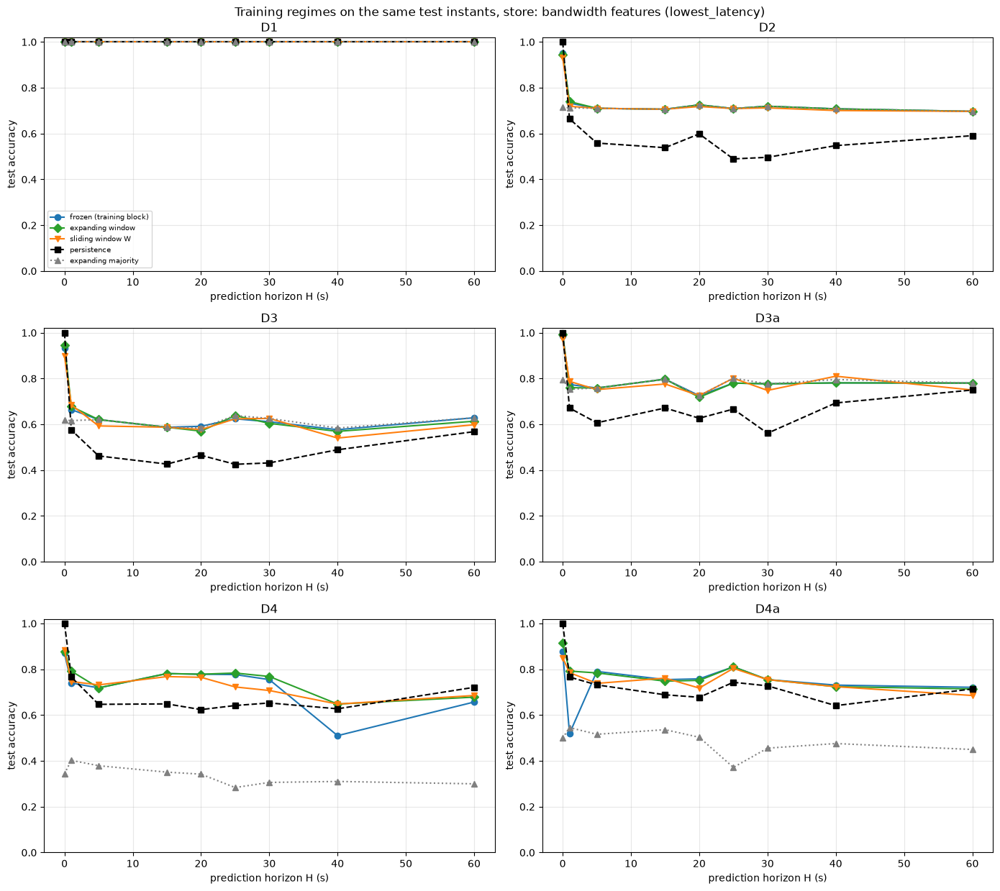

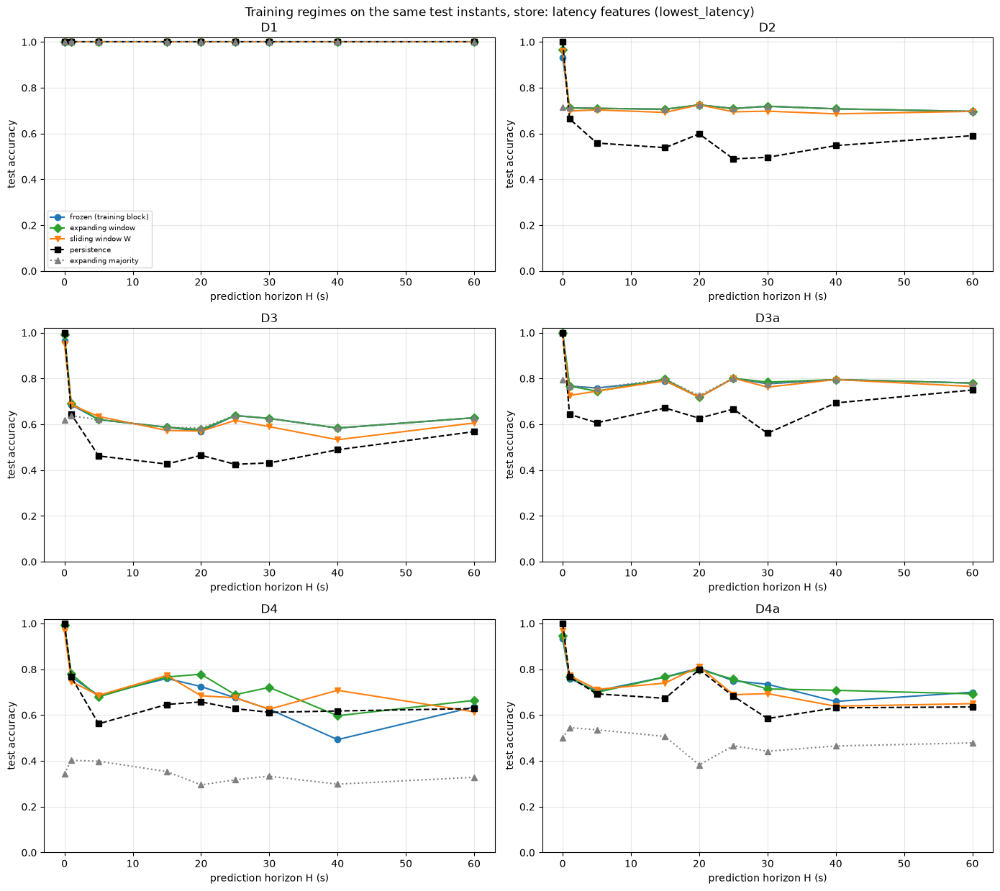

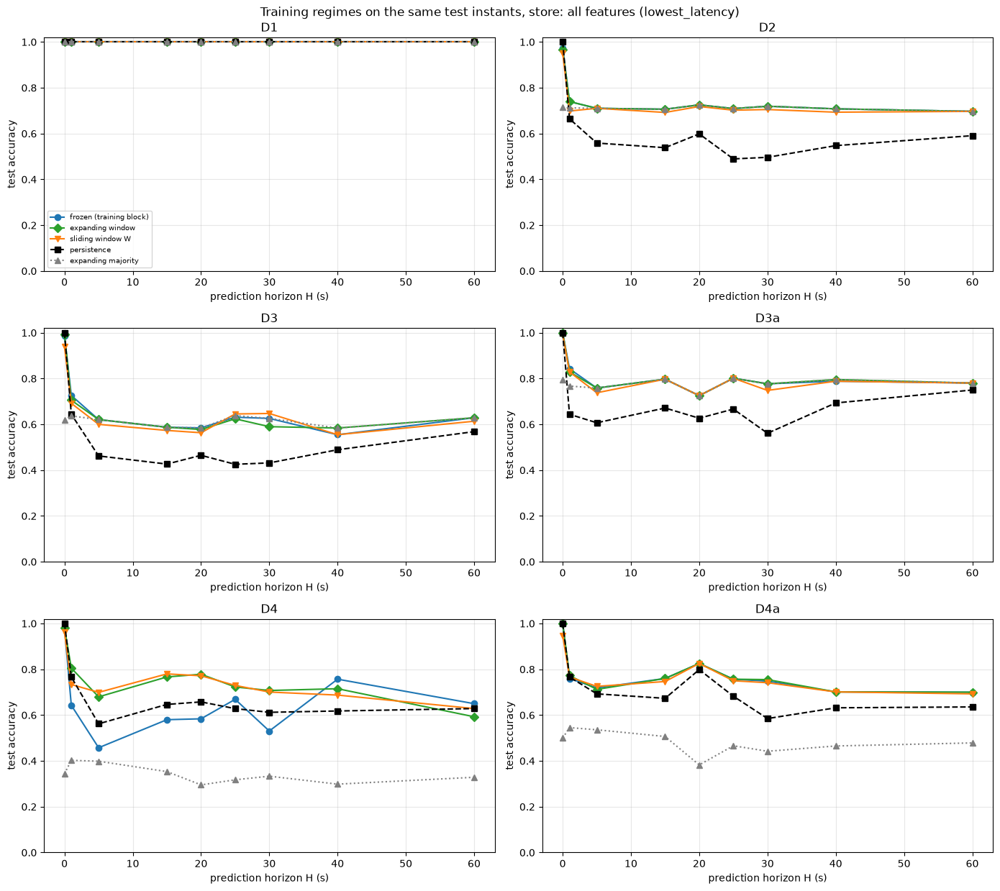

In [58]:
def plot_training_regimes_fs(regimes, datasets, feature_set, title, path=None):
    """Accuracy of the three training regimes against H, on the same test instants."""
    curves = [('frozen accuracy', 'o-', 'tab:blue', 'frozen (training block)'),
              ('expanding accuracy', 'D-', 'tab:green', 'expanding window'),
              ('sliding accuracy', 'v-', 'tab:orange', 'sliding window W'),
              ('persistence', 's--', 'black', 'persistence'),
              ('expanding majority', '^:', 'gray', 'expanding majority')]
    fig, axes = _dataset_panels_fs(datasets)
    for axis, dataset in zip(axes.ravel(), datasets):
        cases = regimes.loc[(dataset, feature_set)]
        for column, style, color, label in curves:
            if column in cases:
                axis.plot(cases.index, cases[column], style, color=color, label=label)
        axis.set_title(dataset)
        axis.set_xlabel('prediction horizon H (s)')
        axis.set_ylabel('test accuracy')
        axis.set_ylim(0, 1.02)
        axis.grid(alpha=0.3)

    axes[0][0].legend(fontsize=7, loc='lower left')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


for target in targets:
    for feature_set in feature_sets:
        plot_training_regimes_fs(
            regimes_fs[target], datasets, feature_set,
            f'Training regimes on the same test instants, {feature_set} ({target})',
            path=(RESULTS_DIR_EXP[target]
                  / f'training_regimes_{feature_set.split(": ")[1].replace(" ", "_")}.png'))